# Entrenamiento de Red Neuronal Enfocado a Salud Mental en Estudiantes Universitarios

Estudiantes:
- Nicoll Quesada
- Daniel Hurtado
- Santiago Lozano

### Pregunta de Investigación:

- ¿En qué medida variables como el comportamiento del estudiante, estabilidad financiera, ambiente social y desempeño académico pueden utilizarse para realizar una detección temprana de la necesidad de ayuda psicológica?

### Contexto del problema y variable objetivo

- **Origen de los datos.** El conjunto proviene de *Self-reported subjective well-being and mental health of college students – 2022* (Mendeley Data, Universidad Icesi, 2022; DOI 10.17632/bytb22nf7m.1). Es una encuesta a estudiantes universitarios colombianos con variables demográficas y socioeconómicas, bienestar subjetivo y los instrumentos PSS-10 (estrés percibido), GAD-7 (ansiedad) y PHQ-9 (depresión).
- **Construcción de `riesgo_dep`.** El cuestionario original no trae una etiqueta de riesgo. La etiqueta se construyó aplicando **k-means** al grupo de preguntas de depresión (**PHQ-9**) y asignando 0 = bajo riesgo y 1 = alto riesgo. El resultado tiene 1923 estudiantes sin riesgo (64.3 %) y 1069 con riesgo (35.7 %).
- **Variables de entrada.** Las preguntas PHQ-9 usadas para construir la etiqueta **no** se incluyen como variables de entrada, así que el modelo no ve directamente la información con la que se generó la etiqueta.
- **Posible circularidad parcial.** Sí se incluyen escalas muy relacionadas con la depresión: PSS-10 (estrés), GAD-7 (ansiedad) y la pregunta 12 (qué tan deprimido se sintió el día anterior). Por eso es esperable que estén fuertemente asociadas al objetivo. Esto se debe tener en cuenta al interpretar el desempeño, porque parte de la señal puede venir de medir constructos muy cercanos a los que definen la etiqueta.

## Importación de los datos

Se usa la base de datos descrita en la sección anterior: la encuesta original de Mendeley con la columna `Riesgo de depresion` agregada mediante k-means sobre las preguntas PHQ-9. La importación se encuentra a continuación:

In [1]:
# ============================================================
# IMPORTACIÓN DE LOS DATOS
# Elegir el origen del archivo CSV:
#   "local" -> lee el CSV que está en la misma carpeta del notebook
#   "drive" -> (Google Colab) monta Google Drive y lee el CSV desde allí
#   "subir" -> (Google Colab) abre el selector para subir el archivo
# ============================================================
import io
import os
import pandas as pd

FUENTE_DATOS = "local"   # "local" | "drive" | "subir"

NOMBRE_ARCHIVO = "data_with_depression_risk (1).csv"
RUTA_LOCAL = NOMBRE_ARCHIVO                                   # relativa a la carpeta del notebook
RUTA_DRIVE = f"/content/drive/MyDrive/{NOMBRE_ARCHIVO}"       # ajustar si el archivo está en otra carpeta de Drive

if FUENTE_DATOS == "local":
    if not os.path.exists(RUTA_LOCAL):
        raise FileNotFoundError(f'No se encontró "{RUTA_LOCAL}" en {os.getcwd()}')
    df = pd.read_csv(RUTA_LOCAL)
    print(f'Archivo local "{RUTA_LOCAL}" cargado.')

elif FUENTE_DATOS == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    df = pd.read_csv(RUTA_DRIVE)
    print(f'Archivo de Drive "{RUTA_DRIVE}" cargado.')

elif FUENTE_DATOS == "subir":
    from google.colab import files
    print("Por favor, selecciona el archivo CSV que deseas cargar:")
    uploaded = files.upload()
    for fn in uploaded.keys():
        print(f'Archivo "{fn}" cargado. Leyendo...')
        df = pd.read_csv(io.StringIO(uploaded[fn].decode("utf-8")))

else:
    raise ValueError('FUENTE_DATOS debe ser "local", "drive" o "subir"')

print("DataFrame cargado exitosamente. Las primeras 5 filas son:")
print(df.head())

Archivo local "data_with_depression_risk (1).csv" cargado.
DataFrame cargado exitosamente. Las primeras 5 filas son:
   1. Year of birth:  2. Gender  \
0               2001          1   
1               1999          1   
2               2002          1   
3               2001          2   
4               1999          1   

   3. What is the socio-economic status of your home?  \
0                                                  4    
1                                                  2    
2                                                  5    
3                                                  5    
4                                                  4    

   4. According to your culture, people, or physical features, you are or are recognized as:  \
0                                                  6                                           
1                                                  1                                           
2                                        

Se observa que los nombres de columnas son muy extensos por lo que se abrevia el nombre de columna y se genera un diccionario con las preguntas originales.

In [2]:
# ============================================================
# Abreviación de los nombres de columnas del DataFrame `df`
# y creación de un diccionario de variables en español
# (asume que `df` ya fue cargado en la celda anterior)
# ============================================================
import re
import pandas as pd

# ------------------------------------------------------------
# 1. Diccionario de preguntas: número -> (nombre corto, descripción en español)
# ------------------------------------------------------------
diccionario_preguntas = {
    "1":   ("anio_nac",       "Año de nacimiento"),
    "2":   ("genero",         "Género"),
    "3":   ("estrato",        "Estrato socioeconómico del hogar"),
    "4":   ("etnia",          "Reconocimiento según cultura, pueblo o rasgos físicos"),
    "5.1": ("educ_padre",     "Años de educación del padre"),
    "5.2": ("educ_madre",     "Años de educación de la madre"),
    "6":   ("satisf_vida",    "Satisfacción general con todos los aspectos de la vida"),
    "7":   ("felicidad_ayer", "Qué tan feliz se sintió ayer"),
    "8":   ("risa_ayer",      "Cuánto se rió ayer"),
    "9":   ("aprendio_ayer",  "Si aprendió cosas nuevas o interesantes ayer"),
    "10":  ("disfrute_ayer",  "Cuánto disfrutó las actividades que hizo ayer"),
    "11":  ("preocupacion_ayer", "Qué tan preocupado se sintió ayer"),
    "12":  ("depresion_ayer", "Qué tan deprimido se sintió ayer"),
    "13":  ("ira_ayer",       "Qué tan enojado se sintió ayer"),
    "14":  ("estres_ayer",    "Cuánto estrés sintió ayer"),
    "15":  ("soledad",        "Qué tan solo o sin apoyo se sintió ayer"),
}

# Preguntas 16.x -> Escala de Estrés Percibido (PSS-10)
# Escala 0 a 4: 0 = nunca, 1 = casi nunca, 2 = a veces, 3 = bastante seguido, 4 = muy seguido
# Referencia: durante el último mes
items_pss = [
    "Se ha sentido afectado por algo que ocurrió inesperadamente",
    "Se ha sentido incapaz de controlar las cosas importantes de su vida",
    "Se ha sentido nervioso o estresado",
    "Se ha sentido seguro de su capacidad para manejar sus problemas personales",
    "Ha sentido que las cosas le iban bien",
    "Ha sentido que no podía afrontar todas las cosas que tenía que hacer",
    "Ha podido controlar las dificultades de su vida",
    "Ha sentido que tenía todo bajo control",
    "Se ha enojado por cosas que estaban fuera de su control",
    "Ha sentido que las dificultades se acumulaban tanto que no podía superarlas",
]
for i, texto in enumerate(items_pss, start=1):
    diccionario_preguntas[f"16.{i}"] = (f"pss_{i}", f"Estrés (último mes): {texto}")

# Preguntas 17.x -> Escala de ansiedad GAD-7
# Escala 0 a 3: 0 = nunca, 1 = varios días, 2 = más de la mitad de los días, 3 = casi todos los días
# Referencia: últimas dos semanas
items_gad = [
    "Sentirse nervioso, ansioso o con los nervios de punta",
    "No poder dejar de preocuparse o controlar la preocupación",
    "Preocuparse demasiado por diferentes cosas",
    "Dificultad para relajarse",
    "Estar tan inquieto que es difícil quedarse quieto",
    "Molestarse o irritarse fácilmente",
    "Sentir miedo, como si algo terrible fuera a pasar",
]
for i, texto in enumerate(items_gad, start=1):
    diccionario_preguntas[f"17.{i}"] = (f"gad_{i}", f"Ansiedad (últimas 2 semanas): {texto}")


# ------------------------------------------------------------
# 2. Función que devuelve (nombre corto, descripción) para cada columna
# ------------------------------------------------------------
def abreviar(columna):
    col = columna.strip()

    # Variable objetivo
    if col.lower().startswith("riesgo"):
        return "riesgo_dep", "Riesgo de depresión (variable objetivo: 0 = no, 1 = sí)"

    # Extrae el número de la pregunta al inicio (ej: "5.1", "16.10", "7")
    coincidencia = re.match(r"^(\d+(?:\.\d+)?)", col)
    if coincidencia:
        num = coincidencia.group(1)
        if num in diccionario_preguntas:
            return diccionario_preguntas[num]
        # Preguntas que no están en el diccionario:
        # se les asigna un nombre genérico para completar luego a mano
        return "p" + num.replace(".", "_"), f"Pregunta {num} (pendiente de traducir)"

    # Respaldo: columna sin número -> minúsculas, sin símbolos, máx. 20 caracteres
    return re.sub(r"\W+", "_", col.lower()).strip("_")[:20], "Sin descripción"


# ------------------------------------------------------------
# 3. Construir el mapeo y el diccionario de variables
# ------------------------------------------------------------
resultados = [abreviar(col) for col in df.columns]
mapa_columnas = {orig: corto for orig, (corto, _) in zip(df.columns, resultados)}

diccionario_variables = pd.DataFrame(resultados, columns=["nombre_corto", "descripcion"])

# Verificar que no haya nombres repetidos después de abreviar
duplicados = diccionario_variables["nombre_corto"][
    diccionario_variables["nombre_corto"].duplicated()
].tolist()
if duplicados:
    print("⚠️ Atención: nombres duplicados tras abreviar:", duplicados)

# ------------------------------------------------------------
# 4. Renombrar las columnas del DataFrame
# ------------------------------------------------------------
df = df.rename(columns=mapa_columnas)

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------
pd.set_option("display.max_colwidth", 100)
print("Diccionario de variables:")
display(diccionario_variables)
print("\nPrimeras filas con los nuevos nombres:")
display(df.head())

Diccionario de variables:


,nombre_corto,descripcion
0,anio_nac,Año de nacimiento
1,genero,Género
2,estrato,Estrato socioeconómico del hogar
3,etnia,"Reconocimiento según cultura, pueblo o rasgos físicos"
4,educ_padre,Años de educación del padre
5,educ_madre,Años de educación de la madre
6,satisf_vida,Satisfacción general con todos los aspectos de la vida
7,felicidad_ayer,Qué tan feliz se sintió ayer
8,risa_ayer,Cuánto se rió ayer
9,aprendio_ayer,Si aprendió cosas nuevas o interesantes ayer



Primeras filas con los nuevos nombres:


,anio_nac,genero,estrato,etnia,educ_padre,educ_madre,satisf_vida,felicidad_ayer,risa_ayer,aprendio_ayer,...,pss_9,pss_10,gad_1,gad_2,gad_3,gad_4,gad_5,gad_6,gad_7,riesgo_dep
0,2001,1,4,6,25.0,25.0,7,5,5,5,...,3,1,1,0,0,0,3,0,3,0
1,1999,1,2,1,NaN,NaN,8,4,8,3,...,3,2,0,3,1,1,0,1,1,1
2,2002,1,5,6,16.0,16.0,10,9,10,7,...,1,2,1,2,1,2,1,0,1,0
3,2001,2,5,6,20.0,16.0,10,8,10,10,...,2,1,0,0,1,0,0,1,0,0
4,1999,1,4,5,NaN,NaN,8,6,7,3,...,2,1,1,0,0,0,0,0,1,1


## Análisis exploratorio de datos

In [3]:
print(f"El DataFrame tiene {df.shape[0]} filas y {df.shape[1]} columnas.")

El DataFrame tiene 2992 filas y 34 columnas.


In [4]:
print('Conteo de valores faltantes por columna:')
print(df.isnull().sum())

Conteo de valores faltantes por columna:
anio_nac                0
genero                  0
estrato                 0
etnia                   0
educ_padre            954
educ_madre           1059
satisf_vida             0
felicidad_ayer          0
risa_ayer               0
aprendio_ayer           0
disfrute_ayer           0
preocupacion_ayer       0
depresion_ayer          0
ira_ayer                0
estres_ayer             0
soledad                 0
pss_1                   0
pss_2                   0
pss_3                   0
pss_4                   0
pss_5                   0
pss_6                   0
pss_7                   0
pss_8                   0
pss_9                   0
pss_10                  0
gad_1                   0
gad_2                   0
gad_3                   0
gad_4                   0
gad_5                   0
gad_6                   0
gad_7                   0
riesgo_dep              0
dtype: int64


In [5]:
print("Distribución de la variable objetivo:")
print(df["riesgo_dep"].value_counts().rename("conteo").to_frame()
      .assign(proporcion=lambda t: (t["conteo"] / t["conteo"].sum()).round(4)))

Distribución de la variable objetivo:
            conteo  proporcion
riesgo_dep                    
0             1923      0.6427
1             1069      0.3573


Se observa que dos columnas tienen valores faltantes: los años de educación del padre y de la madre. Estos faltantes se consideran datos MNAR (no faltan al azar) que no se pueden inferir de forma confiable. Además, faltan en más del 30 % de las filas, lo que justifica eliminar ambas columnas en lugar de imputarlas.

In [6]:
df = df.drop(columns=['educ_padre', 'educ_madre'])
print("Columnas 'educ_padre' y 'educ_madre' eliminadas.")
print(f"El DataFrame ahora tiene {df.shape[1]} columnas.")

Columnas 'educ_padre' y 'educ_madre' eliminadas.
El DataFrame ahora tiene 32 columnas.


También se observó que las categorías de la columna `etnia` usan una codificación numérica simple (1 a 6) para categorías que no tienen orden. Esto se corrige con *one-hot encoding*, que agrega 6 columnas binarias, una por etnia.

In [7]:
# Códigos de la pregunta 4 (etnia) con su etiqueta en español
etiquetas_etnia = {1: "indigena", 2: "gitano", 3: "raizal",
                   4: "palenquero", 5: "afrocolombiano", 6: "ninguno"}

# Cambiar los códigos por etiquetas y aplicar one-hot encoding (0/1)
dummies_etnia = pd.get_dummies(df["etnia"].map(etiquetas_etnia), prefix="etnia", dtype=int)

# Garantizar las 6 columnas aunque alguna categoría no aparezca en los datos
dummies_etnia = dummies_etnia.reindex(columns=[f"etnia_{v}" for v in etiquetas_etnia.values()], fill_value=0)

# Unir al DataFrame y eliminar la columna original
df = pd.concat([df.drop(columns="etnia"), dummies_etnia], axis=1)
display(df.filter(like="etnia_").head())

,etnia_indigena,etnia_gitano,etnia_raizal,etnia_palenquero,etnia_afrocolombiano,etnia_ninguno
0,0,0,0,0,0,1
1,1,0,0,0,0,0
2,0,0,0,0,0,1
3,0,0,0,0,0,1
4,0,0,0,0,1,0


## Preparación de los datos para entrenamiento

Los conjuntos se definen **una sola vez** en esta sección:

1. Split **estratificado** 80/20 entre entrenamiento (`X_train`) y prueba (`X_test`), con `random_state=42`.
2. Split **estratificado** 80/20 de `X_train` entre entrenamiento de los experimentos (`X_train_exp`) y validación (`X_val`).
3. El escalado se ajusta **solo con `X_train_exp`** y después se aplica a validación y prueba.

**Corrección de fuga de información.** En la versión anterior el `StandardScaler` se ajustaba con todo `X_train`, que incluye las filas de validación. Así, la media y la desviación estándar usadas para escalar ya habían visto los datos de validación. Ahora la validación se separa antes de escalar.

La función `preparar_conjuntos(estrategia)` devuelve los tensores de cada conjunto para cuatro estrategias de escalado. Las columnas binarias (`genero` y las dummies de `etnia`) nunca se escalan:

| Estrategia | Transformación |
|---|---|
| `sin_escalar` | Datos crudos |
| `parcial` | `StandardScaler` solo en `anio_nac` y `estrato` (lo que se hacía antes) |
| `estandar_completo` | `StandardScaler` en todas las columnas no binarias |
| `minmax_completo` | `MinMaxScaler` (0–1) en todas las columnas no binarias |

El conjunto de prueba solo se usa en la sección **Evaluación final en prueba**.

In [8]:
# ============================================================
# DEFINICIÓN ÚNICA DE LOS CONJUNTOS
# ============================================================
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

SEED = 42

# ------------------------------------------------------------
# 1. Separar características (X) y variable objetivo (y)
# ------------------------------------------------------------
X = df.drop(columns="riesgo_dep")
y = df["riesgo_dep"].astype(int)

# Variable binaria en formato 0/1: genero 1 -> 0, 2 -> 1
assert X["genero"].isin([1, 2]).all()
X["genero"] = X["genero"].map({1: 0, 2: 1})

# ------------------------------------------------------------
# 2. Split estratificado entrenamiento / prueba (80/20)
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# ------------------------------------------------------------
# 3. Split estratificado entrenamiento de experimentos / validación
#    (80/20 de X_train). Se hace ANTES de escalar.
# ------------------------------------------------------------
X_train_exp_df, X_val_df, y_train_exp_s, y_val_s = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

columnas_binarias = ["genero"] + [c for c in X.columns if c.startswith("etnia_")]
columnas_no_binarias = [c for c in X.columns if c not in columnas_binarias]
columnas_parcial = ["anio_nac", "estrato"]

resumen_split = pd.DataFrame({
    "Conjunto": ["Entrenamiento (experimentos)", "Validación", "Prueba"],
    "Filas": [len(X_train_exp_df), len(X_val_df), len(X_test)],
    "Proporción clase 1": [y_train_exp_s.mean(), y_val_s.mean(), y_test.mean()],
}).round(4)
display(resumen_split)
print(f"Columnas binarias (no se escalan): {len(columnas_binarias)}")
print(f"Columnas no binarias: {len(columnas_no_binarias)}")

,Conjunto,Filas,Proporción clase 1
0,Entrenamiento (experimentos),1914,0.3574
1,Validación,479,0.3570
2,Prueba,599,0.3573


Columnas binarias (no se escalan): 7
Columnas no binarias: 29


In [9]:
# ============================================================
# ESTRATEGIAS DE ESCALADO
# El escalador se ajusta SOLO con X_train_exp y se aplica a
# validación y prueba.
# ============================================================
ESTRATEGIAS_ESCALADO = ["sin_escalar", "parcial", "estandar_completo", "minmax_completo"]


def _tensor_X(tabla):
    return torch.tensor(tabla.values, dtype=torch.float32)


def _tensor_y(serie):
    # Etiquetas en float32 con forma (N, 1): formato de la pérdida BCE
    return torch.tensor(np.asarray(serie), dtype=torch.float32).view(-1, 1)


def preparar_conjuntos(estrategia):
    X_tr = X_train_exp_df.astype(float).copy()
    X_va = X_val_df.astype(float).copy()
    X_te = X_test.astype(float).copy()

    if estrategia == "sin_escalar":
        columnas, escalador = [], None
    elif estrategia == "parcial":
        columnas, escalador = columnas_parcial, StandardScaler()
    elif estrategia == "estandar_completo":
        columnas, escalador = columnas_no_binarias, StandardScaler()
    elif estrategia == "minmax_completo":
        columnas, escalador = columnas_no_binarias, MinMaxScaler()
    else:
        raise ValueError(f"Estrategia desconocida: {estrategia}")

    if escalador is not None:
        X_tr[columnas] = escalador.fit_transform(X_tr[columnas])
        X_va[columnas] = escalador.transform(X_va[columnas])
        X_te[columnas] = escalador.transform(X_te[columnas])

    return {
        "X_train_exp": _tensor_X(X_tr), "y_train_exp": _tensor_y(y_train_exp_s),
        "X_val": _tensor_X(X_va), "y_val": _tensor_y(y_val_s),
        "X_test": _tensor_X(X_te), "y_test": _tensor_y(y_test),
    }


CONJUNTOS = {e: preparar_conjuntos(e) for e in ESTRATEGIAS_ESCALADO}


def usar_estrategia(estrategia):
    """Deja como conjuntos activos (globales) los de entrenamiento y validación de la estrategia."""
    global X_train_exp, y_train_exp, X_val, y_val, ESTRATEGIA
    c = CONJUNTOS[estrategia]
    X_train_exp, y_train_exp = c["X_train_exp"], c["y_train_exp"]
    X_val, y_val = c["X_val"], c["y_val"]
    ESTRATEGIA = estrategia


# Hasta el experimento de escalado se usa la estrategia anterior ("parcial")
usar_estrategia("parcial")
input_size = X_train_exp.shape[1]

print(f"X_train_exp: {tuple(X_train_exp.shape)} | y_train_exp: {tuple(y_train_exp.shape)}")
print(f"X_val:       {tuple(X_val.shape)} | y_val:       {tuple(y_val.shape)}")
print(f"Número de variables de entrada (input_size): {input_size}")

X_train_exp: (1914, 36) | y_train_exp: (1914, 1)
X_val:       (479, 36) | y_val:       (479, 1)
Número de variables de entrada (input_size): 36


## Infraestructura común de modelado

Todo el modelado se hace en **PyTorch**, con el mismo framework, el mismo split y el mismo protocolo para todos los modelos:

- `fijar_semilla(seed)`: fija `random`, `numpy` y `torch` (`SEED = 42`). Se llama antes de crear cada modelo y antes de cada entrenamiento.
- `MLP(input_size, hidden_layers, dropout)`: red con salida de 1 neurona (logit). `hidden_layers=[]` es el perceptrón (regresión logística). Si `dropout > 0` se agrega `nn.Dropout(p)` después de cada ReLU.
- `crear_modelo(...)`: crea la red y le carga los **pesos iniciales de su arquitectura** (guardados una sola vez con `copy.deepcopy(state_dict())`). Todas las corridas de una misma arquitectura parten de los mismos pesos.
- `entrenar_modelo(...)`: única función de entrenamiento, con regularización L1/L2 solo sobre los pesos, `pos_weight` opcional y *early stopping* que restaura los pesos de la mejor época. El `DataLoader` usa un generador con semilla, así que el orden de los mini-batches es el mismo en todas las corridas.
- Las pérdidas que se registran y grafican son siempre la **BCE pura, sin ponderar y sin penalización**, para que todas las corridas sean comparables. Las métricas de entrenamiento de cada época se calculan en modo `eval()` sobre todo `X_train_exp`, porque con dropout el promedio de los mini-batches en modo `train()` subestima el desempeño.
- `evaluar(...)`, `graficar_curvas(...)` y `tabla_resumen(...)`: evaluación, gráficas y tablas comunes.

In [10]:
# ============================================================
# SEMILLA, MODELO Y PESOS INICIALES
# ============================================================
import copy
import random
import time
import itertools
import warnings

import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 300)
warnings.filterwarnings("ignore", category=UserWarning)


def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


fijar_semilla(SEED)
# Las redes son pequeñas: con un solo hilo de CPU el entrenamiento es más rápido
torch.set_num_threads(1)


class MLP(nn.Module):
    """Perceptrón multicapa con salida de 1 neurona (logit).
    hidden_layers=[] equivale a una regresión logística (perceptrón)."""
    salida_probabilidad = False

    def __init__(self, input_size, hidden_layers, dropout=0.0):
        super().__init__()
        capas = []
        previo = input_size
        for n_neuronas in hidden_layers:
            capas.append(nn.Linear(previo, n_neuronas))
            capas.append(nn.ReLU())
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            previo = n_neuronas
        capas.append(nn.Linear(previo, 1))
        self.network = nn.Sequential(*capas)
        self.hidden_layers = list(hidden_layers)
        self.dropout = dropout

    def forward(self, x):
        return self.network(x)


class MLPSigmoide(MLP):
    """Variante usada SOLO en el experimento de función de pérdida (BCELoss):
    aplica la sigmoide dentro del modelo y devuelve probabilidades."""
    salida_probabilidad = True

    def forward(self, x):
        return torch.sigmoid(self.network(x))


PESOS_INICIALES = {}


def pesos_iniciales(hidden_layers):
    """state_dict inicial de cada arquitectura, creado una sola vez con la semilla global."""
    clave = tuple(hidden_layers)
    if clave not in PESOS_INICIALES:
        fijar_semilla(SEED)
        referencia = MLP(input_size, hidden_layers)
        PESOS_INICIALES[clave] = copy.deepcopy(referencia.state_dict())
    return PESOS_INICIALES[clave]


def crear_modelo(hidden_layers, dropout=0.0, clase=MLP):
    """Crea la red y copia los pesos iniciales de su arquitectura capa lineal por capa lineal
    (con dropout cambian los índices del nn.Sequential, por eso no se usa load_state_dict)."""
    fijar_semilla(SEED)
    modelo = clase(input_size, hidden_layers, dropout)
    ref = pesos_iniciales(hidden_layers)
    pesos = [v for k, v in ref.items() if k.endswith("weight")]
    sesgos = [v for k, v in ref.items() if k.endswith("bias")]
    lineales = [m for m in modelo.network if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for capa, w, b in zip(lineales, pesos, sesgos):
            capa.weight.copy_(w)
            capa.bias.copy_(b)
    return modelo


BATCH_SIZE = 32
NOMBRES_OPTIMIZADORES = ["GD", "Mini-Batch GD", "SGD con momentum", "AdaGrad", "RMSProp", "Adam"]


def crear_optimizador(nombre, parametros, lr):
    if nombre in ("GD", "Mini-Batch GD"):
        return torch.optim.SGD(parametros, lr=lr)
    if nombre == "SGD con momentum":
        return torch.optim.SGD(parametros, lr=lr, momentum=0.9)
    if nombre == "AdaGrad":
        return torch.optim.Adagrad(parametros, lr=lr)
    if nombre == "RMSProp":
        return torch.optim.RMSprop(parametros, lr=lr)
    if nombre == "Adam":
        return torch.optim.Adam(parametros, lr=lr)
    raise ValueError(f"Optimizador desconocido: {nombre}")


def tamano_batch(nombre_optimizador, n_muestras):
    # GD = descenso de gradiente con TODO el conjunto de entrenamiento en cada paso
    return n_muestras if nombre_optimizador == "GD" else BATCH_SIZE


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

In [11]:
# ============================================================
# EVALUACIÓN
# ============================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, confusion_matrix,
    precision_recall_curve, roc_curve, classification_report,
    ConfusionMatrixDisplay
)


def perdida_bce(modelo, salida, y):
    """BCE pura (sin ponderar) a partir de la salida del modelo (logit o probabilidad)."""
    if modelo.salida_probabilidad:
        return F.binary_cross_entropy(salida.clamp(1e-7, 1 - 1e-7), y)
    return F.binary_cross_entropy_with_logits(salida, y)


def a_probabilidad(modelo, salida):
    return salida if modelo.salida_probabilidad else torch.sigmoid(salida)


def _metricas_rapidas(proba, y, umbral=0.5):
    """Accuracy y F1 de la clase 1 en torch (se calculan en cada época)."""
    pred = (proba >= umbral).float()
    tp = ((pred == 1) & (y == 1)).sum().item()
    fp = ((pred == 1) & (y == 0)).sum().item()
    fn = ((pred == 0) & (y == 1)).sum().item()
    acc = (pred == y).float().mean().item()
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0
    return acc, f1


def evaluar(modelo, X, y, umbral=0.5):
    """Pérdida BCE, accuracy, precision, recall, F1 y balanced accuracy (clase 1) y AUC."""
    modelo.eval()
    with torch.no_grad():
        salida = modelo(X)
        loss = perdida_bce(modelo, salida, y).item()
        proba = a_probabilidad(modelo, salida).view(-1).numpy()
    y_np = y.view(-1).numpy().astype(int)
    pred = (proba >= umbral).astype(int)
    return {
        "loss": loss,
        "accuracy": accuracy_score(y_np, pred),
        "precision": precision_score(y_np, pred, zero_division=0),
        "recall": recall_score(y_np, pred, zero_division=0),
        "f1": f1_score(y_np, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_np, pred),
        "auc": roc_auc_score(y_np, proba),
        "umbral": umbral,
        "proba": proba,
        "pred": pred,
    }

In [12]:
# ============================================================
# FUNCIÓN ÚNICA DE ENTRENAMIENTO
# ============================================================
def entrenar_modelo(
    modelo,
    optimizador,
    batch_size=BATCH_SIZE,
    max_epocas=150,
    early_stopping=True,
    paciencia=15,
    min_delta=1e-4,
    tipo_reg="Ninguna",
    lambda_reg=0.0,
    pos_weight=None,
    funcion_perdida="BCEWithLogitsLoss",
    nombre="modelo",
):
    """
    Entrena con X_train_exp / y_train_exp y valida con X_val / y_val (conjuntos activos).
    - La penalización L1/L2 se aplica solo a los pesos (no a los sesgos) y solo para el gradiente.
    - El historial guarda la BCE pura (sin pos_weight ni penalización).
    - Early stopping sobre la pérdida de validación con restauración de los mejores pesos.
      Cuando se usa pos_weight, el criterio de parada es la misma pérdida ponderada con la
      que se entrena (evaluada en validación, sin penalización).
    """
    X_tr, y_tr, X_va, y_va = X_train_exp, y_train_exp, X_val, y_val

    if funcion_perdida == "BCELoss":
        assert modelo.salida_probabilidad, "BCELoss requiere un modelo con salida sigmoide"
        criterio = nn.BCELoss()
    else:
        peso = None if pos_weight is None else torch.tensor([float(pos_weight)])
        criterio = nn.BCEWithLogitsLoss(pos_weight=peso)

    fijar_semilla(SEED)
    loader = DataLoader(
        TensorDataset(X_tr, y_tr),
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    pesos_reg = [p for n, p in modelo.named_parameters() if n.endswith("weight")]

    historial = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "train_f1", "val_f1"]}
    mejor_monitor, mejor_epoca, mejor_estado, sin_mejora = float("inf"), 0, None, 0
    inicio = time.time()

    for epoca in range(1, max_epocas + 1):
        # --------- Entrenamiento ---------
        modelo.train()
        for X_batch, y_batch in loader:
            optimizador.zero_grad()
            perdida = criterio(modelo(X_batch), y_batch)
            if tipo_reg == "L1":
                perdida = perdida + lambda_reg * sum(w.abs().sum() for w in pesos_reg)
            elif tipo_reg == "L2":
                perdida = perdida + lambda_reg * sum((w ** 2).sum() for w in pesos_reg)
            perdida.backward()
            optimizador.step()

        # --------- Métricas de la época (modo eval, conjuntos completos) ---------
        modelo.eval()
        with torch.no_grad():
            for conjunto, Xc, yc in (("train", X_tr, y_tr), ("val", X_va, y_va)):
                salida = modelo(Xc)
                historial[f"{conjunto}_loss"].append(perdida_bce(modelo, salida, yc).item())
                acc, f1 = _metricas_rapidas(a_probabilidad(modelo, salida), yc)
                historial[f"{conjunto}_acc"].append(acc)
                historial[f"{conjunto}_f1"].append(f1)
            monitor = criterio(salida, y_va).item()   # 'salida' es la de validación

        # --------- Early stopping ---------
        if monitor < mejor_monitor - min_delta:
            mejor_monitor, mejor_epoca, sin_mejora = monitor, epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
        if early_stopping and sin_mejora >= paciencia:
            break

    epoca_parada = epoca
    if early_stopping and mejor_estado is not None:
        modelo.load_state_dict(mejor_estado)

    return {
        "nombre": nombre,
        "modelo": modelo,
        "historial": historial,
        "early_stopping": early_stopping,
        "mejor_epoca": mejor_epoca,
        "epoca_parada": epoca_parada,
        # época de la que salen los pesos devueltos
        "epoca_modelo": mejor_epoca if early_stopping else epoca_parada,
        "parametros": contar_parametros(modelo),
        "tiempo_s": time.time() - inicio,
        "metricas_train": evaluar(modelo, X_tr, y_tr),
        "metricas_val": evaluar(modelo, X_va, y_va),
    }


def correr(nombre, hidden_layers, optimizador="Mini-Batch GD", lr=0.01, dropout=0.0,
           tipo_reg="Ninguna", lambda_reg=0.0, pos_weight=None, early_stopping=True,
           max_epocas=150, clase=MLP, funcion_perdida="BCEWithLogitsLoss"):
    """Atajo: crea el modelo con sus pesos iniciales, el optimizador, y lo entrena."""
    modelo = crear_modelo(hidden_layers, dropout=dropout, clase=clase)
    opt = crear_optimizador(optimizador, modelo.parameters(), lr)
    return entrenar_modelo(
        modelo, opt,
        batch_size=tamano_batch(optimizador, len(X_train_exp)),
        max_epocas=max_epocas, early_stopping=early_stopping,
        tipo_reg=tipo_reg, lambda_reg=lambda_reg, pos_weight=pos_weight,
        funcion_perdida=funcion_perdida, nombre=nombre,
    )


def mejor_por_val_loss(resultados):
    """Criterio de los experimentos de un solo factor: menor pérdida BCE de validación."""
    return min(resultados, key=lambda k: resultados[k]["metricas_val"]["loss"])

In [13]:
# ============================================================
# TABLAS Y GRÁFICAS REUTILIZABLES
# ============================================================
def _como_dict(resultados):
    if isinstance(resultados, dict) and "historial" in resultados:
        return {resultados["nombre"]: resultados}
    if isinstance(resultados, list):
        return {r["nombre"]: r for r in resultados}
    return resultados


def tabla_resumen(resultados):
    """Métricas de train y validación del modelo devuelto (mejor época si hubo early stopping)."""
    filas = []
    for nombre, r in _como_dict(resultados).items():
        mt, mv = r["metricas_train"], r["metricas_val"]
        filas.append({
            "Modelo": nombre,
            "Pérdida train": mt["loss"],
            "Pérdida val": mv["loss"],
            "Accuracy train": mt["accuracy"],
            "Accuracy val": mv["accuracy"],
            "F1 train (clase 1)": mt["f1"],
            "F1 val (clase 1)": mv["f1"],
            "Recall val (clase 1)": mv["recall"],
            "AUC val": mv["auc"],
            "Pérdida val última época": r["historial"]["val_loss"][-1],
            "Early stopping": "Sí" if r["early_stopping"] else "No",
            "Mejor época": r["mejor_epoca"],
            "Época de parada": r["epoca_parada"],
            "Brecha pérdida (val - train)": mv["loss"] - mt["loss"],
            "Brecha accuracy (train - val)": mt["accuracy"] - mv["accuracy"],
            "Parámetros": r["parametros"],
        })
    return pd.DataFrame(filas).set_index("Modelo").round(4)


def graficar_curvas(resultados, titulo, conjunto="ambos"):
    """Pérdida y accuracy por época. Entrenamiento: línea continua; validación: discontinua.
    La línea vertical punteada marca la mejor época cuando hubo early stopping."""
    resultados = _como_dict(resultados)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    marcada = False
    for i, (nombre, r) in enumerate(resultados.items()):
        h = r["historial"]
        color = f"C{i % 10}"
        epocas = range(1, len(h["train_loss"]) + 1)
        for ax, metrica in ((axes[0], "loss"), (axes[1], "acc")):
            if conjunto in ("ambos", "train"):
                ax.plot(epocas, h[f"train_{metrica}"], color=color, linestyle="-",
                        label=f"{nombre} (entrenamiento)")
            if conjunto in ("ambos", "val"):
                ax.plot(epocas, h[f"val_{metrica}"], color=color, linestyle="--",
                        label=f"{nombre} (validación)")
            if r["early_stopping"]:
                ax.axvline(r["mejor_epoca"], color=color, linestyle=":", alpha=0.8,
                           label=None if marcada else "Mejor época (early stopping)")
        marcada = marcada or r["early_stopping"]
    sufijo = {"ambos": "entrenamiento y validación", "train": "entrenamiento", "val": "validación"}[conjunto]
    axes[0].set_title(f"{titulo}\nPérdida BCE ({sufijo})")
    axes[1].set_title(f"{titulo}\nAccuracy ({sufijo})")
    axes[0].set_ylabel("Pérdida BCE")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
    axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.tight_layout()
    plt.show()

## Pruebas de entrenamiento

**Criterio de selección.** En los experimentos de un solo factor se elige la opción con la **menor pérdida BCE de validación en la mejor época**. La pérdida es más estable que la accuracy en un conjunto de validación de 479 muestras: una sola muestra mal clasificada mueve la accuracy 0.21 puntos porcentuales, mientras que la pérdida refleja de forma continua la calidad de las probabilidades. Siempre se reportan también la accuracy, el F1 y el recall de la clase 1. El criterio del pipeline final se define en su propia sección.

Primero se entrena un perceptrón como modelo **baseline**, sobre el cual se intenta mejorar.

### Modelo baseline: perceptrón

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
Perceptrón,0.3605,0.3908,0.8328,0.8351,0.7546,0.7642,0.7485,0.8944,0.3908,No,47,50,0.0303,-0.0023,37


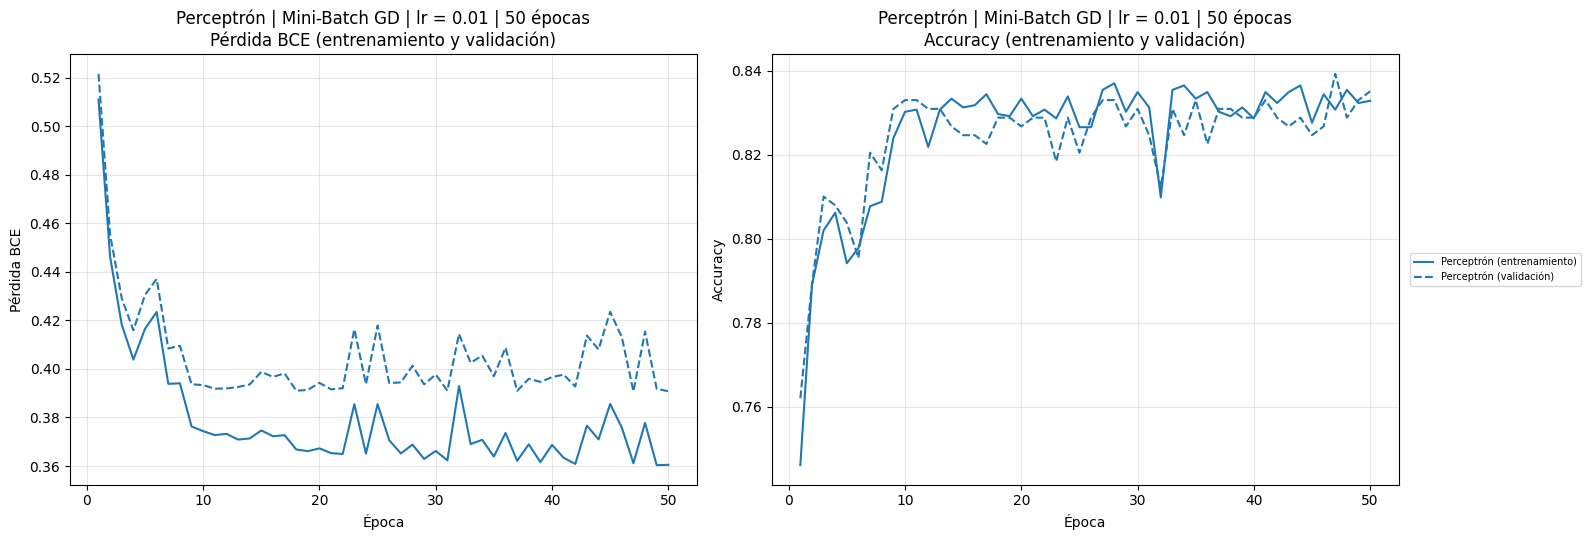

In [14]:
# Perceptrón = MLP sin capas ocultas (equivalente a una regresión logística)
res_perceptron = correr("Perceptrón", [], optimizador="Mini-Batch GD", lr=0.01,
                        early_stopping=False, max_epocas=50)

display(tabla_resumen(res_perceptron))
graficar_curvas(res_perceptron, "Perceptrón | Mini-Batch GD | lr = 0.01 | 50 épocas")

**Observación → Decisión**

- **Observación:** con 50 épocas el perceptrón (37 parámetros) llega a una pérdida de validación de 0.3908, accuracy de 0.8351, F1 de la clase 1 de 0.7642 y recall de 0.7485. La brecha de pérdida entre validación y entrenamiento es pequeña (0.0303) y la mejor época es la 47 de 50, así que todavía estaba mejorando lentamente.
- **Por qué importa:** un modelo lineal ya supera el 83 % de accuracy. Es una referencia exigente, y cualquier red más compleja tiene que justificarse frente a ella.
- **Decisión:** se agrega una capa oculta (red básica `[32]`) con el mismo optimizador, learning rate y número de épocas, para ver si la no linealidad aporta algo.

### Construcción de una red neuronal básica

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
Perceptrón,0.3605,0.3908,0.8328,0.8351,0.7546,0.7642,0.7485,0.8944,0.3908,No,47,50,0.0303,-0.0023,37
Red básica [32],0.3524,0.3869,0.8386,0.8351,0.7639,0.7656,0.7544,0.8969,0.3869,No,47,50,0.0346,0.0035,1217


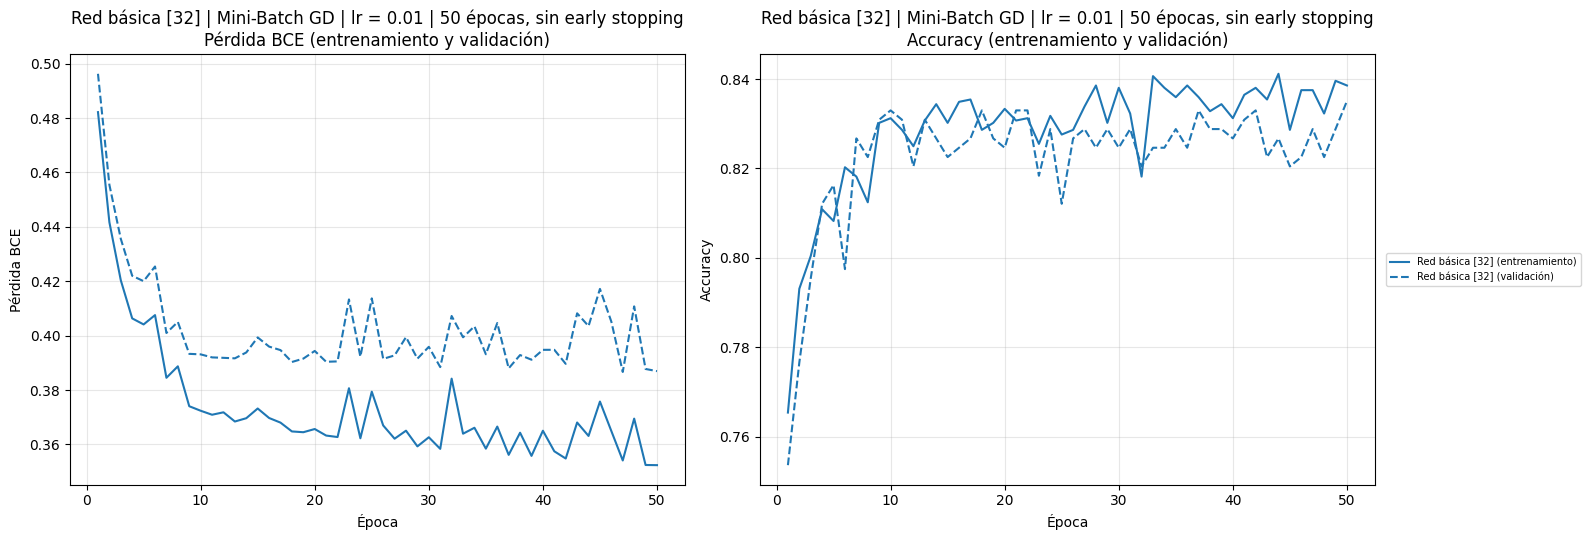

In [15]:
# Red básica: 1 capa oculta de 32 neuronas ReLU, SGD mini-batch, lr = 0.01, 50 épocas, sin early stopping
res_basica = correr("Red básica [32]", [32], optimizador="Mini-Batch GD", lr=0.01,
                    early_stopping=False, max_epocas=50)

display(tabla_resumen([res_perceptron, res_basica]))
graficar_curvas(res_basica, "Red básica [32] | Mini-Batch GD | lr = 0.01 | 50 épocas, sin early stopping")

**Observación → Decisión**

- **Observación:** la red básica (1217 parámetros) apenas mejora al perceptrón: pérdida de validación 0.3869 frente a 0.3908, F1 de 0.7656 frente a 0.7642 y la misma accuracy (0.8351). Las curvas muestran un **aprendizaje inestable**: la pérdida de validación tiene picos de hasta ≈ 0.415 entre las épocas 20 y 50, aunque la de entrenamiento sigue bajando. La brecha de pérdida (0.0346) ya es mayor que la del perceptrón y **aumenta** a medida que el entrenamiento avanza.
- **Por qué importa:** si la pérdida de entrenamiento sigue bajando mientras la de validación se estanca u oscila, la red empieza a memorizar el conjunto de entrenamiento (indicio de sobreajuste). Además, el resultado depende de en qué época se corte el entrenamiento.
- **Decisión:** se introduce **early stopping** sobre la pérdida de validación, con restauración de los pesos de la mejor época, y se compara contra entrenar 150 épocas completas.

### Experimento: early stopping

In [16]:
# ============================================================
# EXPERIMENTO: EARLY STOPPING
# Red básica [32] y red grande [128, 128, 128], hasta 150 épocas,
# con y sin early stopping (mismos pesos iniciales y mismo orden de batches)
# ============================================================
resultados_es = {}
for arq in ([32], [128, 128, 128]):
    for es in (False, True):
        nombre = f"{arq} {'con' if es else 'sin'} early stopping"
        resultados_es[nombre] = correr(nombre, arq, optimizador="Mini-Batch GD", lr=0.01,
                                       early_stopping=es, max_epocas=150)

display(tabla_resumen(resultados_es))

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
[32] sin early stopping,0.3273,0.3998,0.8542,0.8309,0.7872,0.7582,0.7427,0.8930,0.3998,No,47,150,0.0725,0.0233,1217
[32] con early stopping,0.3541,0.3866,0.8375,0.8288,0.7595,0.7545,0.7368,0.8967,0.3927,Sí,47,62,0.0325,0.0087,1217
"[128, 128, 128] sin early stopping",0.2653,0.4275,0.8871,0.8267,0.8361,0.7508,0.7310,0.8853,0.4275,No,50,150,0.1622,0.0604,37889
"[128, 128, 128] con early stopping",0.3744,0.3922,0.8292,0.8288,0.7431,0.7453,0.7018,0.8928,0.3983,Sí,12,27,0.0177,0.0003,37889


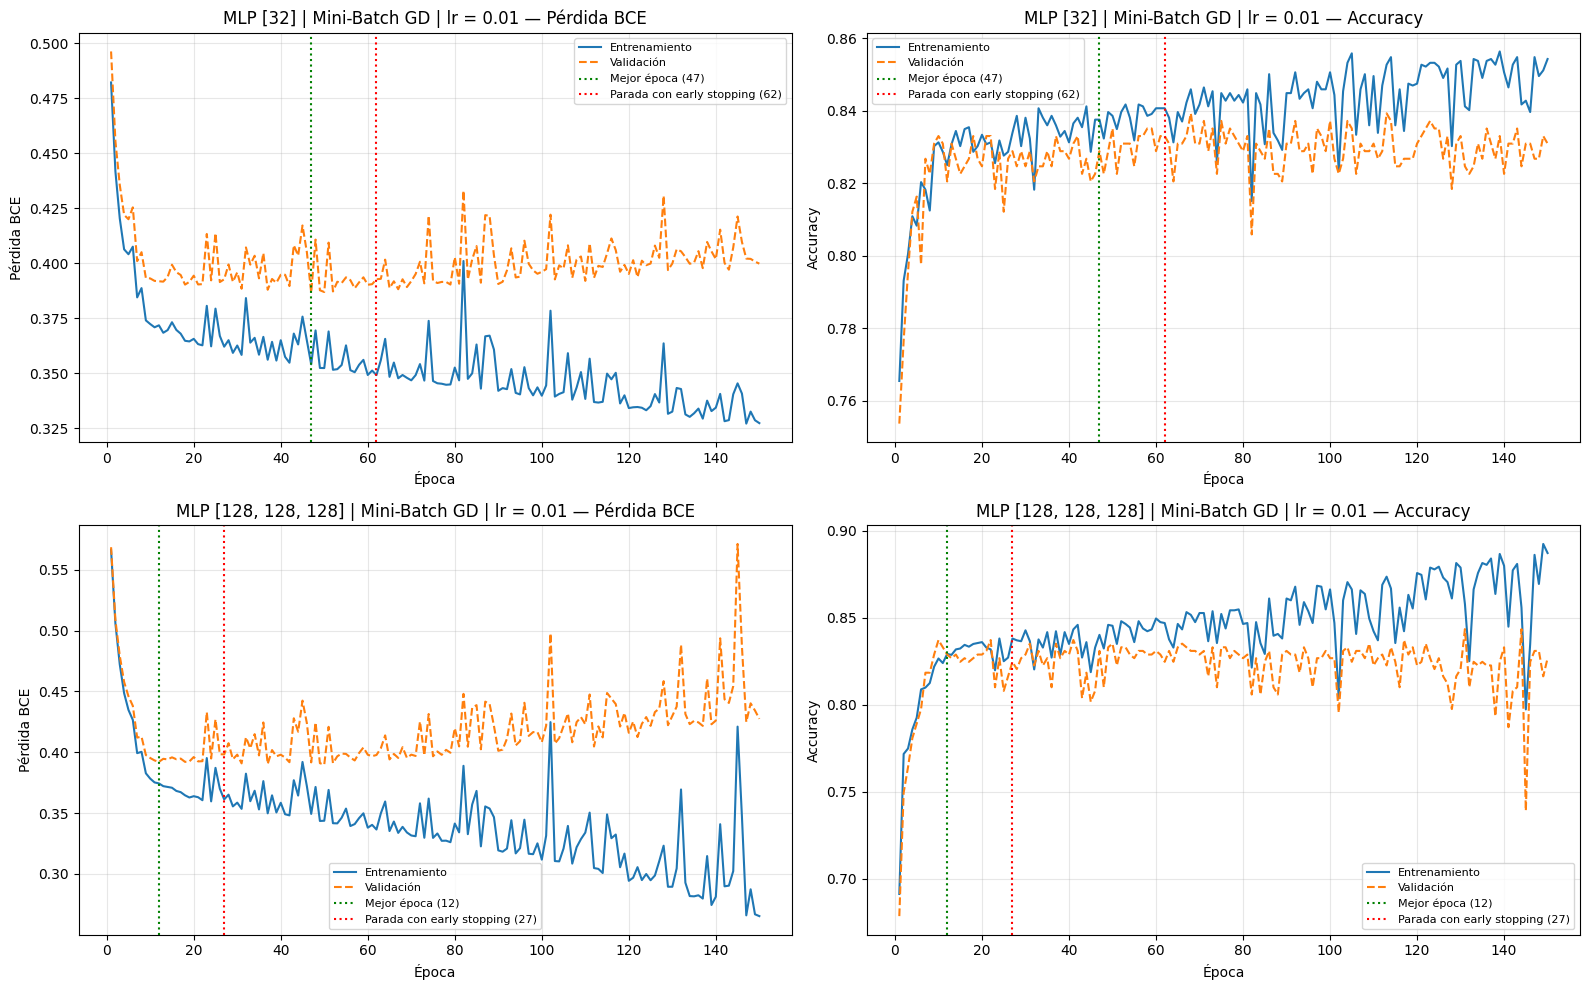

,Pérdida val época 150 (sin ES),Pérdida val mejor época (con ES),Mejor época,Época de parada,Brecha pérdida época 150,Brecha pérdida mejor época
Arquitectura,,,,,,
[32],0.3998,0.3866,47,62,0.0725,0.0325
"[128, 128, 128]",0.4275,0.3922,12,27,0.1622,0.0177


In [17]:
# Curvas completas de 150 épocas (sin early stopping) con la mejor época y la época
# en la que se detiene el entrenamiento con early stopping
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for fila, arq in enumerate(("[32]", "[128, 128, 128]")):
    r_sin = resultados_es[f"{arq} sin early stopping"]
    r_con = resultados_es[f"{arq} con early stopping"]
    h = r_sin["historial"]
    epocas = range(1, len(h["train_loss"]) + 1)
    for col, (metrica, etiqueta) in enumerate((("loss", "Pérdida BCE"), ("acc", "Accuracy"))):
        ax = axes[fila, col]
        ax.plot(epocas, h[f"train_{metrica}"], label="Entrenamiento")
        ax.plot(epocas, h[f"val_{metrica}"], linestyle="--", label="Validación")
        ax.axvline(r_con["mejor_epoca"], color="green", linestyle=":",
                   label=f"Mejor época ({r_con['mejor_epoca']})")
        ax.axvline(r_con["epoca_parada"], color="red", linestyle=":",
                   label=f"Parada con early stopping ({r_con['epoca_parada']})")
        ax.set_title(f"MLP {arq} | Mini-Batch GD | lr = 0.01 — {etiqueta}")
        ax.set_xlabel("Época")
        ax.set_ylabel(etiqueta)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

comparacion_es = pd.DataFrame([{
    "Arquitectura": arq,
    "Pérdida val época 150 (sin ES)": resultados_es[f"{arq} sin early stopping"]["historial"]["val_loss"][-1],
    "Pérdida val mejor época (con ES)": resultados_es[f"{arq} con early stopping"]["metricas_val"]["loss"],
    "Mejor época": resultados_es[f"{arq} con early stopping"]["mejor_epoca"],
    "Época de parada": resultados_es[f"{arq} con early stopping"]["epoca_parada"],
    "Brecha pérdida época 150": (resultados_es[f"{arq} sin early stopping"]["historial"]["val_loss"][-1]
                                 - resultados_es[f"{arq} sin early stopping"]["historial"]["train_loss"][-1]),
    "Brecha pérdida mejor época": (resultados_es[f"{arq} con early stopping"]["metricas_val"]["loss"]
                                   - resultados_es[f"{arq} con early stopping"]["metricas_train"]["loss"]),
} for arq in ("[32]", "[128, 128, 128]")]).set_index("Arquitectura").round(4)
display(comparacion_es)

**Observación → Decisión**

- **Observación:** sin early stopping, al llegar a 150 épocas la brecha de pérdida crece a 0.0725 en `[32]` y a **0.1622** en `[128, 128, 128]`. En esta última la accuracy de entrenamiento llega a 0.8871 mientras la de validación queda en 0.8267. La pérdida de validación en la época 150 (0.3998 y 0.4275) es peor que en la mejor época (0.3866 y 0.3922). La red grande alcanza su mínimo en la época 12 y desde ahí la validación empeora con picos cada vez más grandes. Early stopping detiene `[32]` en la época 62 (mejor época 47) y `[128, 128, 128]` en la 27 (mejor época 12), con brechas de 0.0325 y 0.0177.
- **Por qué importa:** el sobreajuste es claro y crece con la capacidad de la red. Sin un criterio de parada, los experimentos compararían modelos sobreentrenados en épocas arbitrarias.
- **Decisión:** **desde este punto todos los experimentos usan early stopping** (paciencia 15, `min_delta` = 1e-4, máximo 150 épocas) con restauración de los mejores pesos.

### Experimento: escalado de las variables de entrada

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
sin_escalar,0.6520,0.6518,0.6426,0.6430,0.0000,0.0000,0.0000,0.5000,0.6517,Sí,23,38,-0.0002,-0.0004,1217
parcial,0.3541,0.3866,0.8375,0.8288,0.7595,0.7545,0.7368,0.8967,0.3927,Sí,47,62,0.0325,0.0087,1217
estandar_completo,0.3429,0.3873,0.8480,0.8330,0.7817,0.7619,0.7485,0.8974,0.3892,Sí,45,60,0.0444,0.0150,1217
minmax_completo,0.3549,0.3857,0.8333,0.8225,0.7537,0.7416,0.7135,0.8969,0.3867,Sí,149,150,0.0308,0.0108,1217


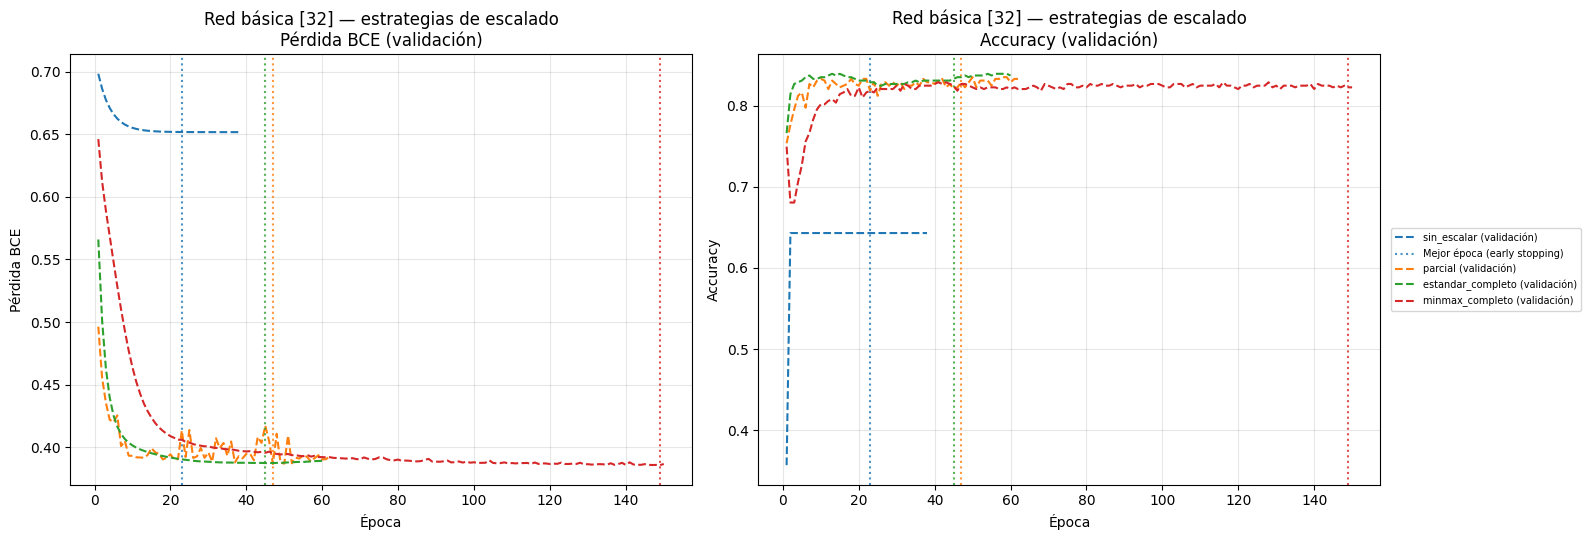

Estrategia elegida (menor pérdida de validación): minmax_completo


In [18]:
# ============================================================
# EXPERIMENTO: ESCALADO
# Red básica [32], Mini-Batch GD, lr = 0.01, batch 32, early stopping.
# Solo cambia la estrategia de escalado.
# ============================================================
resultados_escalado = {}
for estrategia in ESTRATEGIAS_ESCALADO:
    usar_estrategia(estrategia)
    resultados_escalado[estrategia] = correr(estrategia, [32], optimizador="Mini-Batch GD", lr=0.01)

display(tabla_resumen(resultados_escalado))
graficar_curvas(resultados_escalado, "Red básica [32] — estrategias de escalado", conjunto="val")

ESTRATEGIA_ELEGIDA = mejor_por_val_loss(resultados_escalado)
usar_estrategia(ESTRATEGIA_ELEGIDA)
print(f"Estrategia elegida (menor pérdida de validación): {ESTRATEGIA_ELEGIDA}")

**Observación → Decisión**

- **Observación:** sin escalar, la red no aprende: predice siempre la clase 0 (F1 = 0, AUC = 0.50, pérdida de validación 0.6518). `anio_nac` (≈ 2000) domina la entrada y satura las neuronas. Con las tres estrategias que escalan, la pérdida de validación queda casi igual: `minmax_completo` 0.3857, `parcial` 0.3866 y `estandar_completo` 0.3873, una diferencia de 0.0016. `estandar_completo` tiene la mejor accuracy (0.8330) y el mejor F1 (0.7619), mientras que `minmax_completo` necesita las 150 épocas (mejor época 149) porque converge más lento.
- **Por qué importa:** escalar es indispensable. Entre las estrategias que escalan, las diferencias son menores que el ruido de un conjunto de validación de 479 muestras.
- **Decisión:** según el criterio fijado (menor pérdida de validación) se adopta **`minmax_completo`**, que además lleva todas las variables no binarias al mismo rango [0, 1] que las binarias. Todos los experimentos siguientes usan esta estrategia. Su convergencia más lenta se tiene en cuenta al leer las mejores épocas cercanas a 150.

#### Modelos de referencia para la evaluación final

El perceptrón y la red básica se vuelven a entrenar con la estrategia de escalado elegida y con early stopping, que es el protocolo que se usa desde este punto. Así, la comparación final en prueba contra el modelo elegido se hace en igualdad de condiciones.

In [19]:
res_perceptron_ref = correr("Perceptrón", [], optimizador="Mini-Batch GD", lr=0.01)
res_basica_ref = correr("Red básica [32]", [32], optimizador="Mini-Batch GD", lr=0.01)
display(tabla_resumen([res_perceptron_ref, res_basica_ref]))

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
Perceptrón,0.3689,0.3915,0.8302,0.8288,0.7502,0.7515,0.7251,0.8919,0.3915,Sí,149,150,0.0227,0.0014,37
Red básica [32],0.3549,0.3857,0.8333,0.8225,0.7537,0.7416,0.7135,0.8969,0.3867,Sí,149,150,0.0308,0.0108,1217


### Experimento: arquitecturas

In [20]:
# ============================================================
# EXPERIMENTO: ARQUITECTURAS (1–3 capas × 32/64/128 neuronas)
# Mini-Batch GD, lr = 0.01, BCEWithLogitsLoss, early stopping
# ============================================================
arquitecturas = {f"MLP_{n_capas}x{n}": [n] * n_capas for n_capas in (1, 2, 3) for n in (32, 64, 128)}

resultados_arq = {nombre: correr(nombre, capas) for nombre, capas in arquitecturas.items()}
tabla_arq = tabla_resumen(resultados_arq)
display(tabla_arq)

MEJOR_ARQUITECTURA = mejor_por_val_loss(resultados_arq)
print(f"Arquitectura con menor pérdida de validación: {MEJOR_ARQUITECTURA} {arquitecturas[MEJOR_ARQUITECTURA]}")

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
MLP_1x32,0.3549,0.3857,0.8333,0.8225,0.7537,0.7416,0.7135,0.8969,0.3867,Sí,149,150,0.0308,0.0108,1217
MLP_1x64,0.3577,0.3871,0.8333,0.8205,0.7537,0.7394,0.7135,0.8959,0.3872,Sí,115,130,0.0294,0.0129,2433
MLP_1x128,0.3566,0.3862,0.8323,0.8267,0.7529,0.7508,0.7310,0.8957,0.3864,Sí,115,130,0.0296,0.0056,4865
MLP_2x32,0.3525,0.3879,0.8386,0.8288,0.7636,0.7530,0.7310,0.8971,0.3880,Sí,129,144,0.0353,0.0097,2273
MLP_2x64,0.3504,0.3867,0.8359,0.8309,0.7592,0.7538,0.7251,0.8972,0.3868,Sí,129,144,0.0363,0.0050,6593
MLP_2x128,0.3537,0.3853,0.8365,0.8225,0.7609,0.7432,0.7193,0.8973,0.3857,Sí,91,106,0.0316,0.0139,21377
MLP_3x32,0.3494,0.3871,0.8412,0.8372,0.7731,0.7692,0.7602,0.8981,0.3874,Sí,137,150,0.0377,0.0040,3329
MLP_3x64,0.3529,0.3836,0.8401,0.8330,0.7624,0.7561,0.7251,0.8977,0.3861,Sí,90,105,0.0307,0.0071,10753
MLP_3x128,0.3511,0.3847,0.8401,0.8267,0.7639,0.7462,0.7135,0.8979,0.3877,Sí,90,105,0.0336,0.0134,37889


Arquitectura con menor pérdida de validación: MLP_3x64 [64, 64, 64]


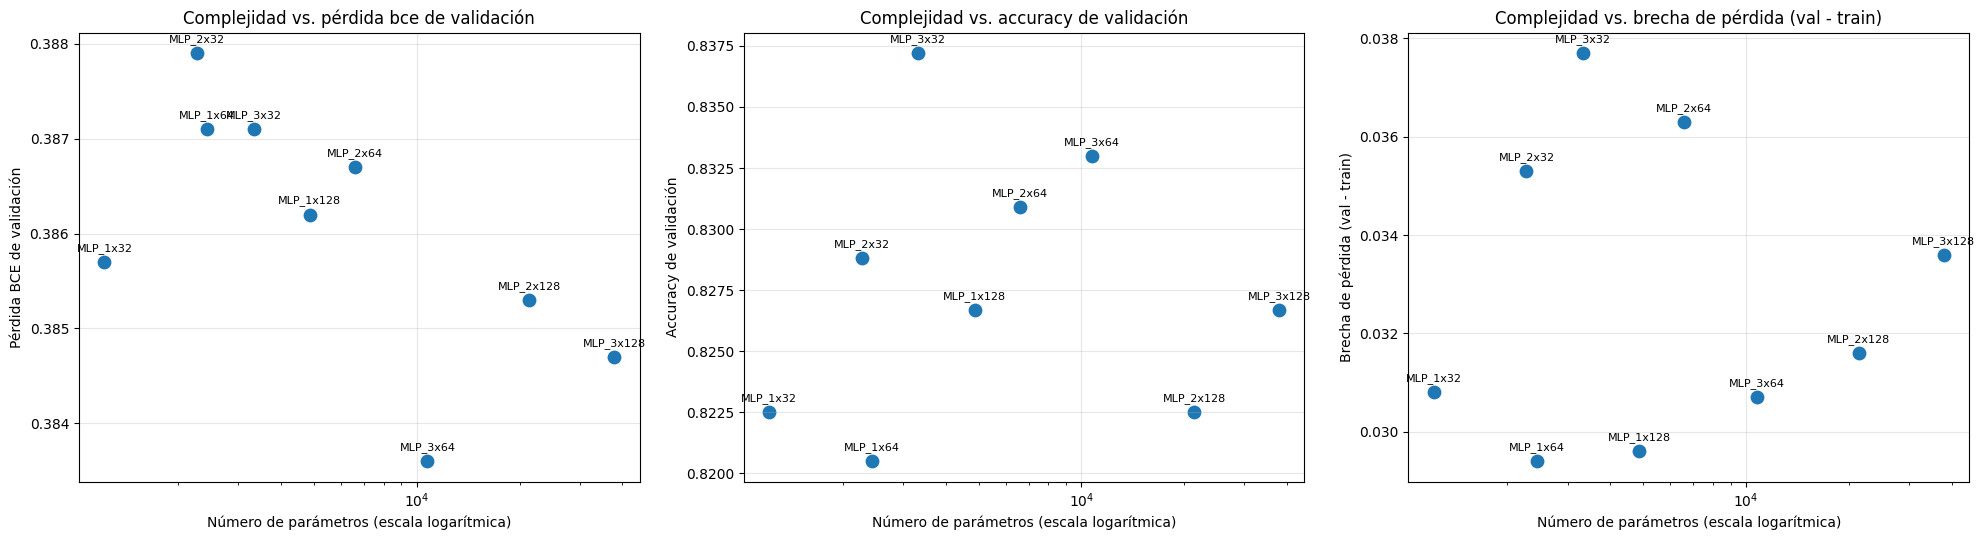

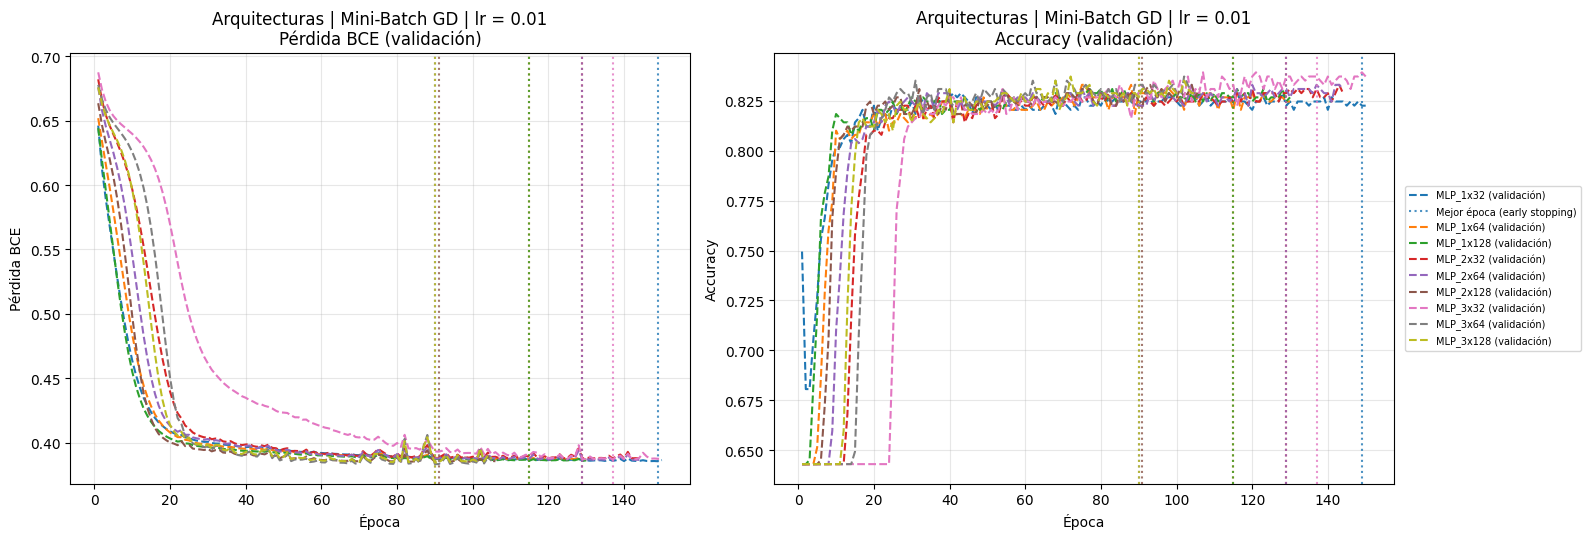

In [21]:
# Complejidad (número de parámetros) vs. desempeño de validación en la mejor época
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (columna, etiqueta) in zip(axes, (("Pérdida val", "Pérdida BCE de validación"),
                                          ("Accuracy val", "Accuracy de validación"),
                                          ("Brecha pérdida (val - train)", "Brecha de pérdida (val - train)"))):
    ax.scatter(tabla_arq["Parámetros"], tabla_arq[columna], s=80)
    for nombre, fila in tabla_arq.iterrows():
        ax.annotate(nombre, (fila["Parámetros"], fila[columna]), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Número de parámetros (escala logarítmica)")
    ax.set_ylabel(etiqueta)
    ax.set_title(f"Complejidad vs. {etiqueta.lower()}")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

graficar_curvas(resultados_arq, "Arquitecturas | Mini-Batch GD | lr = 0.01", conjunto="val")

**Observación → Decisión**

- **Observación:** las 9 arquitecturas quedan en un rango muy estrecho de pérdida de validación, de 0.3836 (`MLP_3x64`, la mejor) a 0.3879 (`MLP_2x32`), y de accuracy, de 0.8205 a 0.8372. Pasar de 1 217 a 37 889 parámetros no mejora la validación. Con early stopping la brecha de pérdida se mantiene entre 0.029 y 0.038 en todas: las redes grandes no sobreajustan más **porque el entrenamiento se corta antes**. Sin early stopping, `[128, 128, 128]` sí sobreajustaba mucho más (brecha de 0.1622 en el experimento anterior). Varias redes, sobre todo las pequeñas, llegan cerca de las 150 épocas por la convergencia lenta de SGD con lr = 0.01 sobre datos en [0, 1].
- **Por qué importa:** la capacidad adicional no se traduce en mejor generalización. Ninguna arquitectura domina con claridad.
- **Decisión:** se registra `MLP_3x64` como la de menor pérdida, pero el pipeline final conserva arquitecturas de distinto tamaño (`[32]`, `[64, 64]`, `[128, 128]` y `[128, 128, 128]`) para comparar la capacidad junto con los demás factores. A igualdad de desempeño se prefiere la red más pequeña (parsimonia).

### Experimento: optimizadores

,Actualizaciones por época,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,,
GD,1,0.6509,0.6514,0.6426,0.6430,0.0000,0.0000,0.0000,0.6440,0.6514,Sí,150,150,0.0005,-0.0004,6593
Mini-Batch GD,60,0.3504,0.3867,0.8359,0.8309,0.7592,0.7538,0.7251,0.8972,0.3868,Sí,129,144,0.0363,0.0050,6593
SGD con momentum,60,0.3483,0.3863,0.8412,0.8330,0.7718,0.7619,0.7485,0.8974,0.3923,Sí,20,35,0.0379,0.0082,6593
AdaGrad,60,0.3477,0.3901,0.8375,0.8267,0.7610,0.7462,0.7135,0.8944,0.3946,Sí,26,41,0.0424,0.0108,6593
RMSProp,60,0.3657,0.3917,0.8344,0.8267,0.7597,0.7537,0.7427,0.8914,0.3962,Sí,3,18,0.0260,0.0077,6593
Adam,60,0.3398,0.3876,0.8412,0.8392,0.7700,0.7688,0.7485,0.8979,0.4537,Sí,19,34,0.0478,0.0019,6593


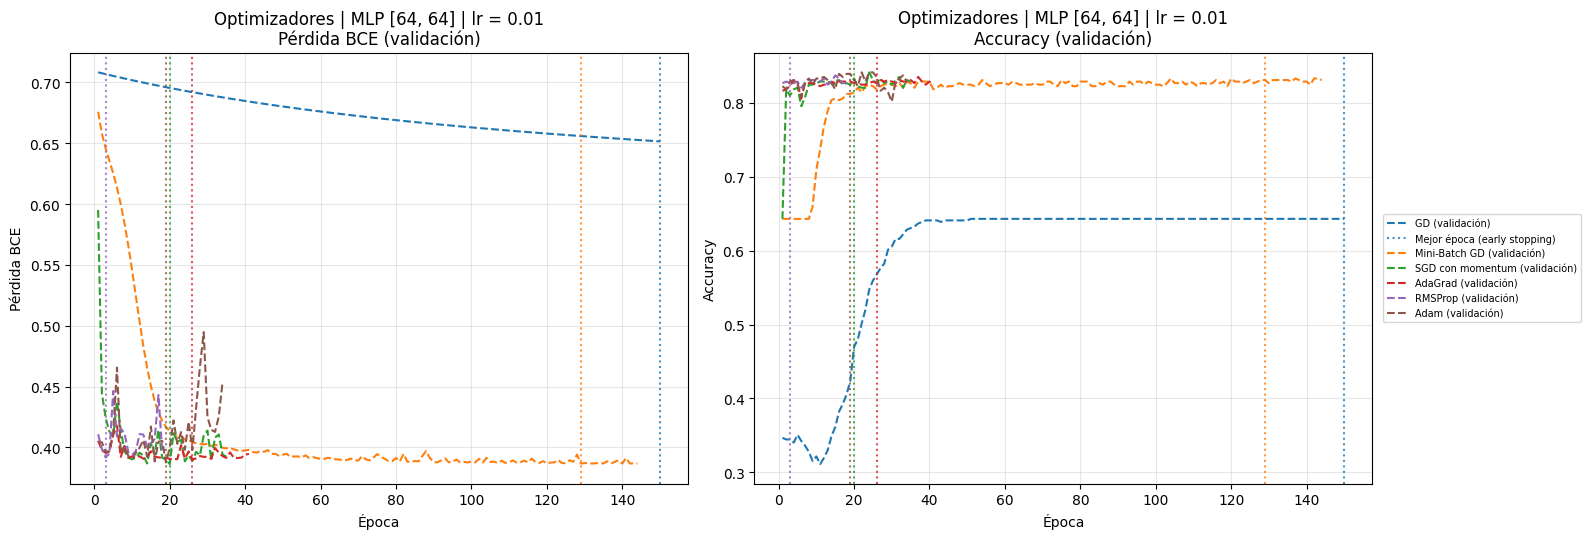

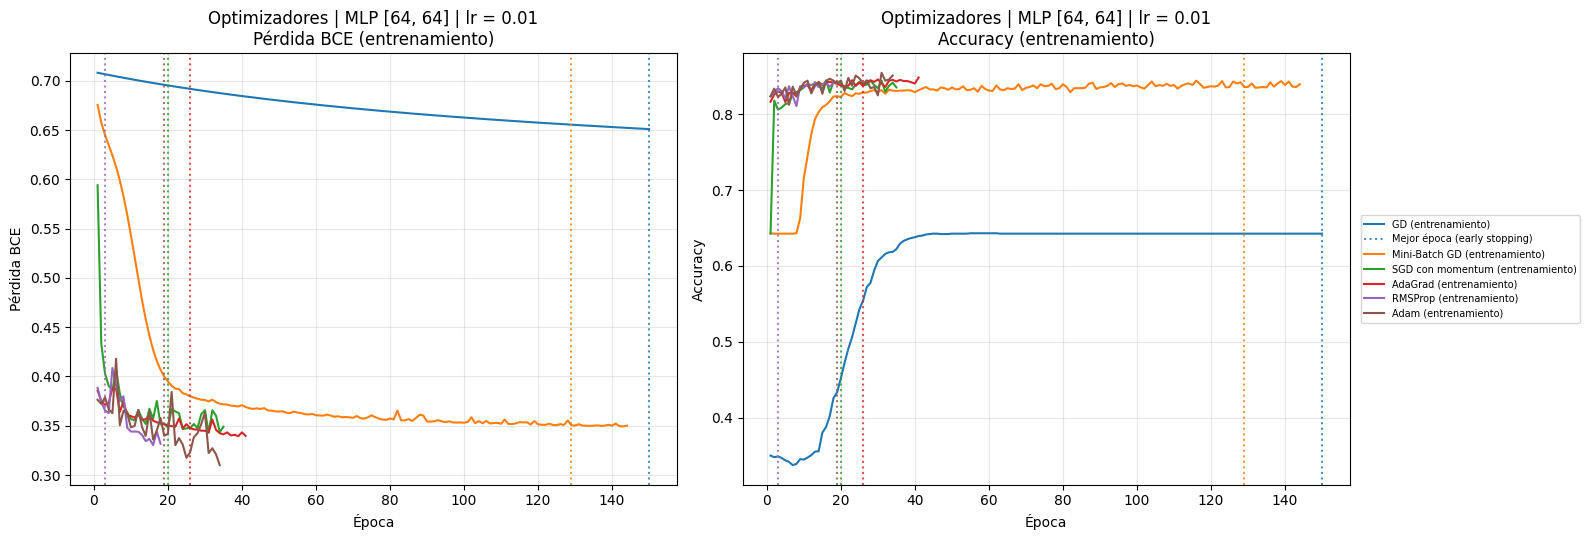

Optimizador con menor pérdida de validación: SGD con momentum


In [22]:
# ============================================================
# EXPERIMENTO: OPTIMIZADORES
# Arquitectura [64, 64], lr = 0.01, mismos pesos iniciales
# ============================================================
resultados_opt = {nombre: correr(nombre, [64, 64], optimizador=nombre, lr=0.01)
                  for nombre in NOMBRES_OPTIMIZADORES}

tabla_opt = tabla_resumen(resultados_opt)
tabla_opt.insert(0, "Actualizaciones por época",
                 [int(np.ceil(len(X_train_exp) / tamano_batch(n, len(X_train_exp)))) for n in tabla_opt.index])
display(tabla_opt)

graficar_curvas(resultados_opt, "Optimizadores | MLP [64, 64] | lr = 0.01", conjunto="val")
graficar_curvas(resultados_opt, "Optimizadores | MLP [64, 64] | lr = 0.01", conjunto="train")

MEJOR_OPTIMIZADOR = mejor_por_val_loss(resultados_opt)
print(f"Optimizador con menor pérdida de validación: {MEJOR_OPTIMIZADOR}")

**Observación → Decisión**

- **Observación:** el GD de batch completo hace **1 actualización por época** frente a 60 del mini-batch. En 150 épocas solo da 150 pasos (el equivalente a 2.5 épocas de mini-batch), así que no sale de predecir siempre la clase 0 (pérdida de validación 0.6514, F1 = 0). Su desventaja viene del **número de actualizaciones**, no de que el algoritmo sea peor. Entre los demás, la mejor pérdida de validación es la de SGD con momentum (0.3863), seguido de Mini-Batch GD (0.3867), Adam (0.3876), AdaGrad (0.3901) y RMSProp (0.3917). Los optimizadores adaptativos llegan a su mínimo muy rápido (RMSProp en la época 3, Adam en la 19) y después la validación empeora: Adam termina con una pérdida de validación de 0.4537 en su última época y tiene la mayor brecha (0.0478).
- **Por qué importa:** los optimizadores rápidos también sobreajustan rápido, así que early stopping es imprescindible con ellos. Las diferencias entre los mejores son del orden de 0.001 en pérdida.
- **Decisión:** se adopta **SGD con momentum** como optimizador de referencia para el bloque de regularización. El pipeline final mantiene AdaGrad, Mini-Batch GD y GD, como estaba definido.

### Experimento: learning rate

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
lr = 0.001,0.4404,0.4496,0.8056,0.7996,0.6853,0.6863,0.6140,0.8777,0.4496,Sí,150,150,0.0092,0.0061,6593
lr = 0.005,0.3571,0.3889,0.8354,0.8246,0.7583,0.7455,0.7193,0.8950,0.3896,Sí,149,150,0.0318,0.0108,6593
lr = 0.01,0.3504,0.3867,0.8359,0.8309,0.7592,0.7538,0.7251,0.8972,0.3868,Sí,129,144,0.0363,0.0050,6593
lr = 0.05,0.3478,0.3861,0.8391,0.8372,0.7667,0.7651,0.7427,0.8974,0.3885,Sí,37,52,0.0383,0.0019,6593
lr = 0.1,0.3548,0.3866,0.8328,0.8225,0.7554,0.7432,0.7193,0.8956,0.3895,Sí,12,27,0.0318,0.0103,6593


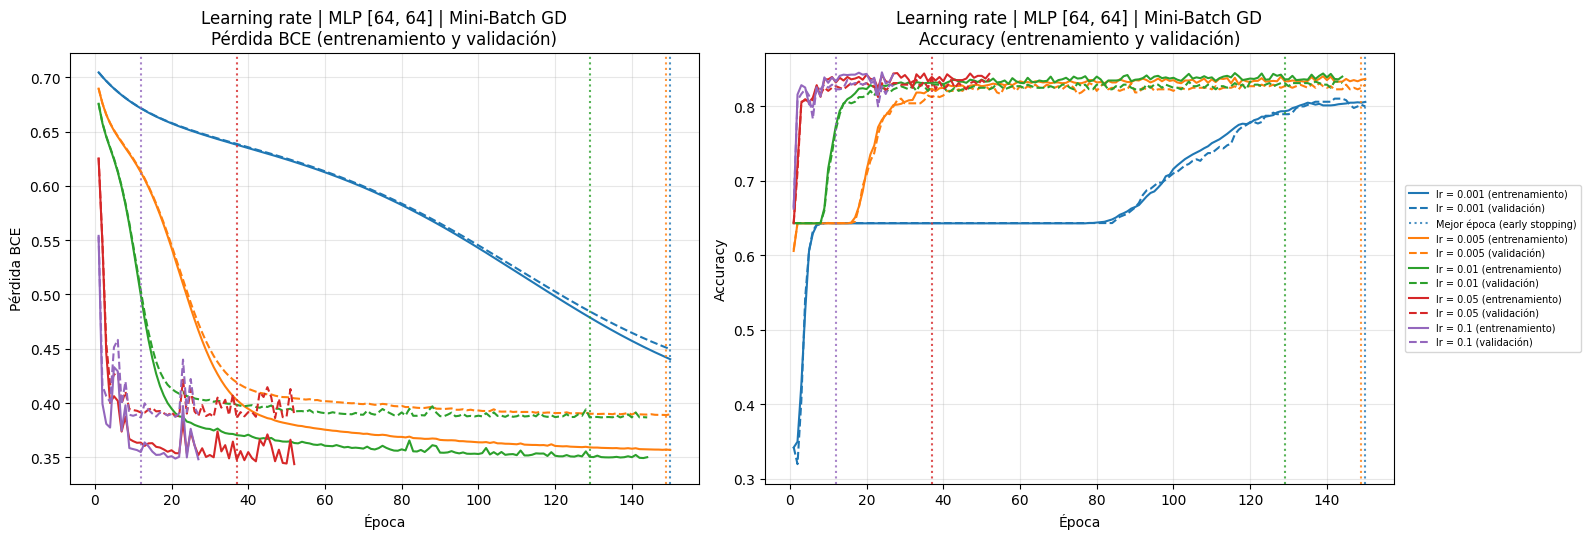

Learning rate con menor pérdida de validación: 0.05


In [23]:
# ============================================================
# EXPERIMENTO: LEARNING RATE
# Mini-Batch GD, arquitectura [64, 64], mismos pesos iniciales
# ============================================================
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]
resultados_lr = {f"lr = {lr}": correr(f"lr = {lr}", [64, 64], optimizador="Mini-Batch GD", lr=lr)
                 for lr in learning_rates}

display(tabla_resumen(resultados_lr))
graficar_curvas(resultados_lr, "Learning rate | MLP [64, 64] | Mini-Batch GD", conjunto="ambos")

MEJOR_LR = float(mejor_por_val_loss(resultados_lr).split("= ")[1])
print(f"Learning rate con menor pérdida de validación: {MEJOR_LR}")

**Observación → Decisión**

- **Observación:** con lr = 0.001 el modelo no converge en 150 épocas (pérdida de validación 0.4496, recall de 0.6140). Con lr = 0.05 se obtiene la menor pérdida de validación (0.3861), el mejor F1 (0.7651) y la mejor accuracy (0.8372), con la mejor época en la 37. Con lr = 0.1 el mínimo llega en la época 12 y el entrenamiento se detiene en la 27. A partir de ese punto la validación empeora mientras el entrenamiento sigue mejorando: la brecha de accuracy sube de 0.0019 (lr = 0.05) a 0.0103 y la accuracy de validación baja a 0.8225. Es un comportamiento de **inestabilidad y sobreajuste temprano**.
- **Por qué importa:** un learning rate pequeño desperdicia épocas y uno grande vuelve el entrenamiento inestable. El rango útil está entre 0.005 y 0.05.
- **Decisión:** el mejor learning rate para Mini-Batch GD es **0.05**. Como el bloque de regularización usa SGD con momentum (0.9), que amplifica el paso efectivo aproximadamente 10 veces, ahí se mantiene **lr = 0.01**, el valor con el que se evaluó ese optimizador. El pipeline final explora 0.005, 0.01 y 0.05.

### Experimento: función de pérdida

¿Mismos pesos iniciales en ambos modelos? True


,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
BCEWithLogitsLoss,0.3504,0.3867,0.8359,0.8309,0.7592,0.7538,0.7251,0.8972,0.3868,Sí,129,144,0.0363,0.005,6593
BCELoss + sigmoide,0.3504,0.3867,0.8359,0.8309,0.7592,0.7538,0.7251,0.8972,0.3868,Sí,129,144,0.0363,0.005,6593


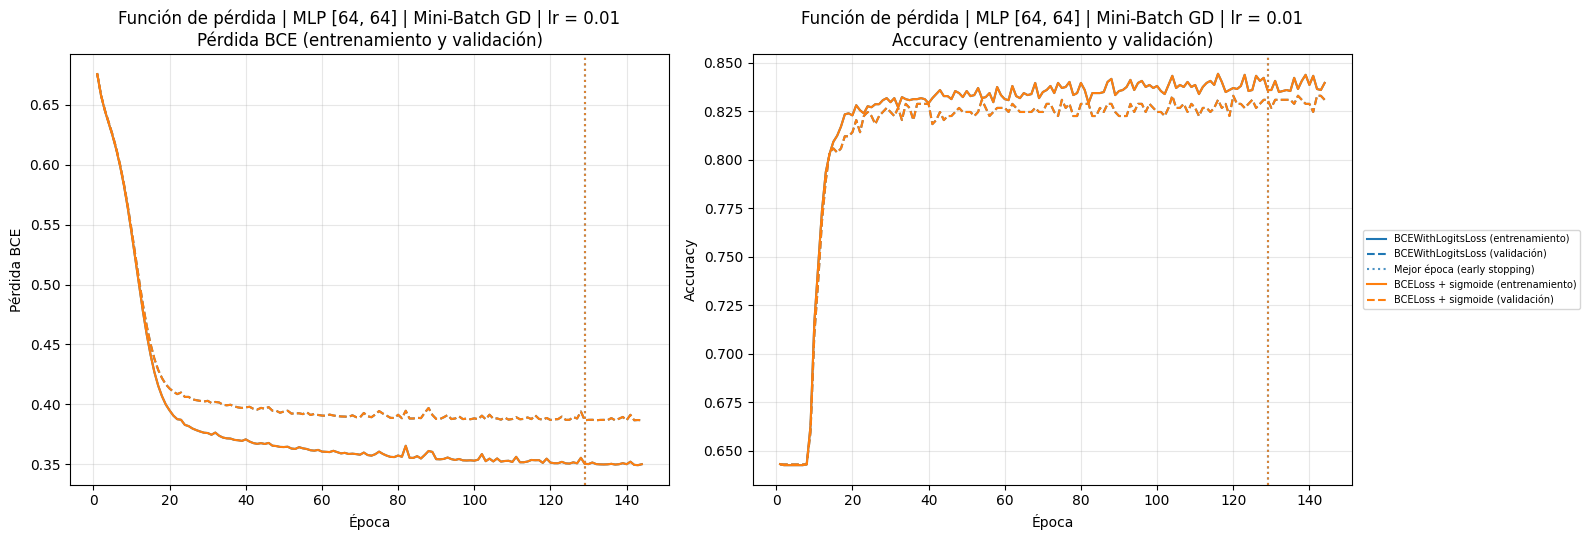

In [24]:
# ============================================================
# EXPERIMENTO: FUNCIÓN DE PÉRDIDA
# BCEWithLogitsLoss (salida logit) vs. BCELoss + sigmoide (salida probabilidad)
# [64, 64], Mini-Batch GD, lr = 0.01
# ============================================================
modelo_logits = crear_modelo([64, 64], clase=MLP)
modelo_sigmoide = crear_modelo([64, 64], clase=MLPSigmoide)

# Verificación: ambos modelos parten de los mismos pesos iniciales
mismos_pesos = all(torch.equal(a, b) for a, b in zip(modelo_logits.state_dict().values(),
                                                    modelo_sigmoide.state_dict().values()))
print(f"¿Mismos pesos iniciales en ambos modelos? {mismos_pesos}")

resultados_perdida = {
    "BCEWithLogitsLoss": entrenar_modelo(
        modelo_logits, crear_optimizador("Mini-Batch GD", modelo_logits.parameters(), 0.01),
        funcion_perdida="BCEWithLogitsLoss", nombre="BCEWithLogitsLoss"),
    "BCELoss + sigmoide": entrenar_modelo(
        modelo_sigmoide, crear_optimizador("Mini-Batch GD", modelo_sigmoide.parameters(), 0.01),
        funcion_perdida="BCELoss", nombre="BCELoss + sigmoide"),
}

display(tabla_resumen(resultados_perdida))
graficar_curvas(resultados_perdida, "Función de pérdida | MLP [64, 64] | Mini-Batch GD | lr = 0.01")

**Observación → Decisión**

- **Observación:** partiendo de los mismos pesos iniciales (verificado: `True`), `BCEWithLogitsLoss` y `BCELoss` + sigmoide producen resultados **idénticos** hasta el cuarto decimal: pérdida de validación 0.3867, accuracy 0.8309, F1 0.7538 y la misma mejor época (129).
- **Por qué importa:** las dos funciones son matemáticamente la misma pérdida. La diferencia que se veía en la versión anterior del notebook venía de que los modelos no partían de los mismos pesos.
- **Decisión:** se mantiene **`BCEWithLogitsLoss`**, que aplica la sigmoide dentro de la pérdida con el truco *log-sum-exp* y es numéricamente más estable cuando las salidas son muy grandes o muy pequeñas.

### Control del sobreajuste: regularización L1/L2 y dropout

**Observación → Decisión**

- **Observación:** los experimentos anteriores muestran sobreajuste cuando el entrenamiento se prolonga o el paso es agresivo. `[128, 128, 128]` sin early stopping llega a una brecha de pérdida de 0.1622 (pérdida de validación 0.4275 frente a 0.3922 en su mejor época). Adam termina con una pérdida de validación de 0.4537 frente a 0.3876 en su mejor época. Con lr = 0.1 la mejor época llega en la 12.
- **Por qué importa:** early stopping solo corta el entrenamiento a tiempo, pero no cambia lo que la red aprende. La regularización ataca la causa: limita el tamaño de los pesos (L1/L2) o fuerza representaciones redundantes (dropout).
- **Decisión:** se prueban L1, L2 y dropout sobre una red con capacidad suficiente para sobreajustar, `[128, 128, 128]`, con el mejor optimizador (SGD con momentum), lr = 0.01, early stopping y máximo 150 épocas. Antes se mide qué tan grande es cada penalización frente a la BCE inicial (≈ 0.69).

In [25]:
# ============================================================
# CONFIGURACIÓN DE PRUEBA DEL BLOQUE DE REGULARIZACIÓN
# Red con capacidad suficiente para sobreajustar: [128, 128, 128]
# ============================================================
ARQ_REG = [128, 128, 128]
OPT_REG = MEJOR_OPTIMIZADOR
# El barrido de learning rate se hizo con Mini-Batch GD; para otro optimizador se usa lr = 0.01
LR_REG = MEJOR_LR if MEJOR_OPTIMIZADOR == "Mini-Batch GD" else 0.01
print(f"Configuración de prueba: MLP {ARQ_REG} | {OPT_REG} | lr = {LR_REG} | early stopping, máx. 150 épocas")

res_sin_reg = correr("Sin regularización", ARQ_REG, optimizador=OPT_REG, lr=LR_REG)

# Magnitud de la penalización con los pesos iniciales, frente a la BCE inicial (≈ ln 2 = 0.693)
_pesos0 = [v for k, v in pesos_iniciales(ARQ_REG).items() if k.endswith("weight")]
norma_l1 = sum(w.abs().sum().item() for w in _pesos0)
norma_l2 = sum((w ** 2).sum().item() for w in _pesos0)
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2]
display(pd.DataFrame({
    "λ": LAMBDAS,
    "Penalización L1 inicial (λ·Σ|w|)": [l * norma_l1 for l in LAMBDAS],
    "Penalización L2 inicial (λ·Σw²)": [l * norma_l2 for l in LAMBDAS],
}).set_index("λ").round(5))
print(f"Σ|w| inicial = {norma_l1:.1f} | Σw² inicial = {norma_l2:.2f}")

Configuración de prueba: MLP [128, 128, 128] | SGD con momentum | lr = 0.01 | early stopping, máx. 150 épocas


,Penalización L1 inicial (λ·Σ|w|),Penalización L2 inicial (λ·Σw²)
λ,,
0.00001,0.01839,0.00128
0.00010,0.18390,0.01280
0.00100,1.83901,0.12799
0.01000,18.39014,1.27991


Σ|w| inicial = 1839.0 | Σw² inicial = 127.99


,Pérdida val,Accuracy val,F1 val (clase 1),Recall val (clase 1),Brecha pérdida (val - train),Brecha accuracy (train - val),Mejor época,Época de parada
Modelo,,,,,,,,
Sin regularización,0.3840,0.8288,0.7500,0.7193,0.0345,0.0108,14,29
L1 λ = 1e-05,0.3838,0.8288,0.7500,0.7193,0.0342,0.0097,14,29
L1 λ = 0.0001,0.3838,0.8267,0.7477,0.7193,0.0329,0.0113,14,29
L1 λ = 0.001,0.3831,0.8246,0.7407,0.7018,0.0265,0.0118,26,41
L1 λ = 0.01,0.6517,0.6430,0.0000,0.0000,-0.0002,-0.0004,3,18


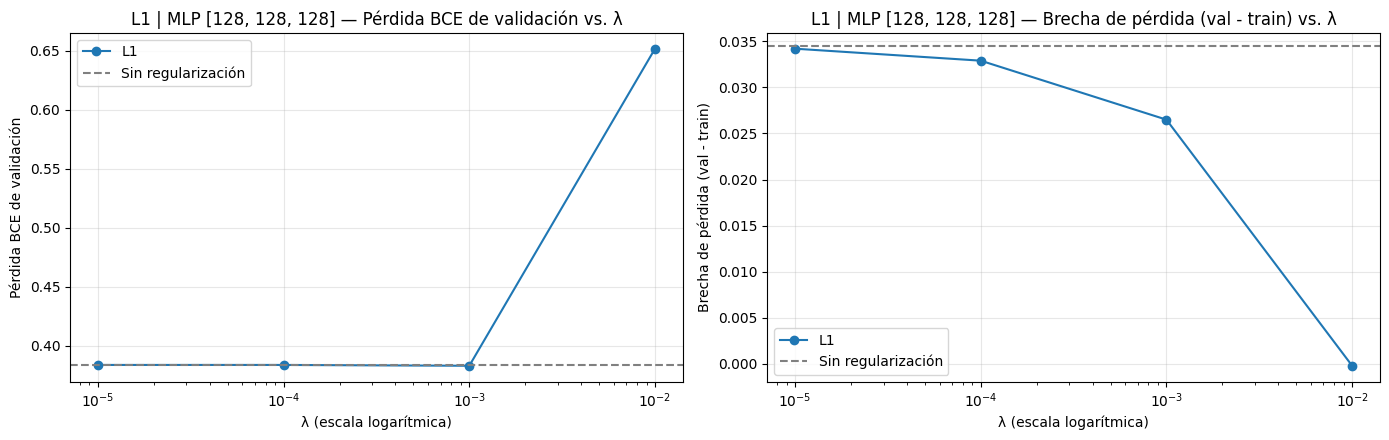

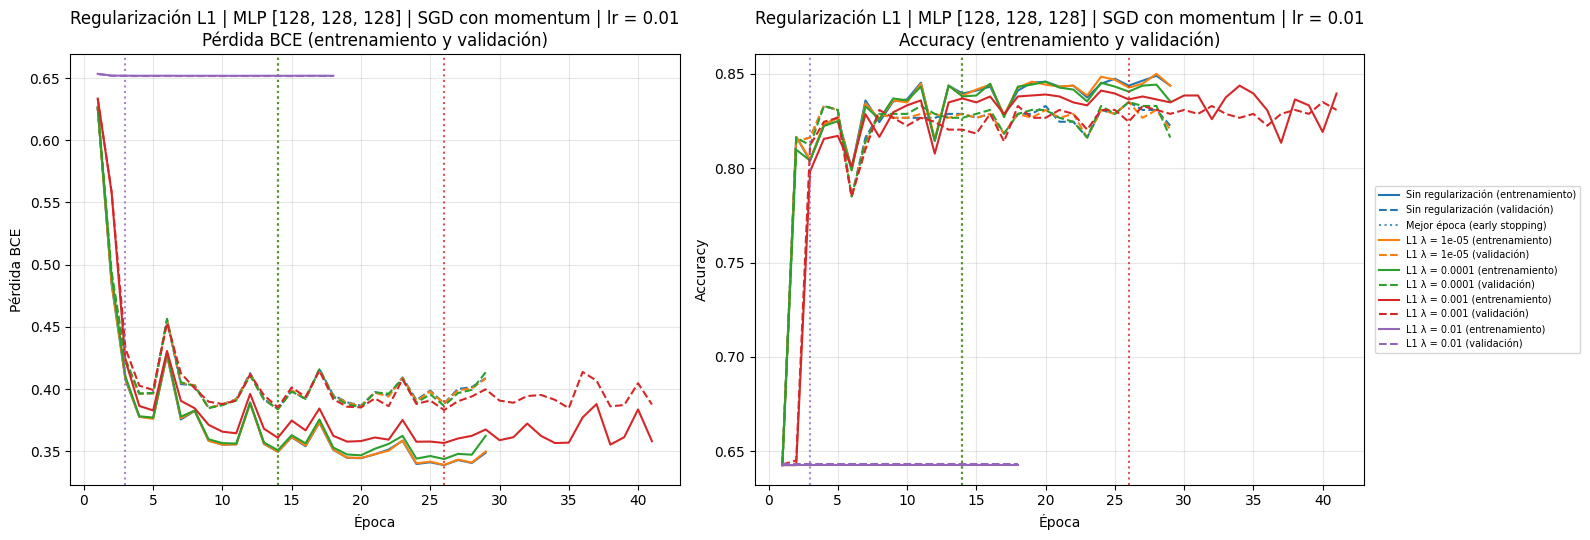

Mejor λ de L1: 0.001


In [26]:
# ============================================================
# BARRIDOS DE λ PARA L1 Y L2
# ============================================================
def barrido_lambda(tipo):
    resultados = {"Sin regularización": res_sin_reg}
    for lam in LAMBDAS:
        nombre = f"{tipo} λ = {lam:g}"
        resultados[nombre] = correr(nombre, ARQ_REG, optimizador=OPT_REG, lr=LR_REG,
                                    tipo_reg=tipo, lambda_reg=lam)
    return resultados


def graficar_barrido_lambda(resultados, tipo):
    tabla = tabla_resumen(resultados)
    fila_ref = tabla.loc["Sin regularización"]
    tabla_l = tabla.drop(index="Sin regularización")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, (col, etiqueta) in zip(axes, (("Pérdida val", "Pérdida BCE de validación"),
                                          ("Brecha pérdida (val - train)", "Brecha de pérdida (val - train)"))):
        ax.plot(LAMBDAS, tabla_l[col], marker="o", label=tipo)
        ax.axhline(fila_ref[col], color="gray", linestyle="--", label="Sin regularización")
        ax.set_xscale("log")
        ax.set_xlabel("λ (escala logarítmica)")
        ax.set_ylabel(etiqueta)
        ax.set_title(f"{tipo} | MLP {ARQ_REG} — {etiqueta} vs. λ")
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.tight_layout()
    plt.show()


resultados_l1 = barrido_lambda("L1")
tabla_l1 = tabla_resumen(resultados_l1)
display(tabla_l1[["Pérdida val", "Accuracy val", "F1 val (clase 1)", "Recall val (clase 1)",
                  "Brecha pérdida (val - train)", "Brecha accuracy (train - val)", "Mejor época", "Época de parada"]])
graficar_barrido_lambda(resultados_l1, "L1")
graficar_curvas(resultados_l1, f"Regularización L1 | MLP {ARQ_REG} | {OPT_REG} | lr = {LR_REG}")

MEJOR_L1 = mejor_por_val_loss({k: v for k, v in resultados_l1.items() if k != "Sin regularización"})
LAMBDA_L1 = float(MEJOR_L1.split("= ")[1])
print(f"Mejor λ de L1: {LAMBDA_L1:g}")

**Observación → Decisión**

- **Observación:** con λ = 1e-5 y λ = 1e-4 el resultado es prácticamente igual al de la red sin regularizar (pérdida de validación 0.3838 en ambos casos frente a 0.3840, misma mejor época 14). **Por qué λ = 1e-4 casi no tenía efecto:** con los pesos iniciales la penalización vale 0.18 (Σ|w| = 1839) y su gradiente por peso es solo 1e-4, muy pequeño frente al gradiente de la BCE. En las 14 épocas que dura el entrenamiento útil no alcanza a reducir los pesos. Con **λ = 1e-3** la penalización (1.84) ya compite con la BCE: la brecha de pérdida baja de 0.0345 a 0.0265, la mejor época se retrasa a la 26 y la pérdida de validación mejora ligeramente (0.3831), aunque el F1 baja de 0.7500 a 0.7407. Con λ = 1e-2 (penalización de 18.4) todos los pesos se van a cero y el modelo colapsa a predecir la clase 0 (F1 = 0).
- **Decisión:** se elige **λ = 1e-3 para L1** (menor pérdida de validación). Su efecto principal es reducir la brecha, no mejorar el desempeño.

,Pérdida val,Accuracy val,F1 val (clase 1),Recall val (clase 1),Brecha pérdida (val - train),Brecha accuracy (train - val),Mejor época,Época de parada
Modelo,,,,,,,,
Sin regularización,0.3840,0.8288,0.7500,0.7193,0.0345,0.0108,14,29
L2 λ = 1e-05,0.3832,0.8288,0.7500,0.7193,0.0335,0.0097,14,29
L2 λ = 0.0001,0.3833,0.8288,0.7500,0.7193,0.0334,0.0097,14,29
L2 λ = 0.001,0.3826,0.8267,0.7477,0.7193,0.0308,0.0118,14,29
L2 λ = 0.01,0.3836,0.8246,0.7423,0.7076,0.0185,0.0103,20,35


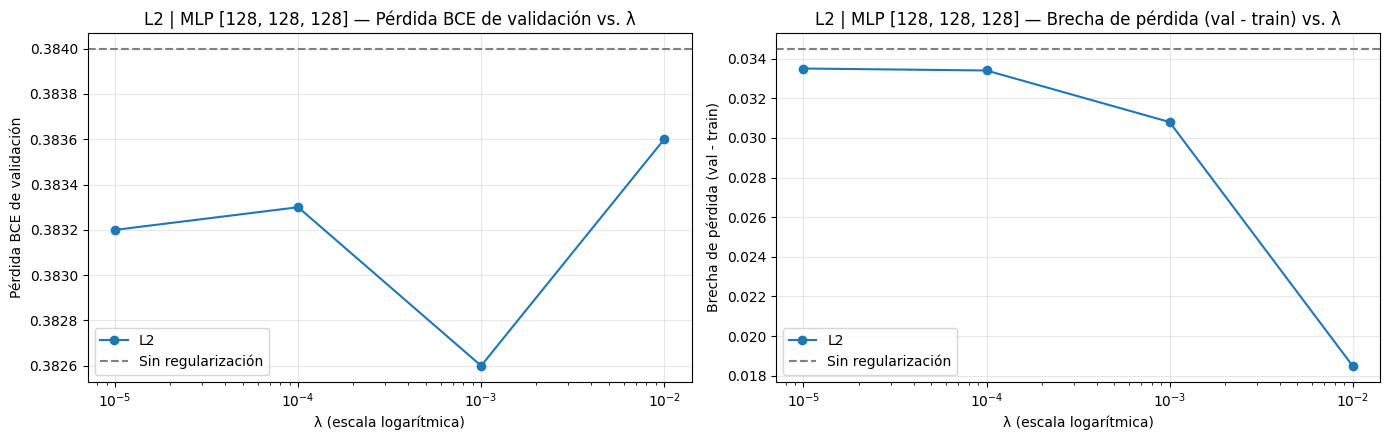

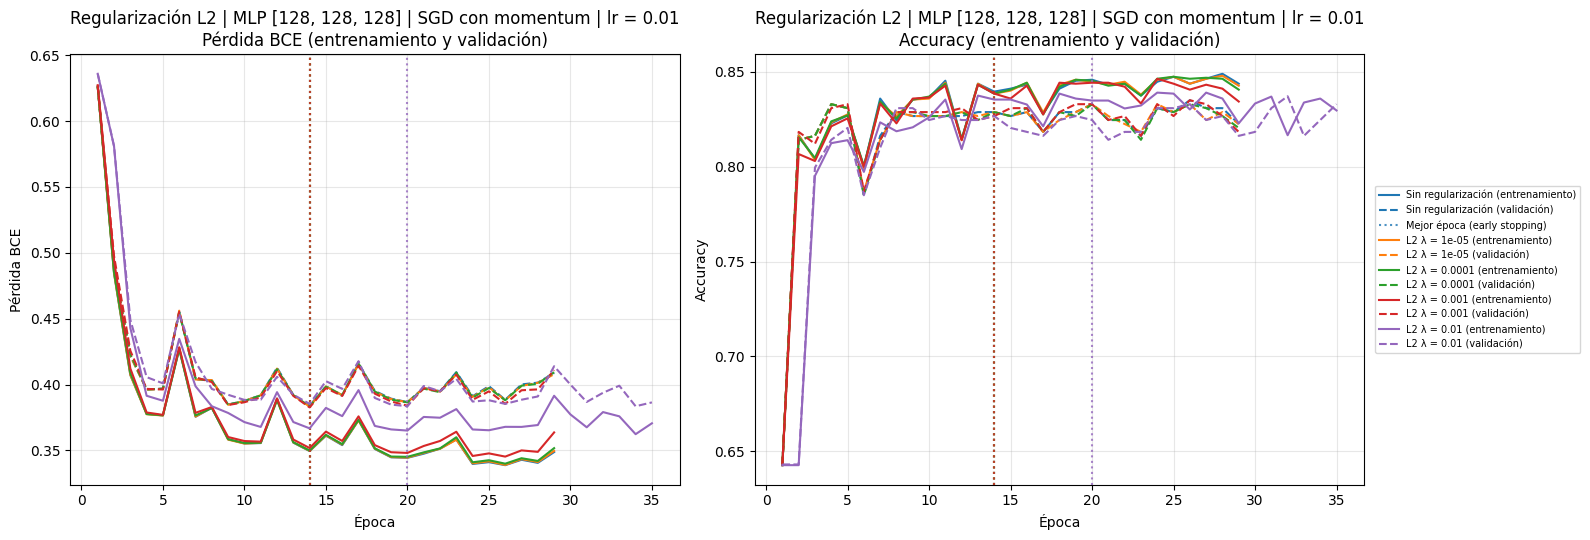

Mejor λ de L2: 0.001


In [27]:
resultados_l2 = barrido_lambda("L2")
tabla_l2 = tabla_resumen(resultados_l2)
display(tabla_l2[["Pérdida val", "Accuracy val", "F1 val (clase 1)", "Recall val (clase 1)",
                  "Brecha pérdida (val - train)", "Brecha accuracy (train - val)", "Mejor época", "Época de parada"]])
graficar_barrido_lambda(resultados_l2, "L2")
graficar_curvas(resultados_l2, f"Regularización L2 | MLP {ARQ_REG} | {OPT_REG} | lr = {LR_REG}")

MEJOR_L2 = mejor_por_val_loss({k: v for k, v in resultados_l2.items() if k != "Sin regularización"})
LAMBDA_L2 = float(MEJOR_L2.split("= ")[1])
print(f"Mejor λ de L2: {LAMBDA_L2:g}")

**Observación → Decisión**

- **Observación:** L2 es mucho más suave que L1 con el mismo λ (penalización inicial de 0.0128 con λ = 1e-4, porque Σw² = 128 mientras Σ|w| = 1839). Con λ = 1e-5 y 1e-4 el efecto es mínimo (pérdida de validación 0.3832 y 0.3833 frente a 0.3840). **λ = 1e-3** da la menor pérdida de validación (0.3826) y baja la brecha a 0.0308. λ = 1e-2 es la que más reduce la brecha (0.0185), pero baja el F1 a 0.7423 y el recall a 0.7076.
- **Decisión:** se elige **λ = 1e-3 para L2**. La mejora sobre no regularizar es pequeña (−0.0014 en pérdida de validación), lo que indica que, con early stopping, el sobreajuste que queda es limitado.

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
Dropout p = 0.0,0.3495,0.3840,0.8396,0.8288,0.7665,0.7500,0.7193,0.8973,0.4088,Sí,14,29,0.0345,0.0108,37889
Dropout p = 0.1,0.3587,0.3861,0.8370,0.8309,0.7622,0.7568,0.7368,0.8955,0.3970,Sí,9,24,0.0274,0.0061,37889
Dropout p = 0.2,0.3604,0.3861,0.8365,0.8288,0.7616,0.7545,0.7368,0.8953,0.3982,Sí,9,24,0.0257,0.0077,37889
Dropout p = 0.3,0.3606,0.3909,0.8328,0.8288,0.7583,0.7574,0.7485,0.8935,0.4045,Sí,9,24,0.0303,0.0040,37889
Dropout p = 0.5,0.3487,0.3956,0.8386,0.8309,0.7661,0.7568,0.7368,0.8935,0.4017,Sí,20,35,0.0469,0.0077,37889


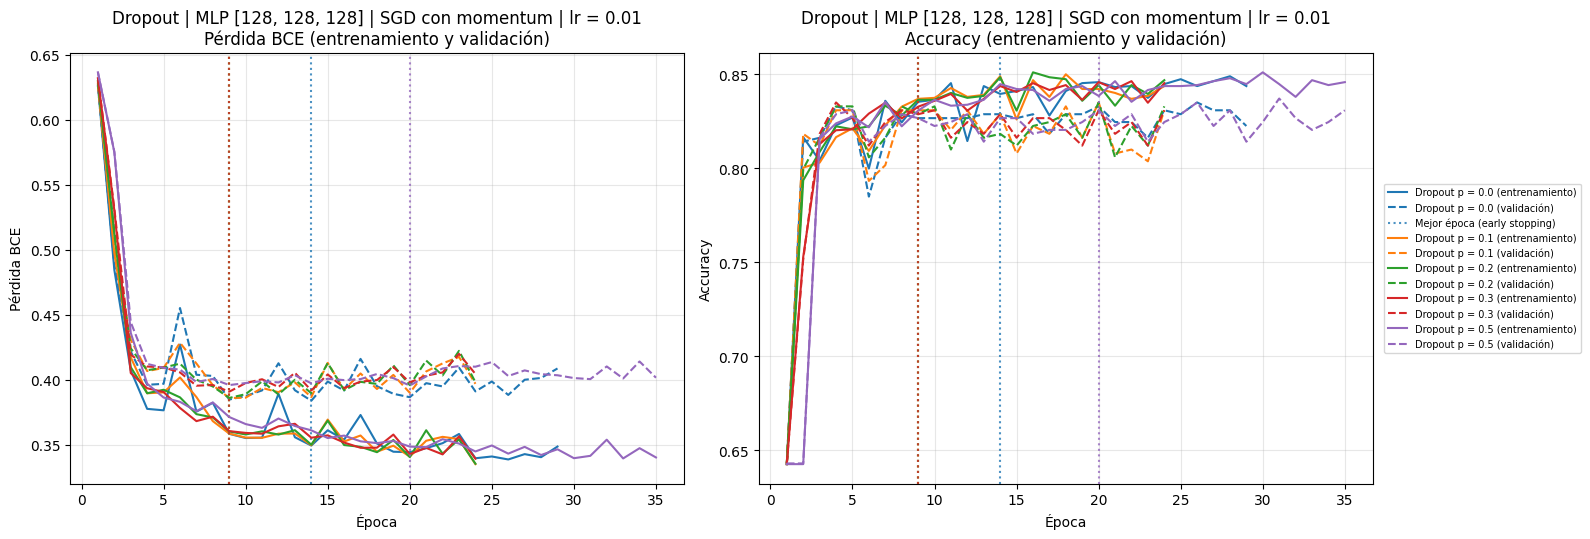

Mejor p de dropout: 0.0 | p usado en el grid final: 0.1


In [28]:
# ============================================================
# DROPOUT
# ============================================================
DROPOUTS = [0.0, 0.1, 0.2, 0.3, 0.5]
resultados_dropout = {f"Dropout p = {p}": correr(f"Dropout p = {p}", ARQ_REG, optimizador=OPT_REG,
                                                  lr=LR_REG, dropout=p)
                      for p in DROPOUTS}
display(tabla_resumen(resultados_dropout))
graficar_curvas(resultados_dropout, f"Dropout | MLP {ARQ_REG} | {OPT_REG} | lr = {LR_REG}")

MEJOR_P = float(mejor_por_val_loss(resultados_dropout).split("= ")[1])
# En el grid se compara 0 contra un p > 0; si p = 0 gana, se usa el mejor p > 0
P_GRID = MEJOR_P if MEJOR_P > 0 else float(mejor_por_val_loss(
    {k: v for k, v in resultados_dropout.items() if k != "Dropout p = 0.0"}).split("= ")[1])
print(f"Mejor p de dropout: {MEJOR_P} | p usado en el grid final: {P_GRID}")

**Observación → Decisión**

- **Observación:** sin dropout (p = 0) se obtiene la menor pérdida de validación (0.3840). Con p = 0.1 y p = 0.2 la pérdida sube un poco (0.3861), pero la brecha baja de 0.0345 a 0.0274 y 0.0257, y el F1 sube de 0.7500 a 0.7568 y 0.7545, con un recall de 0.7368 frente a 0.7193. Con p = 0.5 la pérdida empeora a 0.3956. La pérdida de validación en la última época también mejora con dropout (0.3970 con p = 0.1 frente a 0.4088 sin dropout), es decir, las curvas se degradan menos después del mínimo.
- **Decisión:** según el criterio de pérdida de validación, **el mejor p es 0**. Como dropout reduce la brecha y mejora el F1, en el pipeline final se compara **p = 0 contra p = 0.1**, el mejor valor mayor que cero.

,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),AUC val,Pérdida val última época,Early stopping,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Parámetros
Modelo,,,,,,,,,,,,,,,
Sin regularización,0.3495,0.3840,0.8396,0.8288,0.7665,0.7500,0.7193,0.8973,0.4088,Sí,14,29,0.0345,0.0108,37889
Mejor L1 (λ = 0.001),0.3566,0.3831,0.8365,0.8246,0.7557,0.7407,0.7018,0.8965,0.3876,Sí,26,41,0.0265,0.0118,37889
Mejor L2 (λ = 0.001),0.3518,0.3826,0.8386,0.8267,0.7650,0.7477,0.7193,0.8974,0.4109,Sí,14,29,0.0308,0.0118,37889
Mejor dropout (p = 0.0),0.3495,0.3840,0.8396,0.8288,0.7665,0.7500,0.7193,0.8973,0.4088,Sí,14,29,0.0345,0.0108,37889


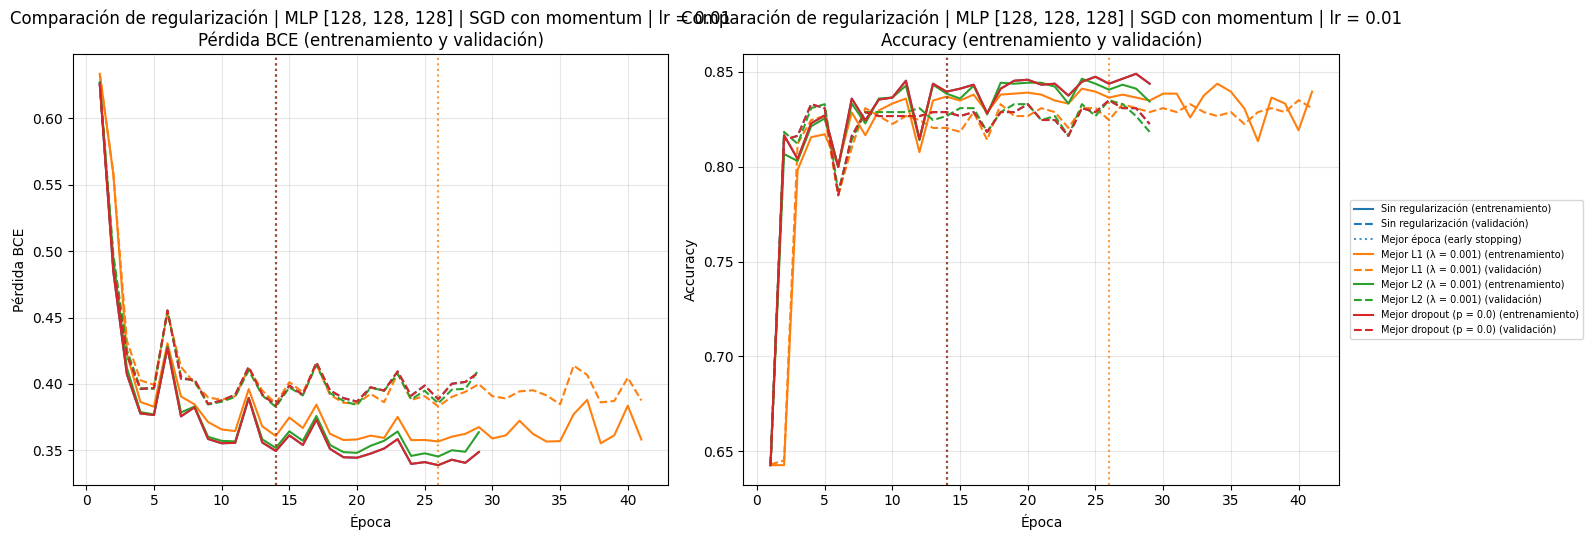

Mejor opción del bloque: Mejor L2 (λ = 0.001)
Mejor configuración hasta el momento: {'hidden_layers': [128, 128, 128], 'optimizador': 'SGD con momentum', 'lr': 0.01, 'dropout': 0.0, 'tipo_reg': 'L2', 'lambda_reg': 0.001}


In [29]:
# ============================================================
# COMPARACIÓN FINAL DEL BLOQUE DE REGULARIZACIÓN
# ============================================================
resultados_bloque = {
    "Sin regularización": res_sin_reg,
    f"Mejor L1 (λ = {LAMBDA_L1:g})": resultados_l1[MEJOR_L1],
    f"Mejor L2 (λ = {LAMBDA_L2:g})": resultados_l2[MEJOR_L2],
    f"Mejor dropout (p = {MEJOR_P})": resultados_dropout[f"Dropout p = {MEJOR_P}"],
}
display(tabla_resumen(resultados_bloque))
graficar_curvas(resultados_bloque, f"Comparación de regularización | MLP {ARQ_REG} | {OPT_REG} | lr = {LR_REG}")

GANADOR_BLOQUE = mejor_por_val_loss(resultados_bloque)
CONFIG_ACTUAL = {"hidden_layers": ARQ_REG, "optimizador": OPT_REG, "lr": LR_REG,
                 "dropout": 0.0, "tipo_reg": "Ninguna", "lambda_reg": 0.0}
if GANADOR_BLOQUE.startswith("Mejor L1"):
    CONFIG_ACTUAL.update(tipo_reg="L1", lambda_reg=LAMBDA_L1)
elif GANADOR_BLOQUE.startswith("Mejor L2"):
    CONFIG_ACTUAL.update(tipo_reg="L2", lambda_reg=LAMBDA_L2)
elif GANADOR_BLOQUE.startswith("Mejor dropout"):
    CONFIG_ACTUAL.update(dropout=MEJOR_P)
print(f"Mejor opción del bloque: {GANADOR_BLOQUE}")
print(f"Mejor configuración hasta el momento: {CONFIG_ACTUAL}")

**Observación → Decisión**

- **Observación:** comparadas sobre la misma red, las cuatro opciones quedan dentro de 0.0014 de pérdida de validación: sin regularización 0.3840, L1 (λ = 1e-3) 0.3831, **L2 (λ = 1e-3) 0.3826** y dropout (p = 0) 0.3840, que coincide con no regularizar. L1 es la que más reduce la brecha (0.0265 frente a 0.0345), pero a costa del F1 (0.7407).
- **Por qué importa:** con early stopping activo, la regularización aporta poco desempeño adicional. Su valor está en estabilizar el entrenamiento y reducir la brecha, sobre todo en redes grandes.
- **Decisión:** la mejor configuración hasta el momento es `[128, 128, 128]` + SGD con momentum + lr = 0.01 + **L2 (λ = 1e-3)**. Con ella se estudia el desbalance de clases. En el pipeline final se prueban Ninguna, L1 (λ = 1e-3) y L2 (λ = 1e-3).

### Desbalance de clases (64 % / 36 %)

**Observación → Decisión**

- **Observación:** en todos los experimentos el **recall de la clase 1 es la métrica más baja**. En la mejor configuración hasta el momento queda en 0.7193, con una accuracy de 0.8267 y una precision de 0.7785. La clase 1 es el 35.7 % de los datos (64 % / 36 %).
- **Por qué importa:** para una detección temprana, un **falso negativo** (un estudiante en riesgo que el modelo no detecta) es el error más costoso, porque ese estudiante no recibe el apoyo que necesitaría. Un falso positivo solo genera una revisión adicional.
- **Decisión:** se comparan tres opciones en validación: (a) sin ajuste, (b) `pos_weight = n_neg / n_pos` en la pérdida (calculado solo con `y_train_exp`) y (c) mantener el entrenamiento pero **optimizar el umbral de decisión en validación**, buscando entre 0.20 y 0.60 el que maximiza el F1 de la clase 1.

In [30]:
# ============================================================
# EXPERIMENTO: DESBALANCE DE CLASES (todo en VALIDACIÓN)
# ============================================================
n_pos = int(y_train_exp.sum().item())
n_neg = int(len(y_train_exp) - n_pos)
POS_WEIGHT = n_neg / n_pos
print(f"Entrenamiento: {n_neg} negativos, {n_pos} positivos -> pos_weight = {POS_WEIGHT:.4f}")

# (a) sin ajuste
res_a = correr("(a) Sin ajuste", **CONFIG_ACTUAL)
# (b) pos_weight en BCEWithLogitsLoss
res_b = correr("(b) pos_weight", **CONFIG_ACTUAL, pos_weight=POS_WEIGHT)

# (c) modelo (a) con el umbral optimizado en validación (F1 de la clase 1)
umbrales = np.round(np.arange(0.20, 0.6001, 0.01), 2)
f1_por_umbral = [evaluar(res_a["modelo"], X_val, y_val, u)["f1"] for u in umbrales]
UMBRAL_OPT = float(umbrales[int(np.argmax(f1_por_umbral))])
print(f"Umbral que maximiza el F1 de la clase 1 en validación: {UMBRAL_OPT}")

metricas_desbalance = {
    "(a) Sin ajuste (umbral 0.5)": evaluar(res_a["modelo"], X_val, y_val, 0.5),
    "(b) pos_weight (umbral 0.5)": evaluar(res_b["modelo"], X_val, y_val, 0.5),
    f"(c) Umbral optimizado ({UMBRAL_OPT})": evaluar(res_a["modelo"], X_val, y_val, UMBRAL_OPT),
}
tabla_desbalance = pd.DataFrame({
    nombre: {"Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
             "Precision (clase 1)": m["precision"], "Recall (clase 1)": m["recall"],
             "F1 (clase 1)": m["f1"], "AUC": m["auc"], "Pérdida BCE": m["loss"]}
    for nombre, m in metricas_desbalance.items()
}).T.round(4)
tabla_desbalance.index.name = "Opción (validación)"
display(tabla_desbalance)

Entrenamiento: 1230 negativos, 684 positivos -> pos_weight = 1.7982


Umbral que maximiza el F1 de la clase 1 en validación: 0.37


,Accuracy,Balanced accuracy,Precision (clase 1),Recall (clase 1),F1 (clase 1),AUC,Pérdida BCE
Opción (validación),,,,,,,
(a) Sin ajuste (umbral 0.5),0.8267,0.8028,0.7785,0.7193,0.7477,0.8974,0.3826
(b) pos_weight (umbral 0.5),0.8205,0.8214,0.7157,0.8246,0.7663,0.8961,0.4019
(c) Umbral optimizado (0.37),0.8288,0.8279,0.7306,0.8246,0.7747,0.8974,0.3826


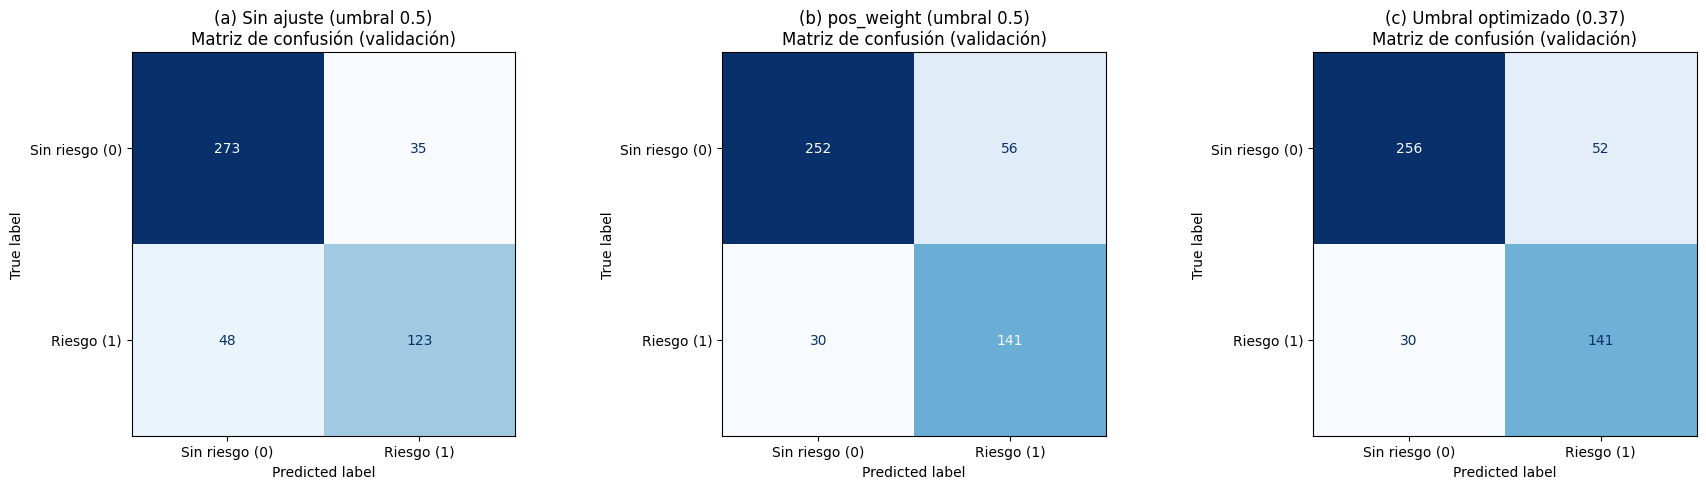

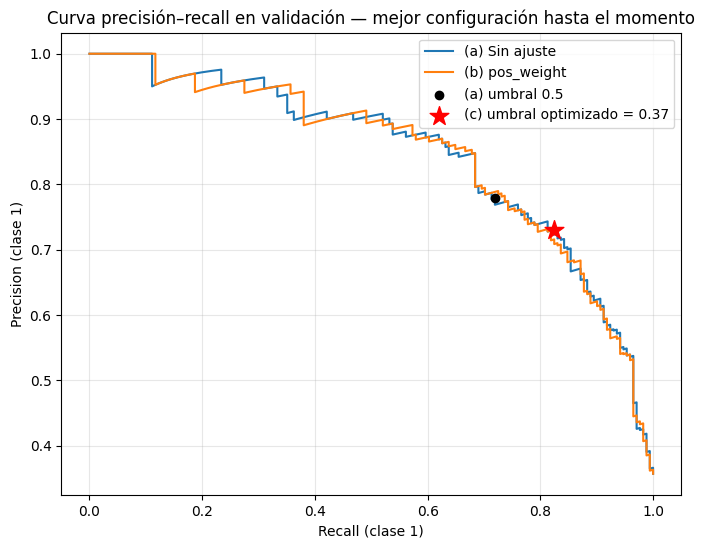

Opciones que cumplen el criterio: ['pos_weight', 'umbral']
Ajuste adoptado para el pipeline final: umbral


In [31]:
# Matrices de confusión de validación
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, metricas_desbalance.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val.view(-1).numpy().astype(int), m["pred"],
        display_labels=["Sin riesgo (0)", "Riesgo (1)"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{nombre}\nMatriz de confusión (validación)")
fig.tight_layout()
plt.show()

# Curva precisión–recall de validación con el umbral elegido
y_val_np = y_val.view(-1).numpy().astype(int)
fig, ax = plt.subplots(figsize=(8, 6))
for nombre, res in (("(a) Sin ajuste", res_a), ("(b) pos_weight", res_b)):
    proba = evaluar(res["modelo"], X_val, y_val)["proba"]
    prec, rec, _ = precision_recall_curve(y_val_np, proba)
    ax.plot(rec, prec, label=nombre)
m05, mopt = metricas_desbalance["(a) Sin ajuste (umbral 0.5)"], metricas_desbalance[f"(c) Umbral optimizado ({UMBRAL_OPT})"]
ax.scatter(m05["recall"], m05["precision"], color="black", zorder=5, label="(a) umbral 0.5")
ax.scatter(mopt["recall"], mopt["precision"], color="red", marker="*", s=200, zorder=5,
           label=f"(c) umbral optimizado = {UMBRAL_OPT}")
ax.set_xlabel("Recall (clase 1)")
ax.set_ylabel("Precision (clase 1)")
ax.set_title("Curva precisión–recall en validación — mejor configuración hasta el momento")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

# Decisión automática: se adopta un ajuste si mejora recall y F1 de la clase 1
# sin bajar la accuracy más de 2 puntos porcentuales
base = metricas_desbalance["(a) Sin ajuste (umbral 0.5)"]
candidatas = {
    "pos_weight": metricas_desbalance["(b) pos_weight (umbral 0.5)"],
    "umbral": metricas_desbalance[f"(c) Umbral optimizado ({UMBRAL_OPT})"],
}
aceptadas = {k: m for k, m in candidatas.items()
             if m["recall"] > base["recall"] and m["f1"] > base["f1"] and m["accuracy"] >= base["accuracy"] - 0.02}
AJUSTE_DESBALANCE = max(aceptadas, key=lambda k: aceptadas[k]["f1"]) if aceptadas else "ninguno"
USAR_POS_WEIGHT = AJUSTE_DESBALANCE == "pos_weight"
USAR_UMBRAL = AJUSTE_DESBALANCE == "umbral"
print(f"Opciones que cumplen el criterio: {list(aceptadas) or 'ninguna'}")
print(f"Ajuste adoptado para el pipeline final: {AJUSTE_DESBALANCE}")

**Observación → Decisión**

- **Observación:** con `pos_weight` = 1.798 el recall sube de 0.7193 a **0.8246** y el F1 de 0.7477 a 0.7663, pero la accuracy baja de 0.8267 a 0.8205 y la pérdida de validación sube a 0.4019, porque las probabilidades se desplazan hacia la clase 1. Con el **umbral optimizado (0.37)** se obtiene el mismo recall (0.8246) con mejor F1 (**0.7747**), una accuracy un poco mayor (0.8288), balanced accuracy de 0.8279 y la misma pérdida y AUC del modelo original, porque las probabilidades no cambian.
- **Por qué importa:** las dos opciones mejoran recall y F1 sin una caída importante de la accuracy (criterio: menos de 2 puntos). El umbral lo consigue sin alterar el entrenamiento ni la calibración de las probabilidades.
- **Decisión:** se adopta el **ajuste de umbral**. El pipeline final se entrena sin `pos_weight` y se ordena con el umbral estándar de 0.5. Después, para el modelo elegido, el umbral se vuelve a ajustar **en validación** con la misma búsqueda. **El conjunto de prueba nunca se usa para elegir el umbral.**

## Pipeline de pruebas final

En esta sección se prueban **todas las combinaciones** de los factores explorados individualmente en las secciones anteriores. La tabla coincide exactamente con el código de la celda siguiente:

| Factor | Valores | Origen |
|---|---|---|
| Arquitectura (capas ocultas) | `[32]`, `[64, 64]`, `[128, 128]`, `[128, 128, 128]` | Distintas capacidades (experimento de arquitecturas) |
| Optimizador | AdaGrad, Mini-Batch GD, GD (batch completo) | Experimento de optimizadores |
| Learning rate | 0.005, 0.01, 0.05 | Rango útil del experimento de learning rate |
| Regularización | Ninguna, L1 (λ = 1e-3), L2 (λ = 1e-3) | Mejores λ de los barridos |
| Dropout | 0, 0.1 | Experimento de dropout |
| Función de pérdida | `BCEWithLogitsLoss` (sin `pos_weight`; el desbalance se trata con el umbral) | Experimentos de pérdida y desbalance |
| Early stopping | Sí: paciencia 15, máximo 150 épocas, batch 32 (salvo GD) | Experimento de early stopping |

Total: 4 × 3 × 3 × 3 × 2 = **216 entrenamientos**. Para que la comparación sea justa:

- todas las corridas usan el mismo split de entrenamiento y validación y la estrategia de escalado `minmax_completo`;
- todas las corridas de una misma arquitectura parten de los **mismos pesos iniciales** y del mismo orden de mini-batches;
- la penalización L1/L2 se suma a la pérdida solo para calcular los gradientes; las pérdidas que se reportan son la BCE pura;
- la mejor configuración se escoge solo con **validación**.

In [32]:
# ============================================================
# PIPELINE FINAL: ESPACIO DE BÚSQUEDA
# ============================================================
final_architectures = {
    "[32]": [32],
    "[64, 64]": [64, 64],
    "[128, 128]": [128, 128],
    "[128, 128, 128]": [128, 128, 128],
}
final_optimizers = ["AdaGrad", "Mini-Batch GD", "GD"]
final_learning_rates = [0.005, 0.01, 0.05]
final_regularizations = {"Ninguna": 0.0, "L1": LAMBDA_L1, "L2": LAMBDA_L2}
final_dropouts = [0.0, P_GRID]
FINAL_POS_WEIGHT = POS_WEIGHT if USAR_POS_WEIGHT else None

combinaciones = list(itertools.product(final_architectures, final_optimizers, final_learning_rates,
                                       final_regularizations, final_dropouts))

tabla_factores = pd.DataFrame({
    "Factor": ["Arquitectura", "Optimizador", "Learning rate", "Regularización", "Dropout",
               "Función de pérdida", "Early stopping"],
    "Valores": [", ".join(final_architectures), ", ".join(final_optimizers),
                ", ".join(map(str, final_learning_rates)),
                f"Ninguna, L1 (λ = {LAMBDA_L1:g}), L2 (λ = {LAMBDA_L2:g})",
                ", ".join(map(str, final_dropouts)),
                "BCEWithLogitsLoss" + (f" con pos_weight = {POS_WEIGHT:.3f}" if USAR_POS_WEIGHT else ""),
                "Sí (paciencia 15, máx. 150 épocas), batch 32 salvo GD"],
}).set_index("Factor")
display(tabla_factores)
print(f"Total de combinaciones: {len(final_architectures)} × {len(final_optimizers)} × "
      f"{len(final_learning_rates)} × {len(final_regularizations)} × {len(final_dropouts)} = {len(combinaciones)}")

,Valores
Factor,
Arquitectura,"[32], [64, 64], [128, 128], [128, 128, 128]"
Optimizador,"AdaGrad, Mini-Batch GD, GD"
Learning rate,"0.005, 0.01, 0.05"
Regularización,"Ninguna, L1 (λ = 0.001), L2 (λ = 0.001)"
Dropout,"0.0, 0.1"
Función de pérdida,BCEWithLogitsLoss
Early stopping,"Sí (paciencia 15, máx. 150 épocas), batch 32 salvo GD"


Total de combinaciones: 4 × 3 × 3 × 3 × 2 = 216


In [33]:
# ============================================================
# PIPELINE FINAL: ENTRENAMIENTO DE TODAS LAS COMBINACIONES
# ============================================================
def oscilacion(serie):
    """Cambio absoluto medio de una curva entre épocas consecutivas (inestabilidad)."""
    return float(np.mean(np.abs(np.diff(serie)))) if len(serie) > 1 else 0.0


def fila_grid(clave, r):
    arq, opt, lr, reg, p = clave
    mt, mv = r["metricas_train"], r["metricas_val"]
    h = r["historial"]
    return {
        "Arquitectura": arq, "Optimizador": opt, "Learning rate": lr,
        "Regularización": reg, "Dropout": p,
        "Pérdida train": mt["loss"], "Pérdida val": mv["loss"],
        "Accuracy train": mt["accuracy"], "Accuracy val": mv["accuracy"],
        "F1 train (clase 1)": mt["f1"], "F1 val (clase 1)": mv["f1"],
        "Recall val (clase 1)": mv["recall"], "Precision val (clase 1)": mv["precision"],
        "AUC val": mv["auc"],
        "Mejor época": r["mejor_epoca"], "Época de parada": r["epoca_parada"],
        "Brecha pérdida (val - train)": mv["loss"] - mt["loss"],
        "Brecha accuracy (train - val)": mt["accuracy"] - mv["accuracy"],
        "Oscilación pérdida val": oscilacion(h["val_loss"][: r["mejor_epoca"]]),
        "Parámetros": r["parametros"], "Tiempo (s)": r["tiempo_s"],
    }


final_results = {}
final_rows = []
inicio_total = time.time()

for n, clave in enumerate(combinaciones, start=1):
    arq, opt, lr, reg, p = clave
    nombre = f"{arq} | {opt} | lr={lr} | {reg} | dropout={p}"
    r = correr(nombre, final_architectures[arq], optimizador=opt, lr=lr, dropout=p,
               tipo_reg=reg, lambda_reg=final_regularizations[reg], pos_weight=FINAL_POS_WEIGHT)
    final_results[clave] = r
    final_rows.append(fila_grid(clave, r))
    if n == 1:
        print(f"Tiempo de la primera corrida: {r['tiempo_s']:.1f} s")
    if n % 12 == 0 or n == len(combinaciones):
        transcurrido = time.time() - inicio_total
        print(f"[{n:03d}/{len(combinaciones)}] transcurrido {transcurrido / 60:.1f} min | "
              f"estimado restante {transcurrido / n * (len(combinaciones) - n) / 60:.1f} min")

final_df = pd.DataFrame(final_rows)
print(f"\nTiempo total del grid: {(time.time() - inicio_total) / 60:.1f} min")

Tiempo de la primera corrida: 9.9 s


[012/216] transcurrido 2.5 min | estimado restante 43.2 min


[024/216] transcurrido 4.3 min | estimado restante 34.0 min


[036/216] transcurrido 5.7 min | estimado restante 28.4 min


[048/216] transcurrido 6.3 min | estimado restante 22.2 min


[060/216] transcurrido 8.0 min | estimado restante 20.9 min


... (9 outputs left out)

[180/216] transcurrido 26.2 min | estimado restante 5.2 min


[192/216] transcurrido 28.7 min | estimado restante 3.6 min


[204/216] transcurrido 29.5 min | estimado restante 1.7 min


[216/216] transcurrido 30.3 min | estimado restante 0.0 min

Tiempo total del grid: 30.3 min


#### Criterio de ranking del pipeline final

Las configuraciones se ordenan por el **F1 de la clase 1 en validación** (modelo de la mejor época) y, en caso de empate, por la **menor pérdida de validación**. El objetivo del proyecto es la detección temprana de estudiantes en riesgo, así que interesa un modelo que encuentre a la mayor cantidad de estudiantes en riesgo (recall) sin llenar la lista de falsas alarmas (precision). El F1 de la clase 1 resume ambas cosas, mientras que la accuracy favorece a la clase mayoritaria. La accuracy de validación también se reporta.

#### Tablas comparativas

In [34]:
# ============================================================
# TABLAS COMPARATIVAS
# ============================================================
final_df_ordenado = final_df.sort_values(by=["F1 val (clase 1)", "Pérdida val"],
                                         ascending=[False, True]).reset_index(drop=True)
final_df_ordenado.index = final_df_ordenado.index + 1
final_df_ordenado.index.name = "Ranking"

print(f"TABLA 1 · Las {len(final_df)} corridas ordenadas por F1 de validación (clase 1) y pérdida de validación")
display(final_df_ordenado.round(4))

cols_top = ["Arquitectura", "Optimizador", "Learning rate", "Regularización", "Dropout",
            "Pérdida train", "Pérdida val", "Accuracy train", "Accuracy val",
            "F1 train (clase 1)", "F1 val (clase 1)", "Recall val (clase 1)",
            "Mejor época", "Época de parada", "Brecha pérdida (val - train)", "Brecha accuracy (train - val)"]
print("\nTABLA 2 · Top 10 configuraciones")
display(final_df_ordenado[cols_top].head(10).round(4))

metricas_factor = ["F1 val (clase 1)", "Accuracy val", "Pérdida val", "Brecha pérdida (val - train)", "Tiempo (s)"]
for factor in ["Arquitectura", "Optimizador", "Learning rate", "Regularización", "Dropout"]:
    resumen = final_df.groupby(factor)[metricas_factor].agg(["mean", "std"]).round(4)
    resumen.columns = pd.MultiIndex.from_tuples(
        [(m, "media" if a == "mean" else "desv. est.") for m, a in resumen.columns])
    print(f"\nTABLA 3 · Efecto promedio (± desviación estándar) de: {factor}")
    display(resumen)

TABLA 1 · Las 216 corridas ordenadas por F1 de validación (clase 1) y pérdida de validación


,Arquitectura,Optimizador,Learning rate,Regularización,Dropout,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),Precision val (clase 1),AUC val,Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val),Oscilación pérdida val,Parámetros,Tiempo (s)
Ranking,,,,,,,,,,,,,,,,,,,,,
1,[32],AdaGrad,0.050,Ninguna,0.1,0.3409,0.3838,0.8474,0.8372,0.7827,0.7706,0.7661,0.7751,0.8987,37,52,0.0430,0.0103,0.0043,1217,4.6860
2,"[64, 64]",AdaGrad,0.050,L1,0.1,0.3550,0.3892,0.8386,0.8372,0.7703,0.7706,0.7661,0.7751,0.8941,37,52,0.0342,0.0014,0.0063,6593,5.9252
3,"[128, 128, 128]",AdaGrad,0.010,L2,0.0,0.3500,0.3875,0.8443,0.8309,0.7834,0.7679,0.7836,0.7528,0.8964,18,33,0.0375,0.0134,0.0070,37889,19.1066
4,"[128, 128]",AdaGrad,0.050,L1,0.1,0.3612,0.3892,0.8370,0.8372,0.7661,0.7679,0.7544,0.7818,0.8934,13,28,0.0279,-0.0002,0.0088,21377,3.4463
5,[32],Mini-Batch GD,0.050,Ninguna,0.1,0.3526,0.3862,0.8412,0.8330,0.7731,0.7661,0.7661,0.7661,0.8963,37,52,0.0336,0.0082,0.0076,1217,3.1922
6,"[64, 64]",Mini-Batch GD,0.050,Ninguna,0.0,0.3478,0.3861,0.8391,0.8372,0.7667,0.7651,0.7427,0.7888,0.8974,37,52,0.0383,0.0019,0.0145,6593,3.8357
7,"[128, 128]",AdaGrad,0.010,Ninguna,0.1,0.3465,0.3876,0.8417,0.8330,0.7744,0.7647,0.7602,0.7692,0.8967,13,28,0.0412,0.0087,0.0072,21377,3.8207
8,"[128, 128]",Mini-Batch GD,0.050,L1,0.1,0.3576,0.3853,0.8406,0.8351,0.7705,0.7642,0.7485,0.7805,0.8947,42,57,0.0277,0.0056,0.0108,21377,5.6378
9,[32],AdaGrad,0.005,Ninguna,0.1,0.3616,0.3876,0.8302,0.8351,0.7529,0.7642,0.7485,0.7805,0.8946,147,150,0.0260,-0.0049,0.0010,1217,10.5480



TABLA 2 · Top 10 configuraciones


,Arquitectura,Optimizador,Learning rate,Regularización,Dropout,Pérdida train,Pérdida val,Accuracy train,Accuracy val,F1 train (clase 1),F1 val (clase 1),Recall val (clase 1),Mejor época,Época de parada,Brecha pérdida (val - train),Brecha accuracy (train - val)
Ranking,,,,,,,,,,,,,,,,
1,[32],AdaGrad,0.050,Ninguna,0.1,0.3409,0.3838,0.8474,0.8372,0.7827,0.7706,0.7661,37,52,0.0430,0.0103
2,"[64, 64]",AdaGrad,0.050,L1,0.1,0.3550,0.3892,0.8386,0.8372,0.7703,0.7706,0.7661,37,52,0.0342,0.0014
3,"[128, 128, 128]",AdaGrad,0.010,L2,0.0,0.3500,0.3875,0.8443,0.8309,0.7834,0.7679,0.7836,18,33,0.0375,0.0134
4,"[128, 128]",AdaGrad,0.050,L1,0.1,0.3612,0.3892,0.8370,0.8372,0.7661,0.7679,0.7544,13,28,0.0279,-0.0002
5,[32],Mini-Batch GD,0.050,Ninguna,0.1,0.3526,0.3862,0.8412,0.8330,0.7731,0.7661,0.7661,37,52,0.0336,0.0082
6,"[64, 64]",Mini-Batch GD,0.050,Ninguna,0.0,0.3478,0.3861,0.8391,0.8372,0.7667,0.7651,0.7427,37,52,0.0383,0.0019
7,"[128, 128]",AdaGrad,0.010,Ninguna,0.1,0.3465,0.3876,0.8417,0.8330,0.7744,0.7647,0.7602,13,28,0.0412,0.0087
8,"[128, 128]",Mini-Batch GD,0.050,L1,0.1,0.3576,0.3853,0.8406,0.8351,0.7705,0.7642,0.7485,42,57,0.0277,0.0056
9,[32],AdaGrad,0.005,Ninguna,0.1,0.3616,0.3876,0.8302,0.8351,0.7529,0.7642,0.7485,147,150,0.0260,-0.0049



TABLA 3 · Efecto promedio (± desviación estándar) de: Arquitectura


F1 val (clase 1)            Accuracy val            Pérdida val            Brecha pérdida (val - train)            Tiempo (s)           
                           media desv. est.        media desv. est.       media desv. est.                        media desv. est.      media desv. est.
Arquitectura                                                                                                                                            
[128, 128, 128]           0.5088     0.3470       0.7671     0.0854      0.4692     0.1210                       0.0212     0.0163     8.4839     6.6426
[128, 128]                0.5793     0.3130       0.7855     0.0771      0.4523     0.1093                       0.0214     0.0156     9.4041     6.7059
[32]                      0.6493     0.1936       0.7993     0.0518      0.4445     0.0958                       0.0204     0.0126     7.3879     4.3052
[64, 64]                  0.5634     0.3099       0.7800     0.0764      0.4612     0.1143                       0.0226     0.0156     8.2456     5.2692

... (4 outputs left out)


TABLA 3 · Efecto promedio (± desviación estándar) de: Regularización


F1 val (clase 1)            Accuracy val            Pérdida val            Brecha pérdida (val - train)            Tiempo (s)           
                          media desv. est.        media desv. est.       media desv. est.                        media desv. est.      media desv. est.
Regularización                                                                                                                                         
L1                       0.5687     0.3028       0.7817     0.0753      0.4586     0.1117                       0.0179     0.0120     9.3189     5.5632
L2                       0.5769     0.3002       0.7832     0.0744      0.4558     0.1104                       0.0221     0.0150    10.2253     6.8898
Ninguna                  0.5800     0.2974       0.7840     0.0738      0.4560     0.1097                       0.0242     0.0171     5.5969     3.4664


TABLA 3 · Efecto promedio (± desviación estándar) de: Dropout


F1 val (clase 1)            Accuracy val            Pérdida val            Brecha pérdida (val - train)            Tiempo (s)           
                   media desv. est.        media desv. est.       media desv. est.                        media desv. est.      media desv. est.
Dropout                                                                                                                                         
0.0               0.5750     0.2968       0.7829     0.0737      0.4560     0.1104                       0.0211     0.0145     8.3017     5.9650
0.1               0.5753     0.3021       0.7831     0.0749      0.4576     0.1103                       0.0217     0.0156     8.4590     5.7017

In [35]:
# Tabla 4: F1 de validación por arquitectura × (optimizador, learning rate) para cada regularización
for reg in final_regularizations:
    pivote = final_df[final_df["Regularización"] == reg].pivot_table(
        index="Arquitectura", columns=["Optimizador", "Learning rate"],
        values="F1 val (clase 1)", aggfunc="mean"
    ).reindex(list(final_architectures))
    print(f"\nTABLA 4 · F1 de validación (clase 1) — Regularización {reg} (promedio sobre dropout)")
    display(pivote.round(4))

# Tabla 5: comparación directa L1 vs. L2 vs. Ninguna
comp_reg = final_df.pivot_table(index=["Arquitectura", "Optimizador", "Learning rate", "Dropout"],
                                columns="Regularización", values=["F1 val (clase 1)", "Pérdida val"])
comp_reg[("Diferencia F1", "L1 - Ninguna")] = comp_reg[("F1 val (clase 1)", "L1")] - comp_reg[("F1 val (clase 1)", "Ninguna")]
comp_reg[("Diferencia F1", "L2 - Ninguna")] = comp_reg[("F1 val (clase 1)", "L2")] - comp_reg[("F1 val (clase 1)", "Ninguna")]
comp_reg[("Diferencia F1", "L2 - L1")] = comp_reg[("F1 val (clase 1)", "L2")] - comp_reg[("F1 val (clase 1)", "L1")]
print("\nTABLA 5 · Comparación directa L1 vs. L2 vs. Ninguna")
display(comp_reg.round(4))

# Tabla 6: dropout 0 vs. p
comp_drop = final_df.pivot_table(index=["Arquitectura", "Optimizador", "Learning rate", "Regularización"],
                                 columns="Dropout", values=["F1 val (clase 1)", "Pérdida val"])
comp_drop[("Diferencia F1", f"p={P_GRID} - p=0")] = (comp_drop[("F1 val (clase 1)", P_GRID)]
                                                     - comp_drop[("F1 val (clase 1)", 0.0)])
print(f"\nTABLA 6 · Comparación directa dropout 0 vs. dropout {P_GRID}")
display(comp_drop.round(4))
print("Celdas vacías en las tablas:", int(final_df.isna().sum().sum() + comp_reg.isna().sum().sum()
                                         + comp_drop.isna().sum().sum()))


TABLA 4 · F1 de validación (clase 1) — Regularización Ninguna (promedio sobre dropout)


Optimizador     AdaGrad                      GD                 Mini-Batch GD                
Learning rate     0.005   0.010   0.050   0.005   0.010   0.050         0.005   0.010   0.050
Arquitectura                                                                                 
[32]             0.7623  0.7504  0.7599  0.4493  0.1809  0.7051        0.7474  0.7477  0.7569
[64, 64]         0.7504  0.7525  0.7595  0.0000  0.0000  0.6133        0.7492  0.7512  0.7635
[128, 128]       0.7590  0.7640  0.7582  0.0000  0.0000  0.7091        0.7451  0.7455  0.7530
[128, 128, 128]  0.7515  0.7568  0.7458  0.0000  0.0000  0.1487        0.7469  0.7496  0.7477


TABLA 4 · F1 de validación (clase 1) — Regularización L1 (promedio sobre dropout)


Optimizador     AdaGrad                      GD                 Mini-Batch GD                
Learning rate     0.005   0.010   0.050   0.005   0.010   0.050         0.005   0.010   0.050
Arquitectura                                                                                 
[32]             0.7583  0.7527  0.7559  0.4493  0.1711  0.7051        0.7489  0.7435  0.7518
[64, 64]         0.7454  0.7431  0.7576  0.0000  0.0000  0.4926        0.7401  0.7439  0.7427
[128, 128]       0.7470  0.7439  0.7601  0.0000  0.0000  0.6827        0.7481  0.7423  0.7571
[128, 128, 128]  0.7500  0.7480  0.7534  0.0000  0.0000  0.0000        0.7481  0.7409  0.7496


TABLA 4 · F1 de validación (clase 1) — Regularización L2 (promedio sobre dropout)


Optimizador     AdaGrad                      GD                Mini-Batch GD                
Learning rate     0.005   0.010   0.050   0.005  0.010   0.050         0.005   0.010   0.050
Arquitectura                                                                                
[32]             0.7489  0.7458  0.7562  0.4493  0.176  0.7051        0.7478  0.7488  0.7559
[64, 64]         0.7485  0.7530  0.7515  0.0000  0.000  0.5961        0.7499  0.7530  0.7552
[128, 128]       0.7458  0.7604  0.7541  0.0000  0.000  0.7094        0.7435  0.7519  0.7598
[128, 128, 128]  0.7601  0.7609  0.7584  0.0000  0.000  0.0771        0.7462  0.7477  0.7507


TABLA 5 · Comparación directa L1 vs. L2 vs. Ninguna


F1 val (clase 1)                 Pérdida val                 Diferencia F1                     
Regularización                                                    L1      L2 Ninguna          L1      L2 Ninguna  L1 - Ninguna L2 - Ninguna L2 - L1
Arquitectura    Optimizador   Learning rate Dropout                                                                                                
[128, 128, 128] AdaGrad       0.005         0.0               0.7485  0.7628  0.7537      0.3865  0.3833  0.3867       -0.0052       0.0091  0.0143
                                            0.1               0.7515  0.7574  0.7493      0.3875  0.3841  0.3870        0.0023       0.0081  0.0059
                              0.010         0.0               0.7401  0.7679  0.7500      0.3847  0.3875  0.3920       -0.0099       0.0179  0.0278
                                            0.1               0.7560  0.7538  0.7635      0.3875  0.3870  0.3886       -0.0076      -0.0097 -0.0022
                              0.050         0.0               0.7590  0.7625  0.7372      0.3837  0.3869  0.3909        0.0219       0.0253  0.0034
                                            0.1               0.7478  0.7544  0.7544      0.3935  0.3925  0.3863       -0.0066       0.0000  0.0066
                GD            0.005         0.0               0.0000  0.0000  0.0000      0.6724  0.6721  0.6721        0.0000       0.0000  0.0000
                                            0.1               0.0000  0.0000  0.0000      0.6725  0.6722  0.6722        0.0000       0.0000  0.0000
                              0.010         0.0               0.0000  0.0000  0.0000      0.6589  0.6580  0.6579        0.0000       0.0000  0.0000
                                            0.1               0.0000  0.0000  0.0000      0.6592  0.6583  0.6582        0.0000       0.0000  0.0000
                              0.050         0.0               0.0000  0.1311  0.2188      0.5963  0.5590  0.5519       -0.2188      -0.0876  0.1311
                                            0.1               0.0000  0.0231  0.0787      0.6018  0.5686  0.5623       -0.0787      -0.0555  0.0231
                Mini-Batch GD 0.005         0.0               0.7462  0.7394  0.7394      0.3862  0.3845  0.3852        0.0068       0.0000 -0.0068
                                            0.1               0.7500  0.7530  0.7545      0.3881  0.3855  0.3859       -0.0045      -0.0015  0.0030
                              0.010         0.0               0.7401  0.7462  0.7462      0.3839  0.3837  0.3847       -0.0061       0.0000  0.0061
                                            0.1               0.7416  0.7492  0.7530      0.3860  0.3854  0.3858       -0.0114      -0.0038  0.0076
                              0.050         0.0               0.7446  0.7455  0.7455      0.3831  0.3834  0.3842       -0.0008       0.0000  0.0008
                                            0.1               0.7545  0.7560  0.7500      0.3872  0.3852  0.3870        0.0045       0.0060  0.0015
[128, 128]      AdaGrad       0.005         0.0               0.7439  0.7439  0.7576      0.3861  0.3838  0.3817       -0.0137      -0.0137  0.0000
                                            0.1               0.7500  0.7477  0.7605      0.3871  0.3843  0.3800       -0.0105      -0.0128 -0.0023
                              0.010         0.0               0.7439  0.7596  0.7633      0.3842  0.3844  0.3850       -0.0194      -0.0037  0.0157
                                            0.1               0.7439  0.7611  0.7647      0.3850  0.3855  0.3876       -0.0208      -0.0036  0.0172
                              0.050         0.0               0.7523  0.7596  0.7628      0.3841  0.3858  0.3900       -0.0105      -0.0031  0.0074
                                            0.1               0.7679  0.7485  0.7537      0.3892  0.3899  0.3915        0.0141      -0.0052 -0.0193
                GD            0.005         0.0         


TABLA 6 · Comparación directa dropout 0 vs. dropout 0.1


F1 val (clase 1)         Pérdida val         Diferencia F1
Dropout                                                                 0.0     0.1         0.0     0.1   p=0.1 - p=0
Arquitectura    Optimizador   Learning rate Regularización                                                           
[128, 128, 128] AdaGrad       0.005         L1                       0.7485  0.7515      0.3865  0.3875        0.0030
                                            L2                       0.7628  0.7574      0.3833  0.3841       -0.0054
                                            Ninguna                  0.7537  0.7493      0.3867  0.3870       -0.0044
                              0.010         L1                       0.7401  0.7560      0.3847  0.3875        0.0159
                                            L2                       0.7679  0.7538      0.3875  0.3870       -0.0141
                                            Ninguna                  0.7500  0.7635      0.3920  0.3886        0.0135
                              0.050         L1                       0.7590  0.7478      0.3837  0.3935       -0.0113
                                            L2                       0.7625  0.7544      0.3869  0.3925       -0.0081
                                            Ninguna                  0.7372  0.7544      0.3909  0.3863        0.0172
                GD            0.005         L1                       0.0000  0.0000      0.6724  0.6725        0.0000
                                            L2                       0.0000  0.0000      0.6721  0.6722        0.0000
                                            Ninguna                  0.0000  0.0000      0.6721  0.6722        0.0000
                              0.010         L1                       0.0000  0.0000      0.6589  0.6592        0.0000
                                            L2                       0.0000  0.0000      0.6580  0.6583        0.0000
                                            Ninguna                  0.0000  0.0000      0.6579  0.6582        0.0000
                              0.050         L1                       0.0000  0.0000      0.5963  0.6018        0.0000
                                            L2                       0.1311  0.0231      0.5590  0.5686       -0.1080
                                            Ninguna                  0.2188  0.0787      0.5519  0.5623       -0.1401
                Mini-Batch GD 0.005         L1                       0.7462  0.7500      0.3862  0.3881        0.0038
                                            L2                       0.7394  0.7530      0.3845  0.3855        0.0136
                                            Ninguna                  0.7394  0.7545      0.3852  0.3859        0.0151
                              0.010         L1                       0.7401  0.7416      0.3839  0.3860        0.0016
                                            L2                       0.7462  0.7492      0.3837  0.3854        0.0031
                                            Ninguna                  0.7462  0.7530      0.3847  0.3858        0.0068
                              0.050         L1                       0.7446  0.7545      0.3831  0.3872        0.0099
                                            L2                       0.7455  0.7560      0.3834  0.3852        0.0105
                                            Ninguna                  0.7455  0.7500      0.3842  0.3870        0.0045
[128, 128]      AdaGrad       0.005         L1                       0.7439  0.7500      0.3861  0.3871        0.0061
                                            L2                       0.7439  0.7477      0.3838  0.3843        0.0038
                                            Ninguna                  0.7576  0.7605      0.3817  0.3800        0.0029
                              0.010         L1                       0.7439  0.7439      0.3842  0.3850        0.0000
                                            L2 

Celdas vacías en las tablas: 0


#### Curvas de pérdida, accuracy y mapa de calor

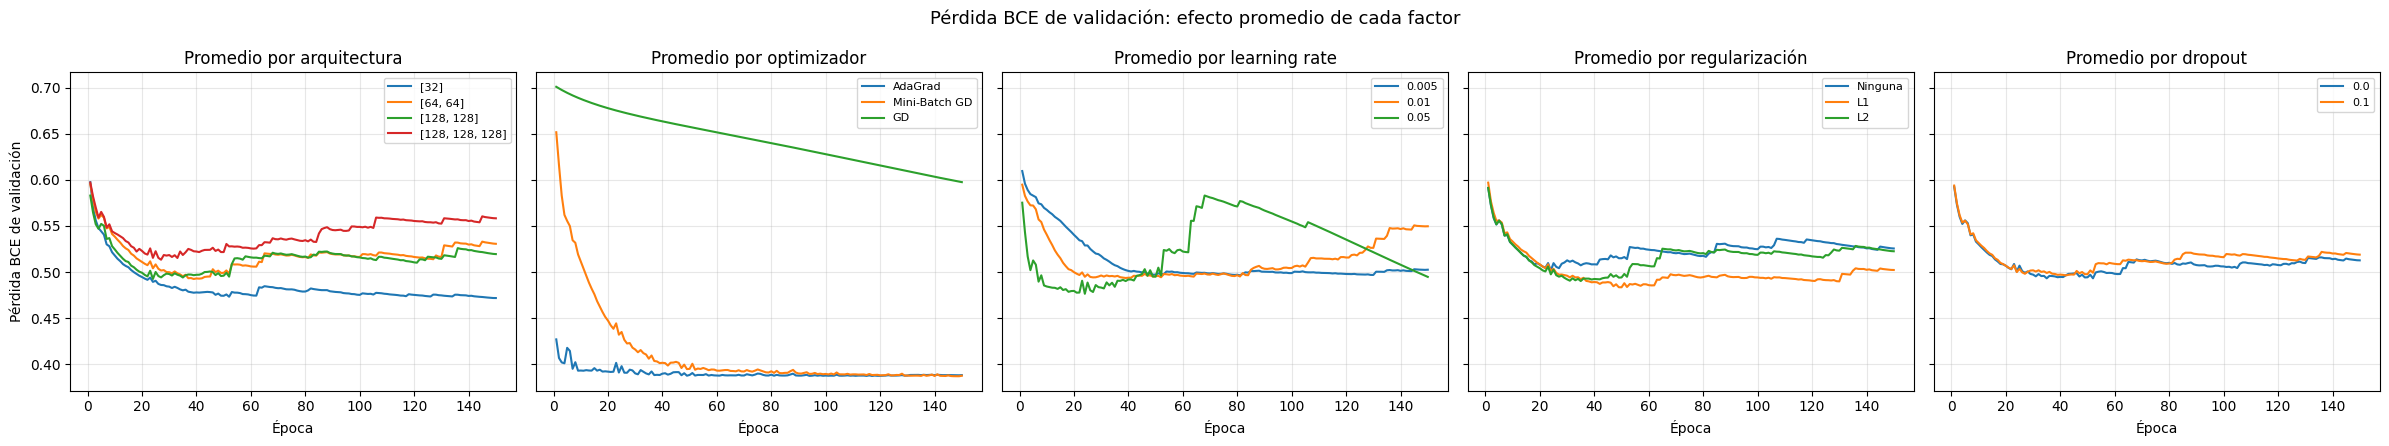

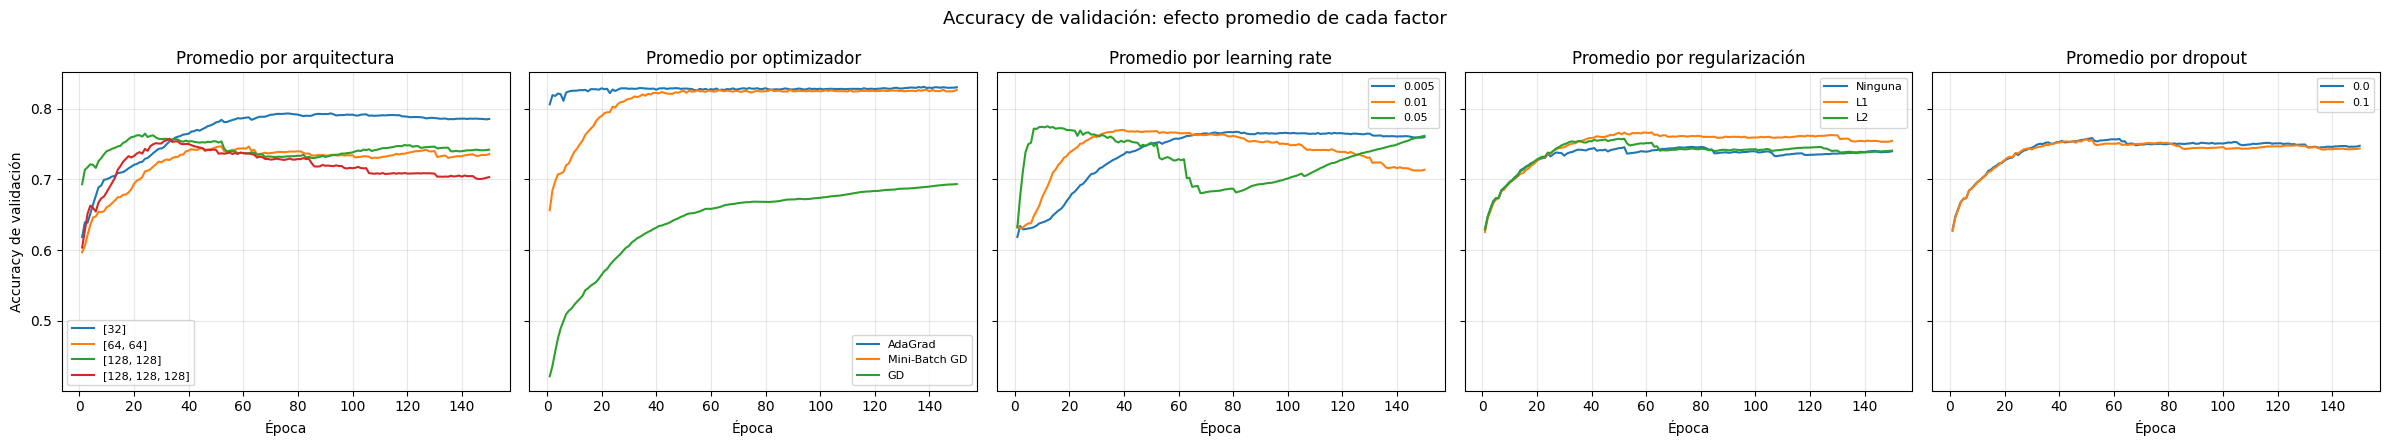

In [36]:
# ============================================================
# CURVAS PROMEDIO DE VALIDACIÓN POR NIVEL DE CADA FACTOR
# Como el early stopping corta las corridas en épocas distintas, en cada época se
# promedian solo las corridas que siguen activas.
# ============================================================
def curva_promedio(curvas):
    largo = max(len(c) for c in curvas)
    matriz = np.full((len(curvas), largo), np.nan)
    for i, c in enumerate(curvas):
        matriz[i, :len(c)] = c
    return np.nanmean(matriz, axis=0)


factores = {"Arquitectura": (0, list(final_architectures)), "Optimizador": (1, final_optimizers),
            "Learning rate": (2, final_learning_rates), "Regularización": (3, list(final_regularizations)),
            "Dropout": (4, final_dropouts)}

for metrica, etiqueta in (("val_loss", "Pérdida BCE de validación"), ("val_acc", "Accuracy de validación")):
    fig, axes = plt.subplots(1, 5, figsize=(24, 4.5), sharey=True)
    for ax, (nombre_factor, (pos, niveles)) in zip(axes, factores.items()):
        for nivel in niveles:
            curvas = [r["historial"][metrica] for c, r in final_results.items() if c[pos] == nivel]
            media = curva_promedio(curvas)
            ax.plot(range(1, len(media) + 1), media, label=str(nivel))
        ax.set_title(f"Promedio por {nombre_factor.lower()}")
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylabel(etiqueta)
    fig.suptitle(f"{etiqueta}: efecto promedio de cada factor", fontsize=13)
    fig.tight_layout()
    plt.show()

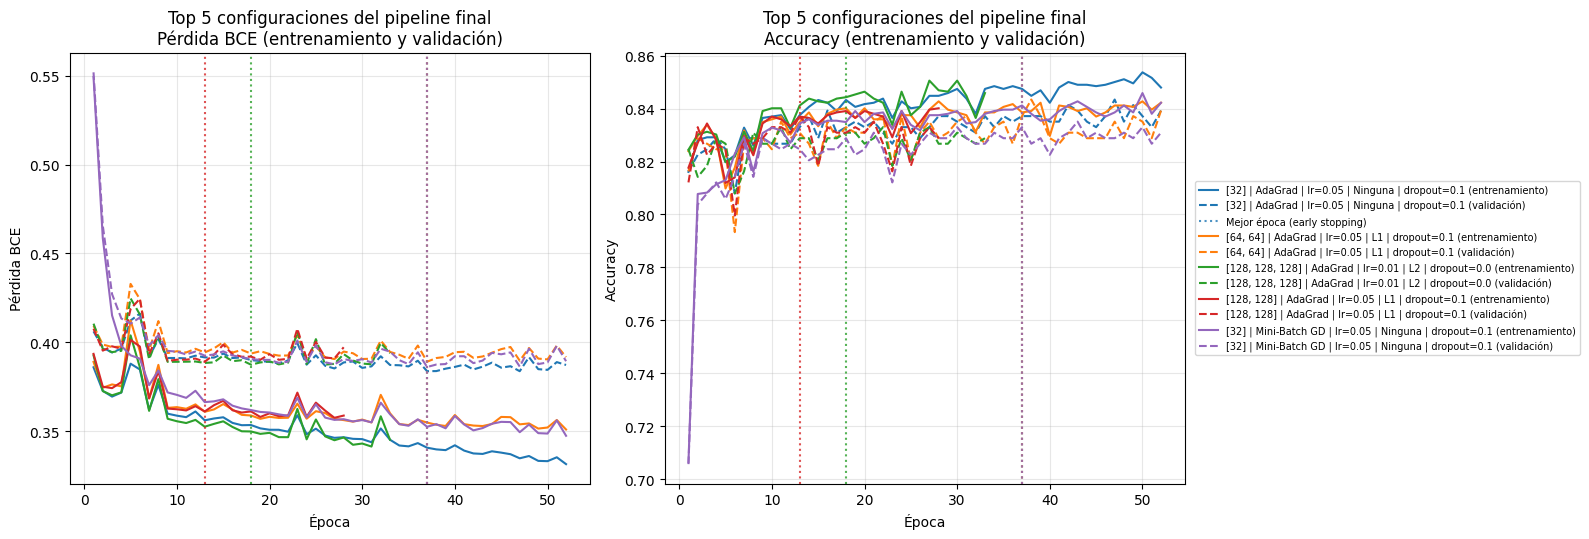

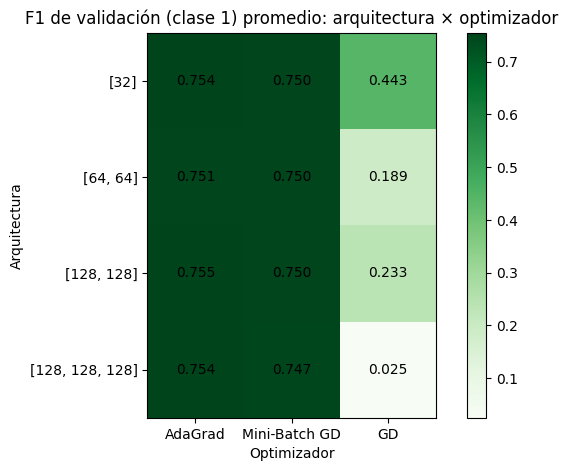

In [37]:
# ============================================================
# TOP 5 Y MAPA DE CALOR
# ============================================================
top5 = {}
for _, fila in final_df_ordenado.head(5).iterrows():
    clave = (fila["Arquitectura"], fila["Optimizador"], fila["Learning rate"], fila["Regularización"], fila["Dropout"])
    top5[final_results[clave]["nombre"]] = final_results[clave]
graficar_curvas(top5, "Top 5 configuraciones del pipeline final")

mapa = final_df.pivot_table(index="Arquitectura", columns="Optimizador",
                            values="F1 val (clase 1)", aggfunc="mean").reindex(list(final_architectures))[final_optimizers]
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(mapa.values, cmap="Greens")
ax.set_xticks(range(len(mapa.columns)), mapa.columns)
ax.set_yticks(range(len(mapa.index)), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f"{mapa.values[i, j]:.3f}", ha="center", va="center")
ax.set_xlabel("Optimizador")
ax.set_ylabel("Arquitectura")
ax.set_title("F1 de validación (clase 1) promedio: arquitectura × optimizador")
fig.colorbar(im, ax=ax)
plt.show()

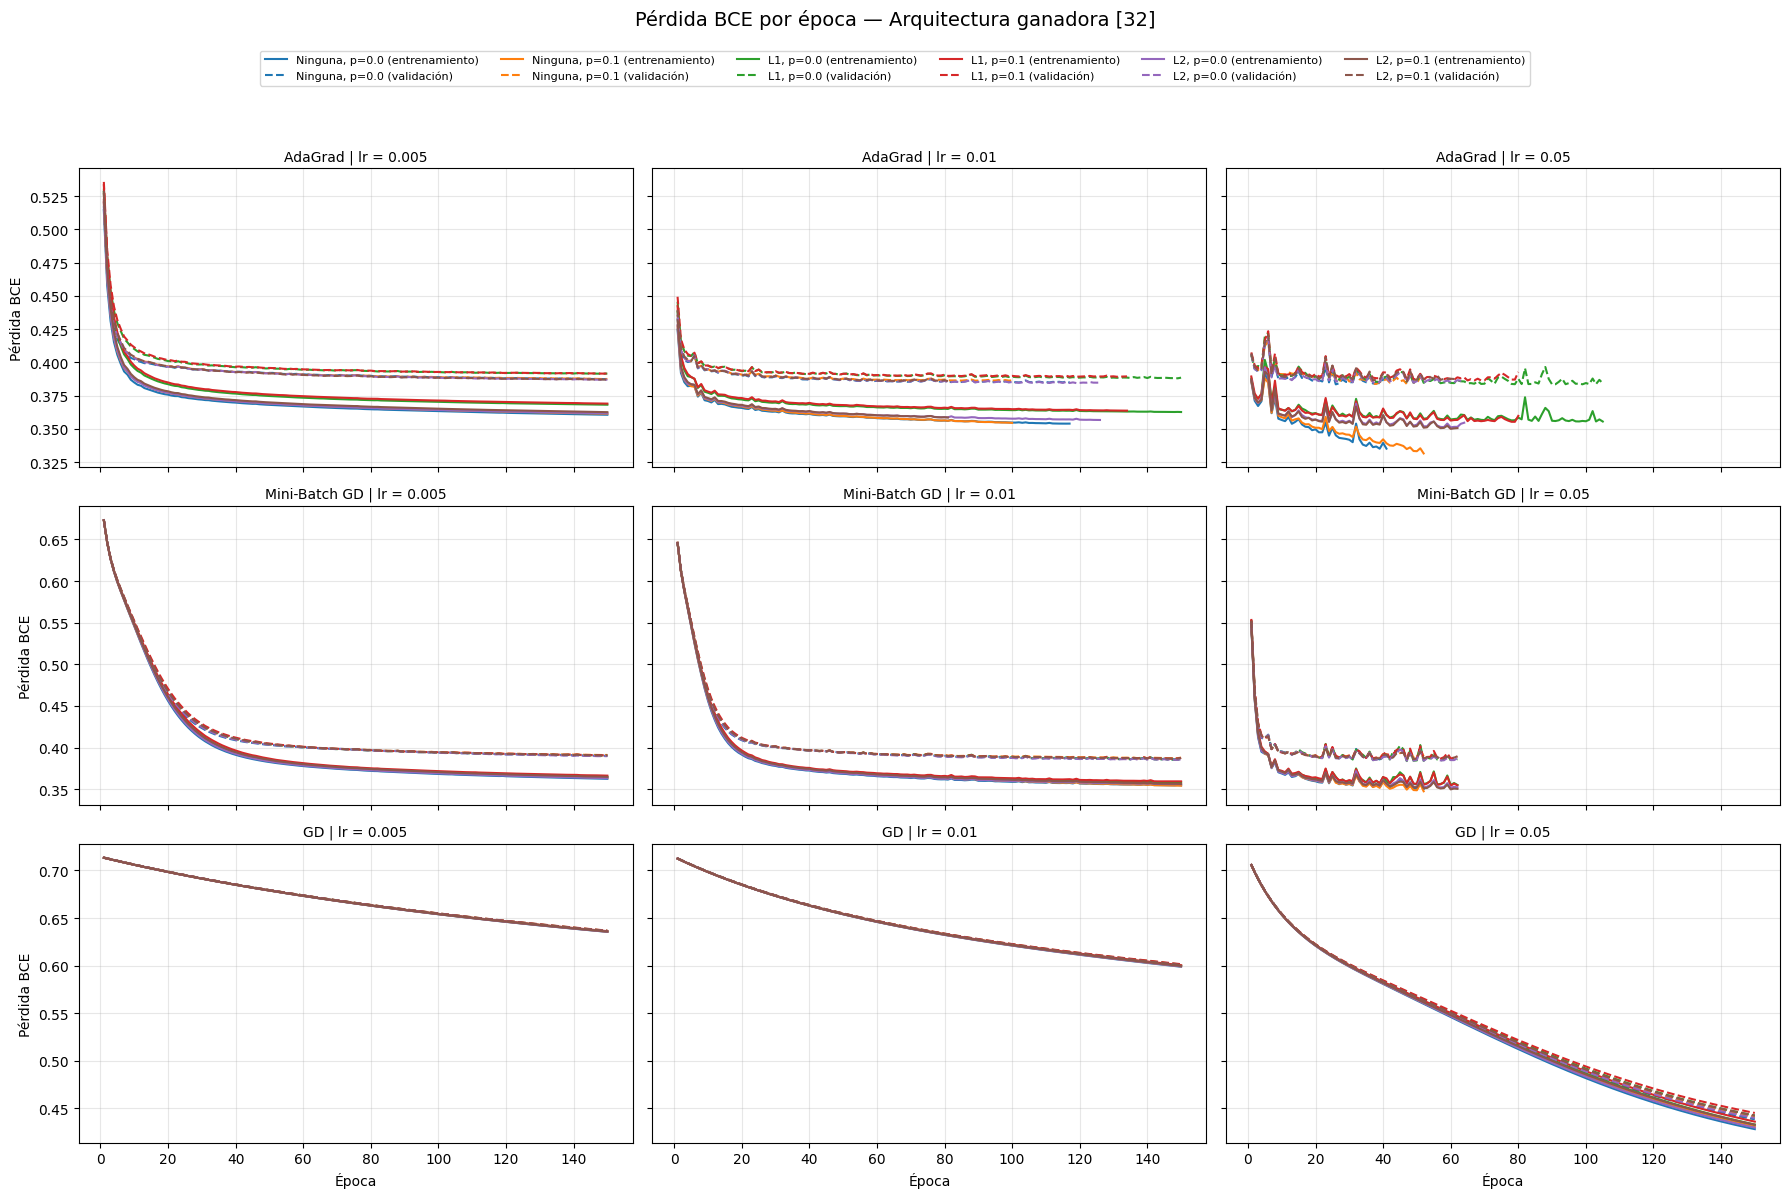

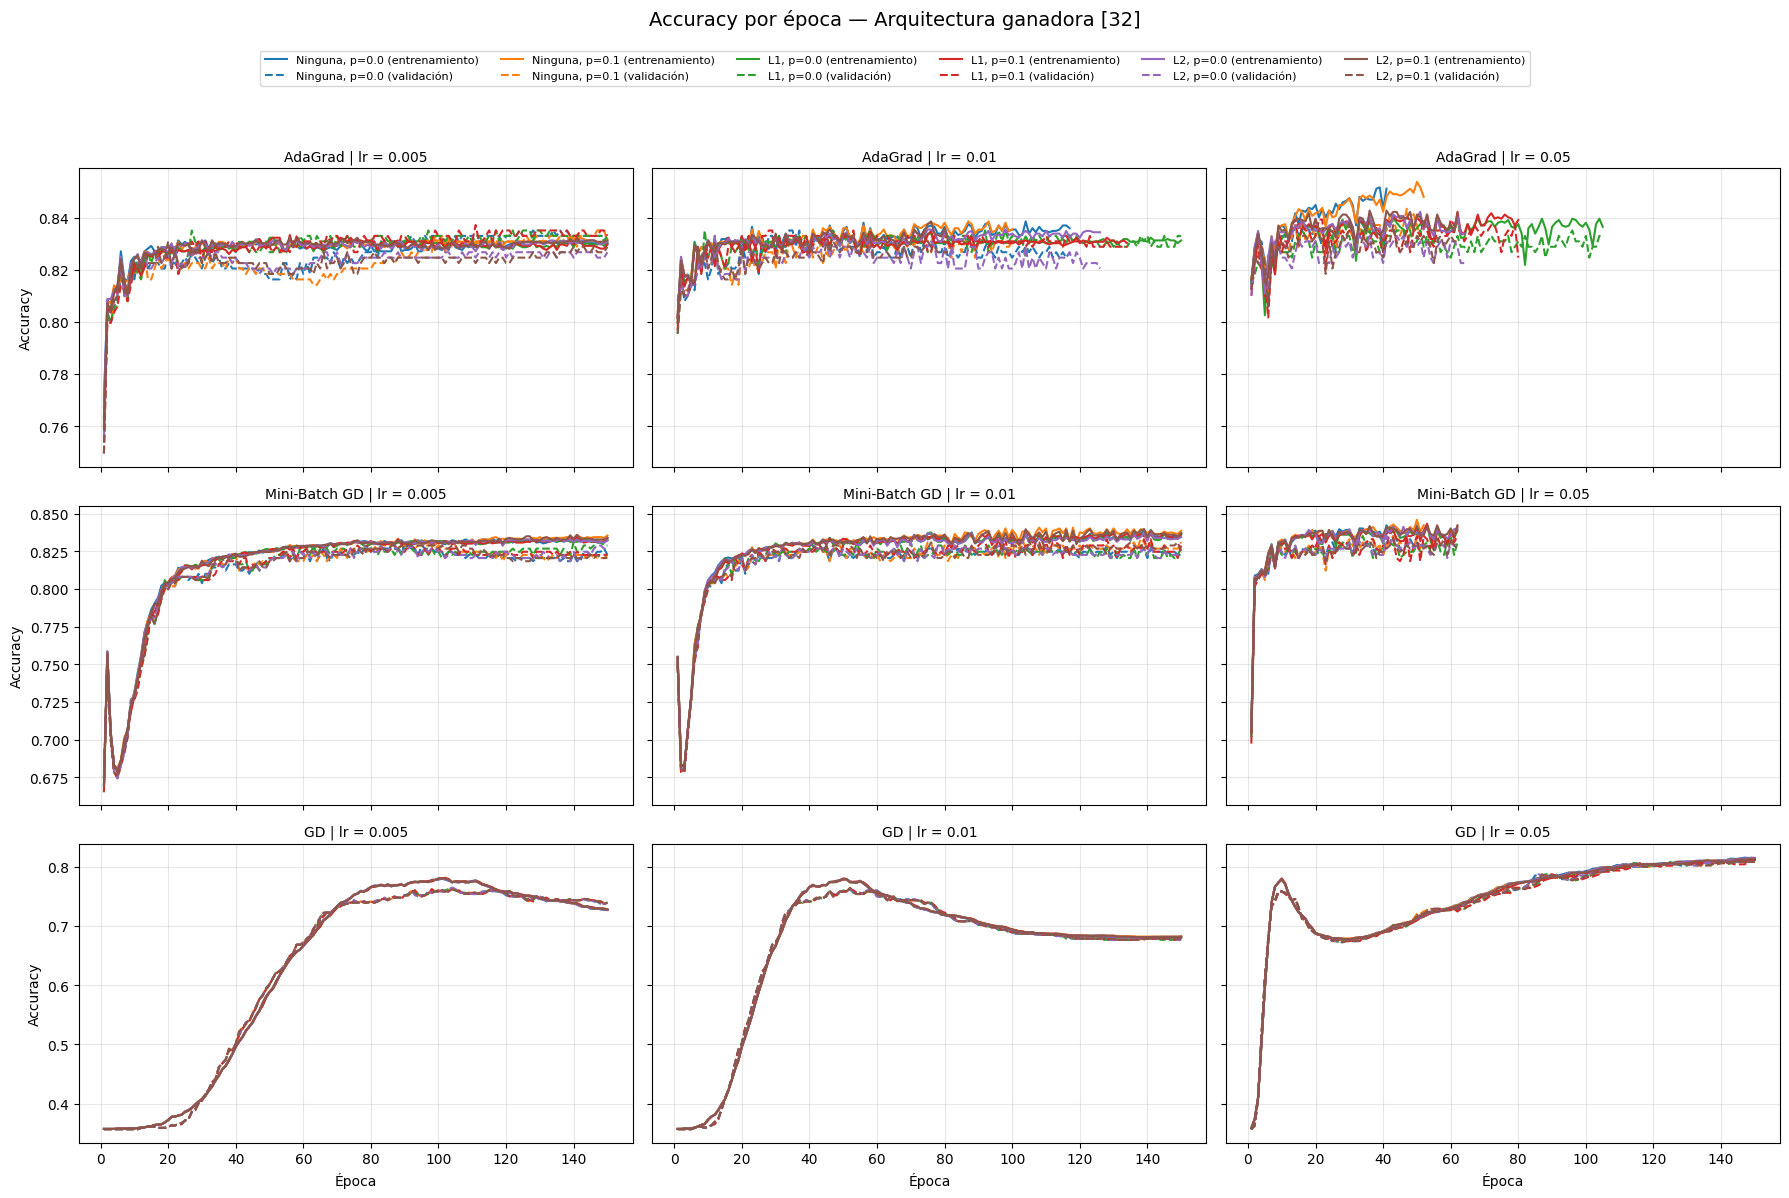

In [38]:
# ============================================================
# GRILLA DE CURVAS DE LA ARQUITECTURA GANADORA
# Filas = optimizador, columnas = learning rate
# ============================================================
mejor_fila = final_df_ordenado.iloc[0]
ARQ_GANADORA = mejor_fila["Arquitectura"]

for metrica, etiqueta in (("loss", "Pérdida BCE"), ("acc", "Accuracy")):
    fig, axes = plt.subplots(len(final_optimizers), len(final_learning_rates), figsize=(18, 12),
                             sharex=True, sharey="row")
    for i, opt in enumerate(final_optimizers):
        for j, lr in enumerate(final_learning_rates):
            ax = axes[i, j]
            k = 0
            for reg in final_regularizations:
                for p in final_dropouts:
                    h = final_results[(ARQ_GANADORA, opt, lr, reg, p)]["historial"]
                    ep = range(1, len(h[f"train_{metrica}"]) + 1)
                    ax.plot(ep, h[f"train_{metrica}"], color=f"C{k}", linestyle="-", label=f"{reg}, p={p} (entrenamiento)")
                    ax.plot(ep, h[f"val_{metrica}"], color=f"C{k}", linestyle="--", label=f"{reg}, p={p} (validación)")
                    k += 1
            ax.set_title(f"{opt} | lr = {lr}", fontsize=10)
            ax.grid(True, alpha=0.3)
            if i == len(final_optimizers) - 1:
                ax.set_xlabel("Época")
            if j == 0:
                ax.set_ylabel(etiqueta)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"{etiqueta} por época — Arquitectura ganadora {ARQ_GANADORA}", fontsize=14, y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

Configuración elegida: MLP [32] | AdaGrad | lr = 0.05 | Ninguna | dropout = 0.1


Ranking,Valor
Arquitectura,[32]
Optimizador,AdaGrad
Learning rate,0.05
Regularización,Ninguna
Dropout,0.1
Pérdida train,0.340856
Pérdida val,0.383844
Accuracy train,0.84744
Accuracy val,0.837161
F1 train (clase 1),0.782738



Configuraciones vecinas (la elegida y las que cambian un solo factor):


,Arquitectura,Optimizador,Learning rate,Regularización,Dropout,F1 val (clase 1),Recall val (clase 1),Accuracy val,Pérdida val,Brecha pérdida (val - train),Oscilación pérdida val,Parámetros
Ranking,,,,,,,,,,,,
1,[32],AdaGrad,0.050,Ninguna,0.1,0.7706,0.7661,0.8372,0.3838,0.0430,0.0043,1217
5,[32],Mini-Batch GD,0.050,Ninguna,0.1,0.7661,0.7661,0.8330,0.3862,0.0336,0.0076,1217
9,[32],AdaGrad,0.005,Ninguna,0.1,0.7642,0.7485,0.8351,0.3876,0.0260,0.0010,1217
12,[32],AdaGrad,0.050,L1,0.1,0.7633,0.7544,0.8330,0.3865,0.0306,0.0040,1217
17,[32],AdaGrad,0.050,L2,0.1,0.7625,0.7602,0.8309,0.3856,0.0334,0.0048,1217
25,"[64, 64]",AdaGrad,0.050,Ninguna,0.1,0.7602,0.7602,0.8288,0.3902,0.0469,0.0123,6593
47,"[128, 128, 128]",AdaGrad,0.050,Ninguna,0.1,0.7544,0.7544,0.8246,0.3863,0.0571,0.0169,37889
54,"[128, 128]",AdaGrad,0.050,Ninguna,0.1,0.7537,0.7427,0.8267,0.3915,0.0504,0.0132,21377
67,[32],AdaGrad,0.010,Ninguna,0.1,0.7508,0.7310,0.8267,0.3864,0.0304,0.0010,1217


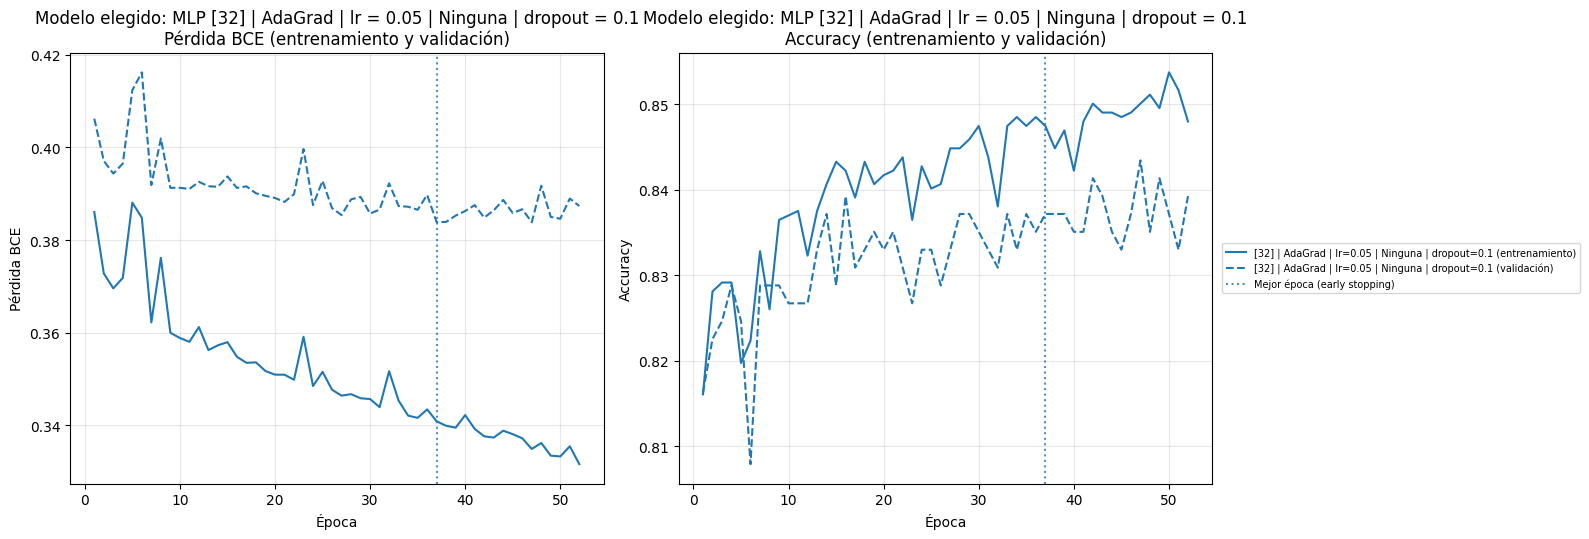

In [39]:
# ============================================================
# CONFIGURACIÓN ELEGIDA Y CONFIGURACIONES VECINAS
# (difieren de la elegida en un solo factor)
# ============================================================
clave_mejor = (mejor_fila["Arquitectura"], mejor_fila["Optimizador"], mejor_fila["Learning rate"],
               mejor_fila["Regularización"], mejor_fila["Dropout"])
res_final = final_results[clave_mejor]
NOMBRE_FINAL = (f"MLP {clave_mejor[0]} | {clave_mejor[1]} | lr = {clave_mejor[2]} | "
                f"{clave_mejor[3]}" + (f" (λ = {final_regularizations[clave_mejor[3]]:g})" if clave_mejor[3] != "Ninguna" else "")
                + f" | dropout = {clave_mejor[4]}")
print("Configuración elegida:", NOMBRE_FINAL)
display(final_df_ordenado.head(1).T.rename(columns={1: "Valor"}))

columnas_clave = ["Arquitectura", "Optimizador", "Learning rate", "Regularización", "Dropout"]
es_vecina = final_df[columnas_clave].ne(pd.Series(clave_mejor, index=columnas_clave)).sum(axis=1) <= 1
vecinas = final_df[es_vecina].copy()
vecinas["Ranking"] = [int(final_df_ordenado.index[
    (final_df_ordenado[columnas_clave] == fila[columnas_clave].values).all(axis=1)][0]) for _, fila in vecinas.iterrows()]
print("\nConfiguraciones vecinas (la elegida y las que cambian un solo factor):")
display(vecinas[columnas_clave + ["Ranking", "F1 val (clase 1)", "Recall val (clase 1)", "Accuracy val",
                                  "Pérdida val", "Brecha pérdida (val - train)", "Oscilación pérdida val",
                                  "Parámetros"]].sort_values("Ranking").set_index("Ranking").round(4))

graficar_curvas(res_final, f"Modelo elegido: {NOMBRE_FINAL}")

**Observación → Decisión**

**Hallazgos por factor**

- **Optimizador:** el GD de batch completo es el factor que más pesa. **38 de sus 72 corridas** no salen de predecir solo la clase 0 (F1 = 0), y solo con lr = 0.05 logra resultados razonables (F1 de hasta 0.7094). Por eso los promedios de la Tabla 3 tienen desviaciones estándar tan grandes. AdaGrad (F1 medio de 0.7536) y Mini-Batch GD (0.7492) son casi equivalentes y muy estables (desviación estándar de 0.008 y 0.007).
- **Sin contar el GD** (144 corridas), los demás factores mueven muy poco el resultado: el F1 medio por arquitectura va de 0.7506 a 0.7522; lr = 0.05 es algo mejor (0.7548 frente a ≈ 0.750); sin regularización 0.7531, L2 0.7523 y L1 0.7488; dropout 0.1 0.7537 frente a 0.7491 sin dropout. Todo el rango de F1 de estas corridas va de 0.7368 a 0.7706, y **25 configuraciones superan 0.76**.
- **Capacidad:** las redes grandes no ganan. Entre las vecinas de la elegida, `[64, 64]`, `[128, 128]` y `[128, 128, 128]` tienen más brecha (0.047 a 0.057) y más oscilación de la pérdida de validación (0.012 a 0.017) que `[32]` (0.043 y 0.004).

**Configuración elegida: MLP `[32]` | AdaGrad | lr = 0.05 | sin regularización L1/L2 | dropout = 0.1** (mejor época 37, parada en la 52). Se justifica con más criterios que la accuracy de validación:

1. **F1 y recall de la clase 1:** tiene el mayor F1 de validación (0.7706), con recall de 0.7661 y precision de 0.7751. Empata en F1 con `[64, 64]` + L1 y gana el desempate por su menor pérdida de validación (0.3838 frente a 0.3892).
2. **Pérdida de validación:** 0.3838 está por debajo del promedio de las corridas sin GD (≈ 0.386), así que el alto F1 no viene de probabilidades mal calibradas.
3. **Estabilidad de las curvas:** la oscilación media de la pérdida de validación hasta la mejor época es 0.0043, menor que la de sus vecinas de mayor capacidad (0.012 a 0.017), y las curvas no muestran el deterioro posterior que se ve en redes grandes.
4. **Brecha entre entrenamiento y validación:** 0.0430 en pérdida y 0.0103 en accuracy. Es moderada y menor que la de sus vecinas de mayor capacidad.
5. **Parsimonia:** con **1217 parámetros** es la red más pequeña del grid, 31 veces más pequeña que `[128, 128, 128]`.
6. **Robustez frente a configuraciones vecinas:** cambiar un solo factor (lr, regularización, optimizador o arquitectura) da un F1 entre 0.7508 y 0.7661 en casi todos los casos. El modelo está en una zona estable del espacio de búsqueda y no es un pico aislado. La excepción es pasar a GD (0.7051), por la falta de actualizaciones. Quitar el dropout baja el F1 a 0.7492 aunque la pérdida queda igual (0.3835).

**Advertencia:** la ventaja del modelo elegido sobre las siguientes configuraciones es de 1 o 2 estudiantes de validación bien clasificados. Elegir el máximo entre 216 corridas introduce un **sesgo de selección** optimista, y eso se analiza con el conjunto de prueba en la siguiente sección.

## Evaluación final en prueba

Esta es la **única sección que usa el conjunto de prueba**. Los tres modelos ya están entrenados con `X_train_exp`; aquí solo se evalúan una vez:

- **Perceptrón** (referencia lineal);
- **Red básica [32]**;
- **Modelo final**, el mejor del pipeline, con el umbral de decisión elegido en validación si se adoptó ese ajuste.

In [40]:
# ============================================================
# UMBRAL DEL MODELO FINAL (se elige en VALIDACIÓN, nunca en prueba)
# ============================================================
if USAR_UMBRAL:
    f1_umbral = [evaluar(res_final["modelo"], X_val, y_val, u)["f1"] for u in umbrales]
    UMBRAL_FINAL = float(umbrales[int(np.argmax(f1_umbral))])
else:
    UMBRAL_FINAL = 0.5
print(f"Umbral de decisión del modelo final (elegido en validación): {UMBRAL_FINAL}")

# ============================================================
# CONJUNTO DE PRUEBA: se usa aquí por primera y única vez
# ============================================================
X_test_tensor = CONJUNTOS[ESTRATEGIA_ELEGIDA]["X_test"]
y_test_tensor = CONJUNTOS[ESTRATEGIA_ELEGIDA]["y_test"]

modelos_finales = {
    "Perceptrón": (res_perceptron_ref, 0.5),
    "Red básica [32]": (res_basica_ref, 0.5),
    "Modelo final": (res_final, UMBRAL_FINAL),
}
if UMBRAL_FINAL != 0.5:
    modelos_finales["Modelo final (umbral 0.5)"] = (res_final, 0.5)

conjuntos_eval = {"Train": (X_train_exp, y_train_exp), "Validación": (X_val, y_val),
                  "Prueba": (X_test_tensor, y_test_tensor)}
metricas_finales = {nombre: {c: evaluar(r["modelo"], Xc, yc, u) for c, (Xc, yc) in conjuntos_eval.items()}
                    for nombre, (r, u) in modelos_finales.items()}

filas = {}
for nombre, (r, u) in modelos_finales.items():
    fila = {}
    for c in conjuntos_eval:
        m = metricas_finales[nombre][c]
        for etiqueta, clave in (("Accuracy", "accuracy"), ("Pérdida", "loss"), ("Precision", "precision"),
                                ("Recall", "recall"), ("F1", "f1"), ("AUC", "auc")):
            fila[(c, etiqueta)] = m[clave]
    fila[("Modelo", "Parámetros")] = r["parametros"]
    fila[("Modelo", "Mejor época")] = r["mejor_epoca"]
    fila[("Modelo", "Umbral")] = u
    filas[nombre] = fila
tabla_final = pd.DataFrame(filas).T
tabla_final.columns = pd.MultiIndex.from_tuples(tabla_final.columns)
tabla_final.index.name = "Modelo"
print("Tabla comparativa final (precision, recall y F1 de la clase 1)")
display(tabla_final.round(4))
print("Celdas vacías:", int(tabla_final.isna().sum().sum()))
print(f"\nModelo final: {NOMBRE_FINAL}")

Umbral de decisión del modelo final (elegido en validación): 0.4
Tabla comparativa final (precision, recall y F1 de la clase 1)


Train                                           Validación                                             Prueba                                               Modelo                   
                          Accuracy Pérdida Precision  Recall      F1     AUC   Accuracy Pérdida Precision  Recall      F1     AUC Accuracy Pérdida Precision  Recall      F1     AUC Parámetros Mejor época Umbral
Modelo                                                                                                                                                                                                            
Perceptrón                  0.8302  0.3689    0.7909  0.7135  0.7502  0.9061     0.8288  0.3915    0.7799  0.7251  0.7515  0.8919   0.8280  0.3724    0.7681  0.7430  0.7553  0.9022       37.0       149.0    0.5
Red básica [32]             0.8333  0.3549    0.7987  0.7135  0.7537  0.9131     0.8225  0.3857    0.7722  0.7135  0.7416  0.8969   0.8214  0.3764    0.7560  0.7383  0.7470  0.9017     1217.0       149.0    0.5
Modelo final                0.8380  0.3409    0.7416  0.8392  0.7874  0.9209     0.8413  0.3838    0.7513  0.8304  0.7889  0.8987   0.8080  0.3842    0.6972  0.8178  0.7527  0.8992     1217.0        37.0    0.4
Modelo final (umbral 0.5)   0.8474  0.3409    0.7970  0.7690  0.7827  0.9209     0.8372  0.3838    0.7751  0.7661  0.7706  0.8987   0.8164  0.3842    0.7261  0.7804  0.7523  0.8992     1217.0        37.0    0.5

Celdas vacías: 0

Modelo final: MLP [32] | AdaGrad | lr = 0.05 | Ninguna | dropout = 0.1


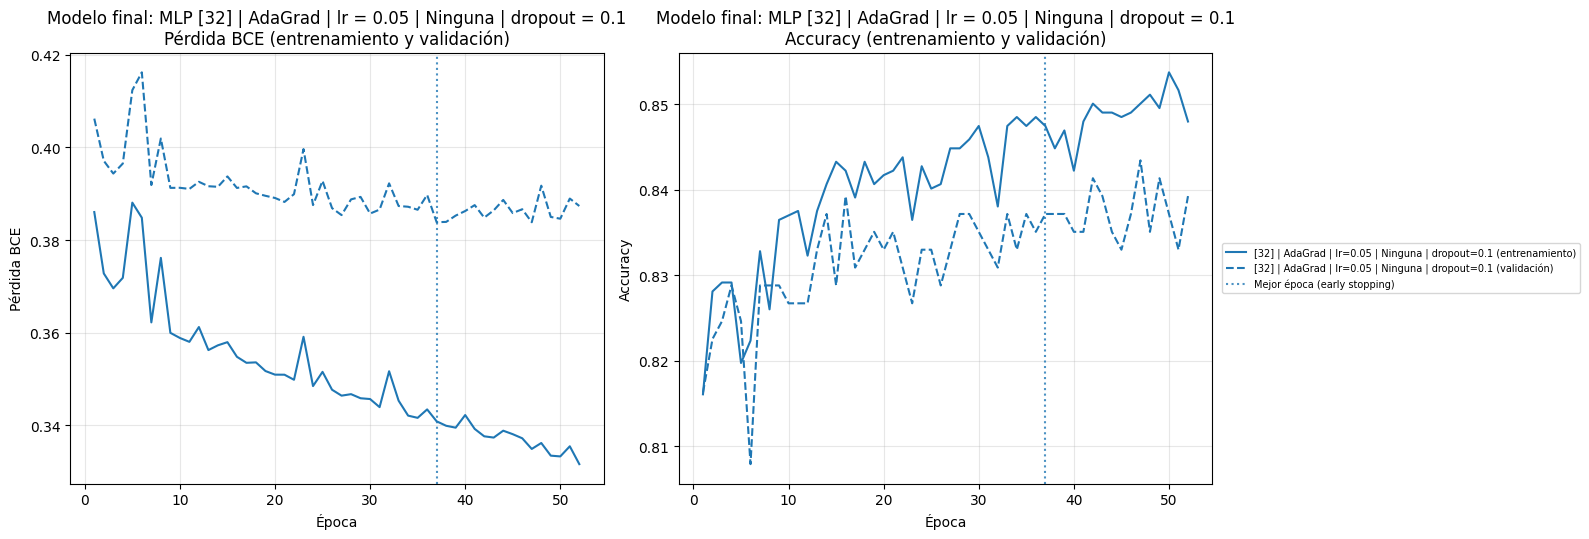

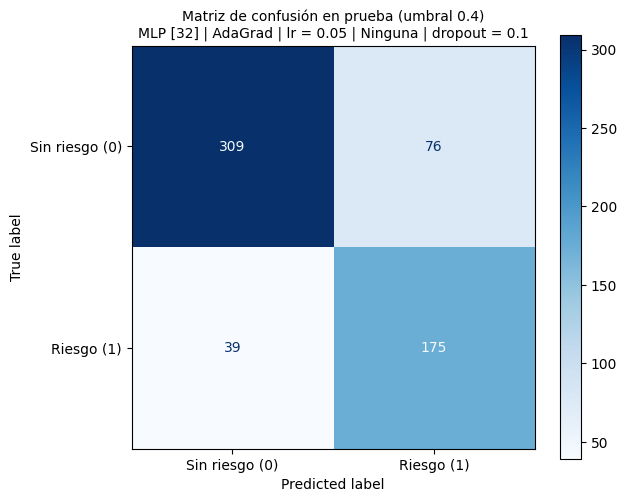

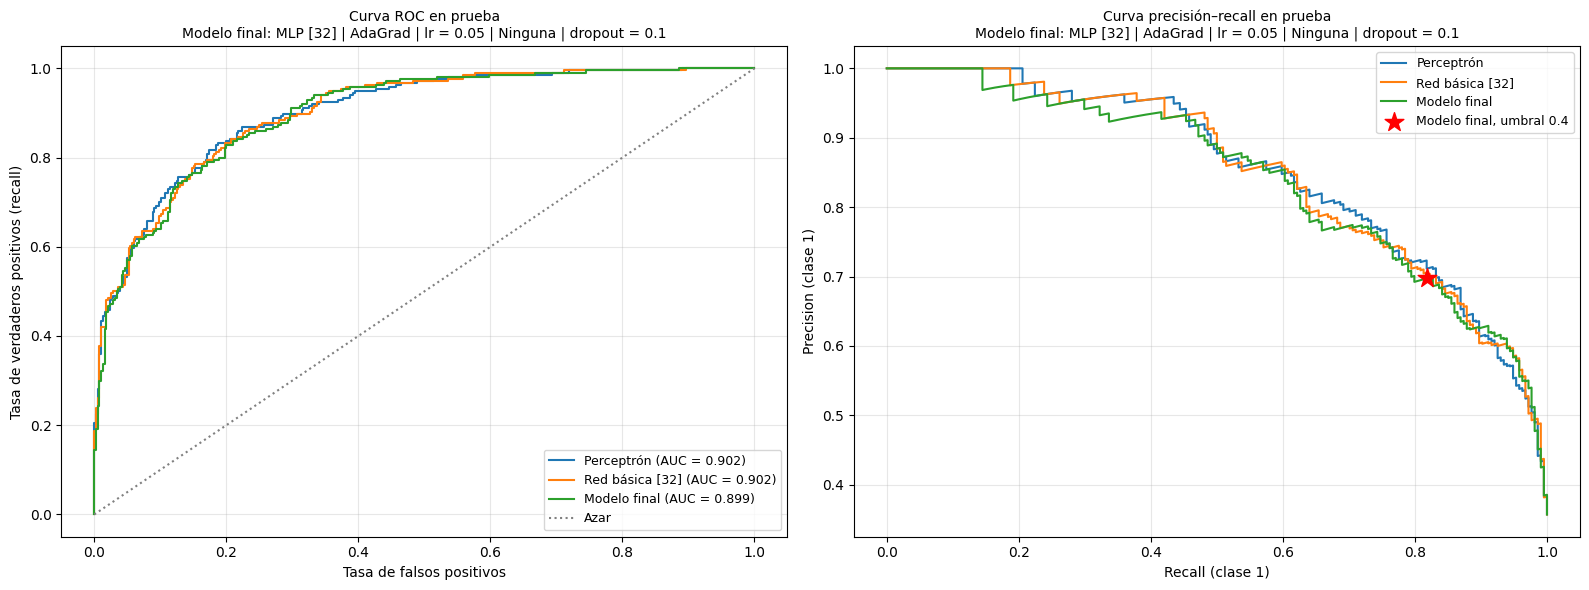

Reporte de clasificación en prueba — MLP [32] | AdaGrad | lr = 0.05 | Ninguna | dropout = 0.1 (umbral 0.4)
                precision    recall  f1-score   support

Sin riesgo (0)     0.8879    0.8026    0.8431       385
    Riesgo (1)     0.6972    0.8178    0.7527       214

      accuracy                         0.8080       599
     macro avg     0.7926    0.8102    0.7979       599
  weighted avg     0.8198    0.8080    0.8108       599



In [41]:
# ============================================================
# GRÁFICAS DEL MODELO REPORTADO
# ============================================================
graficar_curvas(res_final, f"Modelo final: {NOMBRE_FINAL}")

m_test = metricas_finales["Modelo final"]["Prueba"]
y_test_np = y_test_tensor.view(-1).numpy().astype(int)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test_np, m_test["pred"], display_labels=["Sin riesgo (0)", "Riesgo (1)"],
                                        cmap="Blues", ax=ax)
ax.set_title(f"Matriz de confusión en prueba (umbral {UMBRAL_FINAL})\n{NOMBRE_FINAL}", fontsize=10)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for nombre in ("Perceptrón", "Red básica [32]", "Modelo final"):
    proba = metricas_finales[nombre]["Prueba"]["proba"]
    fpr, tpr, _ = roc_curve(y_test_np, proba)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {metricas_finales[nombre]['Prueba']['auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test_np, proba)
    axes[1].plot(rec, prec, label=nombre)
axes[0].plot([0, 1], [0, 1], color="gray", linestyle=":", label="Azar")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[0].set_title(f"Curva ROC en prueba\nModelo final: {NOMBRE_FINAL}", fontsize=10)
axes[1].scatter(m_test["recall"], m_test["precision"], color="red", marker="*", s=200, zorder=5,
                label=f"Modelo final, umbral {UMBRAL_FINAL}")
axes[1].set_xlabel("Recall (clase 1)")
axes[1].set_ylabel("Precision (clase 1)")
axes[1].set_title(f"Curva precisión–recall en prueba\nModelo final: {NOMBRE_FINAL}", fontsize=10)
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"Reporte de clasificación en prueba — {NOMBRE_FINAL} (umbral {UMBRAL_FINAL})")
print(classification_report(y_test_np, m_test["pred"], target_names=["Sin riesgo (0)", "Riesgo (1)"], digits=4))

## Discusión final

### Comparación honesta con el perceptrón

En el conjunto de prueba (599 estudiantes, evaluado una sola vez):

| Modelo | Accuracy | Pérdida | Precision (1) | Recall (1) | F1 (1) | AUC | Parámetros |
|---|---|---|---|---|---|---|---|
| Perceptrón | **0.8280** | **0.3724** | **0.7681** | 0.7430 | **0.7553** | **0.9022** | 37 |
| Red básica `[32]` | 0.8214 | 0.3764 | 0.7560 | 0.7383 | 0.7470 | 0.9017 | 1217 |
| Modelo final (umbral 0.40) | 0.8080 | 0.3842 | 0.6972 | **0.8178** | 0.7527 | 0.8992 | 1217 |
| Modelo final (umbral 0.5) | 0.8164 | 0.3842 | 0.7261 | 0.7804 | 0.7523 | 0.8992 | 1217 |

**El perceptrón iguala o supera al modelo elegido** en accuracy, pérdida, F1 y AUC. El modelo final solo gana en recall (0.8178 frente a 0.7430), principalmente gracias al umbral de 0.40, a cambio de bajar la precision (0.6972 frente a 0.7681). Esto merece análisis:

1. **Relación casi lineal y circularidad parcial.** La etiqueta se construyó con k-means sobre el PHQ-9, y las entradas incluyen escalas muy cercanas: PSS-10 (estrés), GAD-7 (ansiedad) y la pregunta 12 (qué tan deprimido se sintió ayer). Una combinación lineal de estas escalas puede reproducir casi toda la frontera de decisión, así que un modelo lineal ya captura casi toda la señal (AUC de 0.90) y las capas ocultas tienen poco que aportar. En todo el notebook, la red básica mejora la pérdida de validación del perceptrón en menos de 0.006 (0.3869 frente a 0.3908, y 0.3857 frente a 0.3915 en los modelos de referencia).
2. **Sesgo de selección.** El modelo final se eligió como el mejor de **216 configuraciones** con un único conjunto de validación de 479 muestras, y después se ajustó su umbral sobre ese mismo conjunto. Su F1 de validación (0.7706 con umbral 0.5 y 0.7889 con 0.40) cae en prueba a 0.7523 y 0.7527. El perceptrón, que no pasó por ninguna selección, mantiene su desempeño (F1 de 0.7515 en validación y 0.7553 en prueba). Gran parte de la ventaja que la red mostraba en validación era ruido seleccionado, no una mejor capacidad de generalizar.

### Brecha entre validación y prueba

| Modelo | Accuracy val → prueba | F1 val → prueba |
|---|---|---|
| Perceptrón | 0.8288 → 0.8280 (−0.1 pp) | 0.7515 → 0.7553 |
| Red básica `[32]` | 0.8225 → 0.8214 (−0.1 pp) | 0.7416 → 0.7470 |
| Modelo final (umbral 0.40) | 0.8413 → 0.8080 (−3.3 pp) | 0.7889 → 0.7527 |

Los modelos de referencia, que no se eligieron entre muchas alternativas, generalizan igual en validación y en prueba. Solo el modelo que se seleccionó y se le ajustó el umbral en validación pierde desempeño, que es lo que se espera si hay sesgo de selección. Su AUC casi no cambia (0.8987 → 0.8992), así que su capacidad de ordenar a los estudiantes por riesgo se mantiene. Lo que estaba sobreajustado a validación es el punto de corte.

### Qué técnica resolvió cada problema detectado

| Problema detectado | Técnica aplicada | Efecto observado |
|---|---|---|
| Fuga de información: el escalador veía las filas de validación | Split de validación antes de escalar; escalador ajustado solo con `X_train_exp` | La validación ya no está contaminada (corrección metodológica) |
| Resultados no reproducibles (baseline de Keras sin semilla) | PyTorch en todo el notebook, `fijar_semilla`, mismos pesos iniciales y mismo orden de batches | Todas las corridas parten de condiciones idénticas; por eso `BCEWithLogitsLoss` y `BCELoss` dan resultados idénticos |
| Variables en escalas muy distintas (`anio_nac` ≈ 2000) | Escalado `minmax_completo` | Sin escalar: F1 = 0 y pérdida de 0.6518. Escalado: pérdida de validación de 0.3857 |
| Sobreajuste al entrenar demasiadas épocas | Early stopping con restauración de pesos | `[128, 128, 128]`: brecha de 0.1622 → 0.0177; pérdida de validación de 0.4275 → 0.3922 |
| GD de batch completo sin avance (1 actualización por época) | Mini-batch (60 actualizaciones por época) u optimizadores adaptativos | GD: F1 = 0 con lr ≤ 0.01. Mini-batch o AdaGrad: F1 ≈ 0.75 |
| Inestabilidad con learning rate alto | Barrido de learning rate | lr = 0.1: mejor época 12; lr = 0.05: mejor pérdida de validación (0.3861) |
| Brecha entre entrenamiento y validación en redes grandes | L1/L2 (λ = 1e-3) y dropout | Brecha de 0.0345 → 0.0265 (L1) y 0.0274 (dropout 0.1). Mejora de pérdida ≤ 0.0014 |
| Recall bajo de la clase en riesgo | Umbral de decisión ajustado en validación | Validación: recall 0.7193 → 0.8246. Prueba: 0.7804 → 0.8178 (precision 0.7261 → 0.6972) |

### Oportunidades de mejora

1. **Validación cruzada estratificada (k = 5 o 10)** para elegir la configuración y el umbral, en lugar de un único conjunto de validación de 479 muestras. Así se reduce el sesgo de selección que se observó entre validación y prueba.
2. **Reportar incertidumbre:** repetir los mejores modelos con varias semillas y calcular intervalos de confianza por *bootstrap* en prueba. Con este tamaño de muestra, diferencias de 0.01 en F1 no son concluyentes.
3. **Búsqueda más pequeña y dirigida:** cada configuración adicional aumenta el riesgo de quedarse con un resultado favorecido por el ruido. Una búsqueda aleatoria o bayesiana sobre pocos factores (learning rate y optimizadores adaptativos) reduciría ese riesgo y el costo de cómputo. El GD de batch completo puede descartarse.
4. **Calibración de probabilidades y umbral según el costo de los errores:** calibrar las probabilidades (Platt o isotónica) y definir el umbral junto con profesionales de bienestar, según el costo relativo de un falso negativo frente a un falso positivo, en lugar de maximizar el F1.
5. **Comparar con modelos lineales regularizados y de árboles** (regresión logística con L1/L2, *gradient boosting*). Como el perceptrón ya alcanza el desempeño de la red, conviene saber si un modelo más interpretable es suficiente para apoyar la detección temprana. También conviene validar el modelo con datos de otra cohorte o universidad.

**Respuesta a la pregunta de investigación.** Las variables de comportamiento, bienestar, estrés y ansiedad permiten detectar el riesgo de depresión con una AUC cercana a 0.90 en datos no vistos. Con el umbral ajustado, el modelo final identifica al 81.8 % de los estudiantes en riesgo del conjunto de prueba. Sin embargo, gran parte de esta señal es lineal y está cerca de los instrumentos con los que se construyó la etiqueta, así que el desempeño debe interpretarse con cautela y el modelo debe usarse como apoyo, no como reemplazo del criterio profesional.